# Google Play Store Apps — Exploratory Data Analysis (EDA)

**Libraries used:** `pandas` · `numpy` · `matplotlib` · `seaborn`

This notebook explores two datasets scraped from the Google Play Store (2018):

| File | What it has |
|---|---|
| `googleplaystore.csv` | ~10,800 apps: category, rating, reviews, size, installs, price, content rating, last updated … |
| `googleplaystore_user_reviews.csv` | ~64,000 user reviews with sentiment scores |

### How this notebook is organised
Every step is numbered so you can find it quickly:

| Prefix | Library | Meaning |
|---|---|---|
| `P01, P02 …` | **pandas** | loading, cleaning, feature engineering, grouping, merging |
| `N01, N02 …` | **numpy** | statistics, math, arrays, random sampling |
| `M01, M02 …` | **matplotlib** | charts and chart customisation |
| `S01, S02 …` | **seaborn** | statistical charts |

> Each section has **more than 35 separate operations**. Every operation has a short explanation in simple English, then the code.

**Data license:** Creative Commons Attribution 3.0 (see `data/license.txt`).

## 0. Setup — import libraries

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# folders for saved charts / cleaned data
os.makedirs("images", exist_ok=True)
os.makedirs("data", exist_ok=True)

# pandas display options
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

def save_fig(name):
    """Save the current figure into the images/ folder and show it."""
    plt.savefig(f"images/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("matplotlib:", mpl.__version__)
print("seaborn   :", sns.__version__)

pandas    : 2.3.3
numpy     : 2.3.5
matplotlib: 3.10.6
seaborn   : 0.13.2


---

<img src="icons/section_pandas.png" alt="Pandas section banner" width="700">

# 1. 🐼 PANDAS — load, inspect, clean, transform, analyse

### 1.1 Loading and first look

#### P01 · Read the apps CSV file
`pd.read_csv()` loads a CSV file into a DataFrame (a table).

In [2]:
apps = pd.read_csv("data/googleplaystore.csv")

#### P02 · Read the reviews CSV file
Same function, second file.

In [3]:
reviews = pd.read_csv("data/googleplaystore_user_reviews.csv")

#### P03 · Check the shape
`.shape` gives (rows, columns).

In [4]:
print("Apps data   :", apps.shape)
print("Reviews data:", reviews.shape)

Apps data   : (10841, 13)
Reviews data: (64295, 5)


#### P04 · First rows with head()
`.head()` shows the first 5 rows.

In [5]:
apps.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


#### P05 · Last rows with tail()
`.tail()` shows the last 5 rows.

In [6]:
apps.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.50,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.00,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.50,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.50,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


#### P06 · Column information with info()
`.info()` shows column names, data types and non-null counts.

In [7]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


#### P07 · Data types with dtypes
Almost everything is text (`str`). Reviews, Size, Installs and Price should be numbers — we will fix that.

In [8]:
apps.dtypes

App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

#### P08 · Numeric summary with describe()
Count, mean, std, min, quartiles and max for number columns.

In [9]:
apps.describe()

,Rating
count,"9,367.00"
mean,4.19
std,0.54
min,1.00
25%,4.00
50%,4.30
75%,4.50
max,19.00


#### P09 · Text summary with select_dtypes() + describe()
`select_dtypes(exclude='number')` picks the non-number columns, then `describe()` shows unique counts and the most common value.

In [10]:
apps.select_dtypes(exclude="number").describe()

,App,Category,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841,10841,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,9660,34,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1972,596,1695,1579,10039,10040,8714,842,326,1459,2451


#### P10 · List column names
`.columns.tolist()` returns the column names as a Python list.

In [11]:
apps.columns.tolist()

['App',
 'Category',
 'Rating',
 'Reviews',
 'Size',
 'Installs',
 'Type',
 'Price',
 'Content Rating',
 'Genres',
 'Last Updated',
 'Current Ver',
 'Android Ver']

#### P11 · Count missing values with isnull().sum()
`isnull()` marks missing cells as True. `sum()` counts them per column.

In [12]:
apps.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

#### P12 · Missing values in percent
`isnull().mean()` gives the share of missing values. Multiply by 100 for percent.

In [13]:
(apps.isnull().mean() * 100).round(2).sort_values(ascending=False)

Rating           13.60
Current Ver       0.07
Android Ver       0.03
Type              0.01
Content Rating    0.01
App               0.00
Category          0.00
Reviews           0.00
Size              0.00
Installs          0.00
Price             0.00
Genres            0.00
Last Updated      0.00
dtype: float64

#### P13 · Count duplicate rows
`duplicated()` marks repeated rows. `sum()` counts them.

In [14]:
print("Fully duplicated rows        :", apps.duplicated().sum())
print("Rows with a repeated app name:", apps["App"].duplicated().sum())

Fully duplicated rows        : 483
Rows with a repeated app name: 1181


#### P14 · Unique values per column with nunique()
Shows how many different values each column has.

In [15]:
apps.nunique()

App               9660
Category            34
Rating              40
Reviews           6002
Size               462
Installs            22
Type                 3
Price               93
Content Rating       6
Genres             120
Last Updated      1378
Current Ver       2832
Android Ver         33
dtype: int64

#### P15 · value_counts() on the Type column
Counts each value. Notice the strange value `0` and the missing value — these are data problems.

In [16]:
apps["Type"].value_counts(dropna=False)

Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64

#### P16 · Random sample with sample()
`sample()` picks random rows. `random_state` makes it repeatable.

In [17]:
apps.sample(5, random_state=42)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
3457,Microsoft Outlook,PRODUCTIVITY,4.30,3252896,50M,"100,000,000+",Free,0,Everyone,Productivity,"August 2, 2018",2.2.194,4.4 and up
3069,FotMob - Live Soccer Scores,SPORTS,4.70,410395,Varies with device,"10,000,000+",Free,0,Everyone,Sports,"July 31, 2018",Varies with device,Varies with device
9657,EO Guide,HEALTH_AND_FITNESS,NaN,15,24M,"1,000+",Paid,$4.99,Everyone,Health & Fitness,"July 23, 2018",1.0.4,4.1 and up
10714,FunForMobile Ringtones & Chat,SOCIAL,4.40,68358,7.2M,"5,000,000+",Free,0,Mature 17+,Social,"May 7, 2016",3.22,4.1 and up
3963,Oral-B App,HEALTH_AND_FITNESS,3.30,14210,96M,"1,000,000+",Free,0,Everyone,Health & Fitness,"July 19, 2018",6.0.1,5.0 and up


#### P17 · Memory usage
`memory_usage(deep=True)` tells how much RAM the table uses (in MB here).

In [18]:
print(round(apps.memory_usage(deep=True).sum() / 1024**2, 2), "MB")

7.28 MB


### 1.2 Cleaning the apps data

#### P18 · Find a broken row with boolean filtering
One row has `1.9` as the Category and its columns are shifted. We find it with a condition.

In [19]:
bad_row = apps[apps["Category"] == "1.9"]
bad_row

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.00,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


#### P19 · Remove the broken row with drop()
`drop(index=...)` removes rows by their index label.

In [20]:
df = apps.drop(index=bad_row.index).copy()
print("Rows now:", len(df))

Rows now: 10840


#### P20 · Convert Reviews to integer with astype()
Reviews was text. `astype(int)` converts it to a whole number.

In [21]:
df["Reviews"] = df["Reviews"].astype(int)
df["Reviews"].describe()

count       10,840.00
mean       444,152.90
std      2,927,760.60
min              0.00
25%             38.00
50%          2,094.00
75%         54,775.50
max     78,158,306.00
Name: Reviews, dtype: float64

#### P21 · Clean Installs with str.replace()
Values look like `10,000+`. We remove `,` and `+` using a regular expression, then convert to int.

In [22]:
df["Installs"] = df["Installs"].str.replace(r"[+,]", "", regex=True).astype(int)
df["Installs"].head()

0       10000
1      500000
2     5000000
3    50000000
4      100000
Name: Installs, dtype: int64

#### P22 · Convert Size to MB with apply()
Sizes look like `19M`, `201k` or `Varies with device`. We write a small function and use `apply()` on each value.

In [23]:
def size_to_mb(value):
    if value == "Varies with device":
        return np.nan                      # unknown size
    if value.endswith("M"):
        return float(value[:-1])           # already in MB
    if value.endswith("k"):
        return float(value[:-1]) / 1024    # KB -> MB
    return np.nan

df["Size"] = df["Size"].apply(size_to_mb)
df["Size"].describe()

count   9,145.00
mean       21.52
std        22.59
min         0.01
25%         4.90
50%        13.00
75%        30.00
max       100.00
Name: Size, dtype: float64

#### P23 · Clean Price (remove the $ sign)
`str.replace('$', '')` then convert to float.

In [24]:
df["Price"] = df["Price"].str.replace("$", "", regex=False).astype(float)
df["Price"].describe()

count   10,840.00
mean         1.03
std         15.95
min          0.00
25%          0.00
50%          0.00
75%          0.00
max        400.00
Name: Price, dtype: float64

#### P24 · Convert dates with pd.to_datetime()
`Last Updated` is text like `January 7, 2018`. We give the date format so pandas reads it correctly.

In [25]:
df["Last Updated"] = pd.to_datetime(df["Last Updated"], format="%B %d, %Y")
print(df["Last Updated"].min(), "->", df["Last Updated"].max())

2010-05-21 00:00:00 -> 2018-08-08 00:00:00


#### P25 · Remove fully duplicated rows with drop_duplicates()
Rows that are exactly the same add no value.

In [26]:
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows")

Removed 483 duplicate rows


#### P26 · Keep one row per app (sort_values + drop_duplicates)
Some apps appear many times with different review counts. We sort by Reviews (high to low) and keep the first row of every app name.

In [27]:
before = len(df)
df = df.sort_values("Reviews", ascending=False).drop_duplicates(subset="App", keep="first")
print(f"Removed {before - len(df)} repeated app names. Unique apps left: {len(df)}")

Removed 698 repeated app names. Unique apps left: 9659


#### P27 · Fill missing Type with fillna()
One app has no Type, but its price is 0, so it is Free.

In [28]:
print("Missing Type before:", df["Type"].isnull().sum())
df["Type"] = df["Type"].fillna("Free")
print("Missing Type after :", df["Type"].isnull().sum())

Missing Type before: 1
Missing Type after : 0


#### P28 · Fill missing Content Rating with the mode()
`mode()` is the most frequent value.

In [29]:
most_common = df["Content Rating"].mode()[0]
df["Content Rating"] = df["Content Rating"].fillna(most_common)
print("Filled with:", most_common)

Filled with: Everyone


#### P29 · Fill several columns at once with a dictionary
`fillna({column: value})` can fill different columns with different values.

In [30]:
df = df.fillna({"Current Ver": "Unknown", "Android Ver": "Unknown"})

#### P30 · Create Rating_filled using the median
Rating has many missing values. We keep the real column and add a new one filled with the median, so we can choose later.

In [31]:
df["Rating_filled"] = df["Rating"].fillna(df["Rating"].median())
print("Median rating:", df["Rating"].median())

Median rating: 4.3


#### P31 · Make column names code-friendly (str.replace on columns)
Replace spaces with underscores so we can write `df.Content_Rating`.

In [32]:
df.columns = df.columns.str.replace(" ", "_")
df.columns.tolist()

['App',
 'Category',
 'Rating',
 'Reviews',
 'Size',
 'Installs',
 'Type',
 'Price',
 'Content_Rating',
 'Genres',
 'Last_Updated',
 'Current_Ver',
 'Android_Ver',
 'Rating_filled']

#### P32 · Rename columns with rename()
`rename(columns={old: new})` changes selected names.

In [33]:
df = df.rename(columns={"Size": "Size_MB", "Current_Ver": "App_Version", "Android_Ver": "Android_Version"})
df.columns.tolist()

['App',
 'Category',
 'Rating',
 'Reviews',
 'Size_MB',
 'Installs',
 'Type',
 'Price',
 'Content_Rating',
 'Genres',
 'Last_Updated',
 'App_Version',
 'Android_Version',
 'Rating_filled']

#### P33 · Tidy category names (str.replace + str.title)
`ART_AND_DESIGN` becomes `Art And Design`.

In [34]:
df["Category"] = df["Category"].str.replace("_", " ").str.title()
df["Category"].unique()[:8]

array(['Social', 'Communication', 'Game', 'Tools', 'Video Players',
       'News And Magazines', 'Photography', 'Family'], dtype=object)

#### P34 · Use the category dtype to save memory
Columns with few repeated values are smaller and faster as `category`.

In [35]:
for col in ["Category", "Type", "Content_Rating"]:
    df[col] = df[col].astype("category")
df.dtypes

App                        object
Category                 category
Rating                    float64
Reviews                     int64
Size_MB                   float64
Installs                    int64
Type                     category
Price                     float64
Content_Rating           category
Genres                     object
Last_Updated       datetime64[ns]
App_Version                object
Android_Version            object
Rating_filled             float64
dtype: object

#### P35 · Reset the index with reset_index()
After dropping rows the index has gaps. `drop=True` makes a fresh 0..n index.

In [36]:
df = df.reset_index(drop=True)
df.head()

,App,Category,Rating,Reviews,Size_MB,Installs,Type,Price,Content_Rating,Genres,Last_Updated,App_Version,Android_Version,Rating_filled
0,Facebook,Social,4.10,78158306,NaN,1000000000,Free,0.00,Teen,Social,2018-08-03,Varies with device,Varies with device,4.10
1,WhatsApp Messenger,Communication,4.40,69119316,NaN,1000000000,Free,0.00,Everyone,Communication,2018-08-03,Varies with device,Varies with device,4.40
2,Instagram,Social,4.50,66577446,NaN,1000000000,Free,0.00,Teen,Social,2018-07-31,Varies with device,Varies with device,4.50
3,Messenger – Text and Video Chat for Free,Communication,4.00,56646578,NaN,1000000000,Free,0.00,Everyone,Communication,2018-08-01,Varies with device,Varies with device,4.00
4,Clash of Clans,Game,4.60,44893888,98.00,100000000,Free,0.00,Everyone 10+,Strategy,2018-07-15,10.322.16,4.1 and up,4.60


### 1.3 Feature engineering — making new columns

#### P36 · Year and Month with the .dt accessor
`.dt.year` and `.dt.month` pull parts out of a date column.

In [37]:
df["Year"] = df["Last_Updated"].dt.year
df["Month"] = df["Last_Updated"].dt.month
df[["Last_Updated", "Year", "Month"]].head()

,Last_Updated,Year,Month
0,2018-08-03,2018,8
1,2018-08-03,2018,8
2,2018-07-31,2018,7
3,2018-08-01,2018,8
4,2018-07-15,2018,7


#### P37 · Days since last update (date maths)
Subtract each date from the newest date in the data.

In [38]:
df["Days_Since_Update"] = (df["Last_Updated"].max() - df["Last_Updated"]).dt.days
df["Days_Since_Update"].describe()

count   9,659.00
mean      281.01
std       406.72
min         0.00
25%        22.00
50%        96.00
75%       366.00
max     3,001.00
Name: Days_Since_Update, dtype: float64

#### P38 · Rating groups with pd.cut()
`pd.cut()` puts numbers into bins you choose.

In [39]:
df["Rating_Group"] = pd.cut(df["Rating"], bins=[0, 2, 3, 4, 4.5, 5],
                            labels=["Poor", "Below Avg", "Good", "Very Good", "Excellent"])
df["Rating_Group"].value_counts()

Rating_Group
Very Good    4075
Good         2063
Excellent    1699
Below Avg     293
Poor           66
Name: count, dtype: int64

#### P39 · Review quartiles with pd.qcut()
`pd.qcut()` makes bins with (almost) equal numbers of apps. Using `rank()` first avoids tie problems.

In [40]:
df["Review_Quartile"] = pd.qcut(df["Reviews"].rank(method="first"), 4,
                                labels=["Q1 (fewest)", "Q2", "Q3", "Q4 (most)"])
df["Review_Quartile"].value_counts().sort_index()

Review_Quartile
Q1 (fewest)    2415
Q2             2415
Q3             2414
Q4 (most)      2415
Name: count, dtype: int64

#### P40 · True / False column (comparison)
A comparison returns True/False for every row.

In [41]:
df["Is_Free"] = df["Type"] == "Free"
df["Is_Free"].value_counts()

Is_Free
True     8905
False     754
Name: count, dtype: int64

#### P41 · Extract text with str.extract() and a regex
Pull the first number from `4.0.3 and up` to get the minimum Android version.

In [42]:
df["Min_Android"] = df["Android_Version"].str.extract(r"^(\d+\.?\d*)")[0].astype(float)
df[["Android_Version", "Min_Android"]].head()

,Android_Version,Min_Android
0,Varies with device,NaN
1,Varies with device,NaN
2,Varies with device,NaN
3,Varies with device,NaN
4,4.1 and up,4.10


#### P42 · Text length with str.len()
Length of every app name.

In [43]:
df["Name_Length"] = df["App"].str.len()
df["Name_Length"].describe()

count   9,659.00
mean       22.32
std        12.20
min         1.00
25%        13.00
50%        21.00
75%        29.00
max       194.00
Name: Name_Length, dtype: float64

#### P43 · Split text with str.split() and str[0]
Genres like `Art & Design;Pretend Play` can have two parts. We keep the first one.

In [44]:
df["Main_Genre"] = df["Genres"].str.split(";").str[0]
df[["Genres", "Main_Genre"]].head()

,Genres,Main_Genre
0,Social,Social
1,Communication,Communication
2,Social,Social
3,Communication,Communication
4,Strategy,Strategy


#### P44 · Estimated revenue (column maths)
Rough revenue = Price × Installs. Free apps get 0. (It ignores in-app purchases, taxes and refunds.)

In [45]:
df["Est_Revenue"] = df["Price"] * df["Installs"]
df.nlargest(5, "Est_Revenue")[["App", "Price", "Installs", "Est_Revenue"]]

,App,Price,Installs,Est_Revenue
172,Minecraft,6.99,10000000,"69,900,000.00"
3986,I am rich,399.99,100000,"39,999,000.00"
4441,I Am Rich Premium,399.99,50000,"19,999,500.00"
660,Hitman Sniper,0.99,10000000,"9,900,000.00"
730,Grand Theft Auto: San Andreas,6.99,1000000,"6,990,000.00"


#### P45 · Custom function with apply()
Turn price into a simple tier name.

In [46]:
def price_tier(p):
    if p == 0:
        return "Free"
    elif p < 5:
        return "Cheap (<$5)"
    elif p < 20:
        return "Mid ($5-$20)"
    return "Premium ($20+)"

df["Price_Tier"] = df["Price"].apply(price_tier)
df["Price_Tier"].value_counts()

Price_Tier
Free              8905
Cheap (<$5)        596
Mid ($5-$20)       119
Premium ($20+)      39
Name: count, dtype: int64

#### P46 · Map values with a dictionary using map()
`map()` swaps each value using a dictionary.

In [47]:
audience = {"Everyone": "Kids & All", "Everyone 10+": "Kids & All", "Teen": "Teen",
            "Mature 17+": "Adult", "Adults only 18+": "Adult", "Unrated": "Unknown"}
df["Audience"] = df["Content_Rating"].astype(str).map(audience)
df["Audience"].value_counts()

Audience
Kids & All    8225
Teen          1036
Adult          396
Unknown          2
Name: count, dtype: int64

#### P47 · Replace values with replace()
Make the long text `Varies with device` shorter.

In [48]:
df["Android_Version"] = df["Android_Version"].replace("Varies with device", "Varies")
df["Android_Version"].value_counts().head()

Android_Version
4.1 and up      2205
4.0.3 and up    1393
4.0 and up      1286
Varies           991
4.4 and up       818
Name: count, dtype: int64

### 1.4 Analysis — grouping, filtering, pivoting

#### P48 · Most common categories (value_counts)
How many apps are in each category?

In [49]:
df["Category"].value_counts().head(10)

Category
Family             1878
Game                945
Tools               829
Business            420
Medical             395
Personalization     376
Productivity        374
Lifestyle           369
Finance             345
Sports              325
Name: count, dtype: int64

#### P49 · Average rating per category (groupby + mean)
`groupby()` splits the data by group, then we calculate a mean for each.

In [50]:
df.groupby("Category", observed=True)["Rating"].mean().sort_values(ascending=False).head(10)

Category
Events                4.44
Art And Design        4.36
Education             4.35
Books And Reference   4.34
Personalization       4.33
Parenting             4.30
Beauty                4.28
Social                4.25
Game                  4.24
Weather               4.24
Name: Rating, dtype: float64

#### P50 · Many statistics at once (groupby + named agg)
`agg()` with names gives a neat summary table. We save it as `cat_stats` for later charts.

In [51]:
cat_stats = df.groupby("Category", observed=True).agg(
    Apps=("App", "count"),
    Avg_Rating=("Rating", "mean"),
    Avg_Reviews=("Reviews", "mean"),
    Total_Installs=("Installs", "sum"),
    Avg_Size_MB=("Size_MB", "mean"),
).sort_values("Apps", ascending=False)
cat_stats.head(10)

,Apps,Avg_Rating,Avg_Reviews,Total_Installs,Avg_Size_MB
Category,,,,,
Family,1878,4.18,"103,150.37",6237542505,27.30
Game,945,4.24,"625,111.16",13447924415,41.68
Tools,829,4.04,"276,805.34",8102771915,8.77
Business,420,4.10,"23,550.05",697164865,13.87
Medical,395,4.17,"3,006.43",38293077,19.19
Personalization,376,4.33,"142,401.91",1532494782,11.22
Productivity,374,4.18,"148,638.65",5793091369,12.34
Lifestyle,369,4.09,"32,066.92",503823539,14.84
Finance,345,4.12,"36,704.27",455348734,17.37


#### P51 · Top 10 most installed apps (nlargest)
`nlargest(n, column)` is a fast way to get the biggest rows.

In [52]:
df.nlargest(10, "Installs")[["App", "Category", "Installs", "Rating"]]

,App,Category,Installs,Rating
0,Facebook,Social,1000000000,4.10
1,WhatsApp Messenger,Communication,1000000000,4.40
2,Instagram,Social,1000000000,4.50
3,Messenger – Text and Video Chat for Free,Communication,1000000000,4.00
6,Subway Surfers,Game,1000000000,4.50
7,YouTube,Video Players,1000000000,4.30
22,Google Photos,Photography,1000000000,4.50
25,Skype - free IM & video calls,Communication,1000000000,4.10
33,Google Chrome: Fast & Secure,Communication,1000000000,4.30
34,Maps - Navigate & Explore,Travel And Local,1000000000,4.30


#### P52 · Lowest rated popular apps (filter + nsmallest)
Filter first (more than 1,000 reviews) so tiny apps do not dominate, then take the smallest ratings.

In [53]:
df[df["Reviews"] > 1000].nsmallest(5, "Rating")[["App", "Category", "Rating", "Reviews"]]

,App,Category,Rating,Reviews
4719,EB Mobile,Family,1.70,1172
4048,Smart-AC Universal Remote Free,Family,1.80,3270
4300,AppFinder by AppTap,Tools,2.00,2221
4253,Candy simply-Fi,Lifestyle,2.10,2390
3142,PS4 Second Screen,Family,2.40,11773


#### P53 · pivot_table()
Average rating for every Category and Type (Free / Paid).

In [54]:
pivot = pd.pivot_table(df, index="Category", columns="Type", values="Rating",
                       aggfunc="mean", observed=True)
pivot.head(10)

Type,Free,Paid
Category,,
Art And Design,4.34,4.73
Auto And Vehicles,4.18,4.60
Beauty,4.28,NaN
Books And Reference,4.35,4.28
Business,4.10,4.08
Comics,4.18,NaN
Communication,4.13,4.06
Dating,3.98,3.85
Education,4.34,4.80


#### P54 · crosstab()
Count apps for every pair of Content Rating and Type. `margins=True` adds totals.

In [55]:
pd.crosstab(df["Content_Rating"], df["Type"], margins=True)

Type,Free,Paid,All
Content_Rating,,,
Adults only 18+,3,0,3
Everyone,7250,653,7903
Everyone 10+,291,31,322
Mature 17+,375,18,393
Teen,984,52,1036
Unrated,2,0,2
All,8905,754,9659


#### P55 · Group statistics back on each row (transform)
`transform()` returns a result with the same length as the original data. We compare each app with its category average.

In [56]:
df["Cat_Avg_Rating"] = df.groupby("Category", observed=True)["Rating"].transform("mean")
df["Rating_vs_Category"] = df["Rating"] - df["Cat_Avg_Rating"]
df[["App", "Category", "Rating", "Cat_Avg_Rating", "Rating_vs_Category"]].head()

,App,Category,Rating,Cat_Avg_Rating,Rating_vs_Category
0,Facebook,Social,4.10,4.25,-0.15
1,WhatsApp Messenger,Communication,4.40,4.12,0.28
2,Instagram,Social,4.50,4.25,0.25
3,Messenger – Text and Video Chat for Free,Communication,4.00,4.12,-0.12
4,Clash of Clans,Game,4.60,4.24,0.36


#### P56 · Filter with query()
`query()` lets you write conditions as a readable string.

In [57]:
best_free = df.query("Rating >= 4.5 and Reviews > 10000 and Type == 'Free'")
print(len(best_free), "free apps with rating >= 4.5 and more than 10,000 reviews")
best_free[["App", "Category", "Rating", "Reviews"]].head()

1027 free apps with rating >= 4.5 and more than 10,000 reviews


,App,Category,Rating,Reviews
2,Instagram,Social,4.50,66577446
4,Clash of Clans,Game,4.60,44893888
5,Clean Master- Space Cleaner & Antivirus,Tools,4.70,42916526
6,Subway Surfers,Game,4.50,27725352
8,"Security Master - Antivirus, VPN, AppLock, Boo...",Tools,4.70,24900999


#### P57 · Filter with isin()
Keep rows whose value is in a list.

In [58]:
df[df["Category"].isin(["Game", "Family", "Tools"])]["Category"].value_counts()

Category
Family                 1878
Game                    945
Tools                   829
Art And Design            0
Photography               0
Medical                   0
News And Magazines        0
Parenting                 0
Personalization           0
Productivity              0
Lifestyle                 0
Shopping                  0
Social                    0
Sports                    0
Travel And Local          0
Video Players             0
Maps And Navigation       0
House And Home            0
Libraries And Demo        0
Auto And Vehicles         0
Health And Fitness        0
Food And Drink            0
Finance                   0
Events                    0
Entertainment             0
Education                 0
Dating                    0
Communication             0
Comics                    0
Business                  0
Books And Reference       0
Beauty                    0
Weather                   0
Name: count, dtype: int64

#### P58 · Text filter with str.contains()
Find app names that contain any of several words. `na=False` avoids errors on empty names.

In [59]:
df[df["App"].str.contains("WhatsApp|Facebook|Instagram", case=False, na=False)][["App", "Rating", "Installs"]]

,App,Rating,Installs
0,Facebook,4.10,1000000000
1,WhatsApp Messenger,4.40,1000000000
2,Instagram,4.50,1000000000
36,Facebook Lite,4.30,500000000
282,Facebook Pages Manager,4.00,50000000
369,Boomerang from Instagram,4.40,50000000
384,Video Downloader for Facebook,4.60,50000000
410,No Crop & Square for Instagram,4.60,10000000
755,Video Downloader - for Instagram Repost App,4.80,10000000
849,Who Viewed My Facebook Profile - Stalkers Visi...,4.60,5000000


#### P59 · Range filter with between()
How many apps have a rating from 4.0 to 4.5?

In [60]:
print(df["Rating"].between(4.0, 4.5).sum(), "apps")

4588 apps


#### P60 · Select with loc[] (labels and conditions)
Very expensive apps — rows chosen by a condition, columns chosen by name.

In [61]:
df.loc[df["Price"] > 100, ["App", "Price", "Installs"]]

,App,Price,Installs
3986,I am rich,399.99,100000
4441,I Am Rich Premium,399.99,50000
4914,I am Rich Plus,399.99,10000
5031,💎 I'm rich,399.99,10000
5312,I am rich(premium),399.99,5000
5407,I am rich VIP,299.99,10000
5646,I'm Rich - Trump Edition,400.00,10000
5796,I Am Rich,389.99,10000
5856,I Am Rich Pro,399.99,5000
5940,I am Rich,399.99,5000


#### P61 · Select with iloc[] (positions)
`iloc[rows, columns]` uses number positions. Here: first 5 rows and first 4 columns.

In [62]:
df.iloc[:5, :4]

,App,Category,Rating,Reviews
0,Facebook,Social,4.10,78158306
1,WhatsApp Messenger,Communication,4.40,69119316
2,Instagram,Social,4.50,66577446
3,Messenger – Text and Video Chat for Free,Communication,4.00,56646578
4,Clash of Clans,Game,4.60,44893888


#### P62 · Correlation matrix with corr()
Shows which number columns move together (-1 to +1).

In [63]:
num_cols = ["Rating", "Reviews", "Size_MB", "Installs", "Price"]
df[num_cols].corr()

,Rating,Reviews,Size_MB,Installs,Price
Rating,1.00,0.06,0.06,0.04,-0.02
Reviews,0.06,1.00,0.18,0.63,-0.01
Size_MB,0.06,0.18,1.00,0.13,-0.02
Installs,0.04,0.63,0.13,1.00,-0.01
Price,-0.02,-0.01,-0.02,-0.01,1.00


#### P63 · Skewness and kurtosis
`skew()` tells if data has a long tail. Reviews and Installs are very right-skewed.

In [64]:
pd.DataFrame({"skew": df[num_cols].skew(), "kurtosis": df[num_cols].kurt()})

,skew,kurtosis
Rating,-1.75,5.13
Reviews,26.57,907.43
Size_MB,1.65,2.34
Installs,15.03,254.88
Price,22.53,520.00


#### P64 · Quantiles
Percentiles of Installs.

In [65]:
df["Installs"].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99])

0.10           100.00
0.25         1,000.00
0.50       100,000.00
0.75     1,000,000.00
0.90    10,000,000.00
0.99   100,000,000.00
Name: Installs, dtype: float64

#### P65 · Find the row with idxmax()
`idxmax()` returns the index of the largest value.

In [66]:
df.loc[df["Reviews"].idxmax(), ["App", "Category", "Reviews", "Installs"]]

App           Facebook
Category        Social
Reviews       78158306
Installs    1000000000
Name: 0, dtype: object

#### P66 · Time series: resample() and rolling()
Count apps updated each month, then smooth the line with a 3-month rolling average.

In [67]:
monthly = df.set_index("Last_Updated").resample("ME")["App"].count()
monthly_smooth = monthly.rolling(window=3).mean()
pd.DataFrame({"updated": monthly, "rolling_3m": monthly_smooth}).tail(8)

,updated,rolling_3m
Last_Updated,,
2018-01-31,286,246.00
2018-02-28,297,276.67
2018-03-31,408,330.33
2018-04-30,394,366.33
2018-05-31,690,497.33
2018-06-30,911,665.00
2018-07-31,2318,"1,306.33"
2018-08-31,983,"1,404.00"


#### P67 · cumsum() and pct_change()
Running total and year-to-year % change of apps by update year.

In [68]:
yearly = df.groupby("Year")["App"].count()
pd.DataFrame({"apps": yearly, "cumulative": yearly.cumsum(), "pct_change": yearly.pct_change() * 100}).tail(8)

,apps,cumulative,pct_change
Year,,,
2011,15,16,"1,400.00"
2012,26,42,73.33
2013,108,150,315.38
2014,203,353,87.96
2015,448,801,120.69
2016,779,1580,73.88
2017,1792,3372,130.04
2018,6287,9659,250.84


#### P68 · Ranking with rank()
Give every app a rank by installs (1 = most installed).

In [69]:
df["Install_Rank"] = df["Installs"].rank(ascending=False, method="min")
df.nsmallest(5, "Install_Rank")[["App", "Installs", "Install_Rank"]]

,App,Installs,Install_Rank
0,Facebook,1000000000,1.00
1,WhatsApp Messenger,1000000000,1.00
2,Instagram,1000000000,1.00
3,Messenger – Text and Video Chat for Free,1000000000,1.00
6,Subway Surfers,1000000000,1.00


#### P69 · explode()
Some apps have 2 genres. `explode()` puts each genre on its own row.

In [70]:
genre_rows = df.assign(Genre_List=df["Genres"].str.split(";")).explode("Genre_List")
print(len(df), "apps ->", len(genre_rows), "rows after explode")
genre_rows["Genre_List"].value_counts().head(10)

9659 apps -> 10051 rows after explode


Genre_List
Tools              829
Education          678
Entertainment      592
Business           420
Medical            395
Personalization    376
Productivity       374
Lifestyle          370
Finance            345
Sports             335
Name: count, dtype: int64

#### P70 · One-hot encoding with get_dummies()
Turn a text column into 0/1 columns (used in machine learning).

In [71]:
pd.get_dummies(df["Type"], prefix="Type").head()

,Type_Free,Type_Paid
0,True,False
1,True,False
2,True,False
3,True,False
4,True,False


#### P71 · Wide to long with melt()
`melt()` turns columns into rows — handy for some plots.

In [72]:
cat_stats[["Avg_Rating", "Avg_Size_MB"]].reset_index().melt(id_vars="Category").head(6)

,Category,variable,value
0,Family,Avg_Rating,4.18
1,Game,Avg_Rating,4.24
2,Tools,Avg_Rating,4.04
3,Business,Avg_Rating,4.10
4,Medical,Avg_Rating,4.17
5,Personalization,Avg_Rating,4.33


#### P72 · groupby + unstack()
Count by two columns and move the second one into columns.

In [73]:
df.groupby(["Content_Rating", "Type"], observed=True).size().unstack(fill_value=0)

Type,Free,Paid
Content_Rating,,
Adults only 18+,3,0
Everyone,7250,653
Everyone 10+,291,31
Mature 17+,375,18
Teen,984,52
Unrated,2,0


#### P73 · Keep values with where()
`where()` keeps values that match the condition and turns the rest into NaN. We trust ratings only when an app has at least 100 reviews.

In [74]:
df["Rating_Reliable"] = df["Rating"].where(df["Reviews"] >= 100)
print("Ratings kept:", df["Rating_Reliable"].notna().sum(), "of", df["Rating"].notna().sum())

Ratings kept: 6301 of 8196


### 1.5 The reviews dataset and merging

#### P74 · Drop rows with missing sentiment (dropna)
Many reviews have no text and no sentiment. We drop them with `dropna(subset=...)`.

In [75]:
reviews = reviews.dropna(subset=["Sentiment"]).reset_index(drop=True)
print(reviews.shape)
reviews.head()

(37432, 5)


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.53
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.29
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.88
3,10 Best Foods for You,Best idea us,Positive,1.00,0.30
4,10 Best Foods for You,Best way,Positive,1.00,0.30


#### P75 · Sentiment share (value_counts with normalize)
`normalize=True` gives fractions instead of counts.

In [76]:
(reviews["Sentiment"].value_counts(normalize=True) * 100).round(1)

Sentiment
Positive   64.10
Negative   22.10
Neutral    13.80
Name: proportion, dtype: float64

#### P76 · Summarise reviews per app (groupby + agg)
One row per app: number of reviews and average polarity / subjectivity.

In [77]:
review_summary = reviews.groupby("App").agg(
    Review_Count=("Sentiment", "count"),
    Avg_Polarity=("Sentiment_Polarity", "mean"),
    Avg_Subjectivity=("Sentiment_Subjectivity", "mean"),
).reset_index()
review_summary.head()

,App,Review_Count,Avg_Polarity,Avg_Subjectivity
0,10 Best Foods for You,194,0.47,0.50
1,104 找工作 - 找工作 找打工 找兼職 履歷健檢 履歷診療室,40,0.39,0.55
2,11st,40,0.18,0.44
3,1800 Contacts - Lens Store,80,0.32,0.59
4,1LINE – One Line with One Touch,38,0.20,0.56


#### P77 · Join the two tables with merge()
`merge()` works like an SQL JOIN. `how='inner'` keeps only apps that exist in both tables.

In [78]:
merged = df.merge(review_summary, on="App", how="inner")
print("Apps with review sentiment:", len(merged))
merged[["App", "Category", "Rating", "Avg_Polarity", "Review_Count"]].head()

Apps with review sentiment: 816


,App,Category,Rating,Avg_Polarity,Review_Count
0,Facebook,Social,4.10,-0.01,132
1,Clash of Clans,Game,4.60,0.04,33
2,Clash Royale,Game,4.60,0.07,165
3,Candy Crush Saga,Game,4.40,0.03,240
4,8 Ball Pool,Game,4.50,0.00,219


#### P78 · Which categories get the happiest reviews?
Groupby on the merged table, filtered with a minimum number of apps.

In [79]:
happy = merged.groupby("Category", observed=True).agg(Apps=("App", "count"), Mean_Polarity=("Avg_Polarity", "mean"))
happy[happy["Apps"] >= 15].sort_values("Mean_Polarity", ascending=False).head(8)

,Apps,Mean_Polarity
Category,,
Health And Fitness,40,0.31
Education,19,0.30
Personalization,34,0.27
Food And Drink,18,0.26
Books And Reference,16,0.26
Sports,31,0.24
House And Home,15,0.24
Photography,31,0.24


#### P79 · Final missing-value check
After cleaning, only Rating-related columns and Size should still have missing values.

In [80]:
df.isnull().sum()[lambda s: s > 0]

Rating                1463
Size_MB               1228
Rating_Group          1463
Min_Android            993
Rating_vs_Category    1463
Rating_Reliable       3358
dtype: int64

#### P80 · Save the cleaned data with to_csv()
Save the clean table so other people (or other notebooks) can use it.

In [81]:
df.to_csv("data/googleplaystore_cleaned.csv", index=False)
print("Saved:", df.shape)

Saved: (9659, 30)


✅ **Pandas section finished.** We now have a clean DataFrame called `df`.

---

<img src="icons/section_numpy.png" alt="Numpy section banner" width="700">

# 2. 🔢 NUMPY — arrays, statistics, maths, random sampling
NumPy works on **arrays**. They are faster than Python lists and support maths on whole columns at once.

### 2.1 Creating arrays and checking their properties

#### N01 · Create an array from a pandas column (to_numpy)
`np.array` / `to_numpy()` converts a column to a NumPy array. We drop missing ratings first.

In [82]:
rating = df["Rating"].dropna().to_numpy()
print(type(rating))
print(rating[:10])

<class 'numpy.ndarray'>
[4.1 4.4 4.5 4.  4.6 4.7 4.5 4.3 4.7 4.6]


#### N02 · Array properties: shape, ndim, size, dtype
These attributes describe the array.

In [83]:
print("shape   :", rating.shape)
print("ndim    :", rating.ndim)
print("size    :", rating.size)
print("dtype   :", rating.dtype)
print("itemsize:", rating.itemsize, "bytes per item")
print("nbytes  :", rating.nbytes, "bytes in total")

shape   : (8196,)
ndim    : 1
size    : 8196
dtype   : float64
itemsize: 8 bytes per item
nbytes  : 65568 bytes in total


#### N03 · More arrays from the DataFrame
We will use these arrays again and again.

In [84]:
installs = df["Installs"].to_numpy()
review_counts = df["Reviews"].to_numpy()
size_mb  = df["Size_MB"].to_numpy()
price    = df["Price"].to_numpy()
print("installs:", installs.dtype, "| size_mb:", size_mb.dtype, "| price:", price.dtype)

installs: int64 | size_mb: float64 | price: float64


#### N04 · np.arange()
Like Python `range()`, but works with decimals too.

In [85]:
print(np.arange(1, 6))
print(np.arange(0, 5.5, 0.5))

[1 2 3 4 5]
[0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]


#### N05 · np.linspace()
Gives a fixed number of evenly spaced numbers between two values.

In [86]:
rating_scale = np.linspace(1, 5, 9)
print(rating_scale)

[1.  1.5 2.  2.5 3.  3.5 4.  4.5 5. ]


#### N06 · np.zeros() and np.ones()
Arrays filled with 0 or 1. Useful as empty containers.

In [87]:
print(np.zeros((2, 3)))
print(np.ones(4))

[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1. 1.]


#### N07 · np.full() and np.eye()
`full` fills with any value. `eye` makes an identity matrix.

In [88]:
print(np.full((2, 2), 4.0))
print(np.eye(3))

[[4. 4.]
 [4. 4.]]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


### 2.2 Descriptive statistics

#### N08 · np.mean()
Average rating.

In [89]:
print("Mean rating:", round(np.mean(rating), 3))

Mean rating: 4.173


#### N09 · np.median()
Middle value. Less affected by extreme values.

In [90]:
print("Median rating:", np.median(rating))
print("Median installs:", np.median(installs))
print("Mean installs  :", round(np.mean(installs)))

Median rating: 4.3
Median installs: 100000.0
Mean installs  : 7798170


#### N10 · np.std()
Standard deviation shows how spread out the values are. `ddof=1` gives the sample version.

In [91]:
print("Std (sample):", round(np.std(rating, ddof=1), 3))

Std (sample): 0.536


#### N11 · np.var()
Variance = standard deviation squared.

In [92]:
print("Variance:", round(np.var(rating, ddof=1), 3))

Variance: 0.288


#### N12 · np.min(), np.max(), np.ptp()
`ptp` means peak-to-peak: max minus min.

In [93]:
print("Min:", rating.min(), "| Max:", rating.max(), "| Range:", np.ptp(rating))

Min: 1.0 | Max: 5.0 | Range: 4.0


#### N13 · np.percentile()
Value below which a given % of the data falls.

In [94]:
print(np.percentile(rating, [10, 25, 50, 75, 90]))

[3.5 4.  4.3 4.5 4.7]


#### N14 · np.quantile() and the IQR
Interquartile range (IQR) = Q3 − Q1.

In [95]:
q1, q3 = np.quantile(rating, [0.25, 0.75])
iqr = q3 - q1
print(f"Q1={q1}, Q3={q3}, IQR={iqr}")

Q1=4.0, Q3=4.5, IQR=0.5


#### N15 · np.nanmean() and np.nanmedian()
Normal `mean()` returns `nan` if there is a missing value. The `nan` versions skip missing values.

In [96]:
print("np.mean    :", np.mean(size_mb))
print("np.nanmean :", round(np.nanmean(size_mb), 2), "MB")
print("np.nanmedian:", round(np.nanmedian(size_mb), 2), "MB")

np.mean    : nan
np.nanmean : 20.4 MB
np.nanmedian: 12.0 MB


#### N16 · np.isnan()
Find missing values.

In [97]:
print("Apps with unknown size:", np.isnan(size_mb).sum())

Apps with unknown size: 1228


#### N17 · Fill missing values with np.where()
`np.where(condition, if_true, if_false)` picks values row by row.

In [98]:
size_filled = np.where(np.isnan(size_mb), np.nanmedian(size_mb), size_mb)
print("Missing after fill:", np.isnan(size_filled).sum())

Missing after fill: 0


### 2.3 Conditions, sorting and searching

#### N18 · Labels with np.where()
Mark every app as `High` (rating ≥ 4.5) or `Normal`.

In [99]:
flag = np.where(rating >= 4.5, "High", "Normal")
print(flag[:8])

['Normal' 'Normal' 'High' 'Normal' 'High' 'High' 'High' 'Normal']


#### N19 · Boolean masking
Use a True/False array to select items. `&` means AND.

In [100]:
popular_free = installs[(installs >= 1_000_000) & (price == 0)]
print("Free apps with 1M+ installs:", popular_free.size)

Free apps with 1M+ installs: 3376


#### N20 · np.sort()
Sort ascending. Use `[::-1]` to reverse.

In [101]:
print("Lowest 5 :", np.sort(rating)[:5])
print("Highest 5:", np.sort(rating)[::-1][:5])

Lowest 5 : [1. 1. 1. 1. 1.]
Highest 5: [5. 5. 5. 5. 5.]


#### N21 · np.argsort() — positions of the sorted items
`argsort` returns *positions*, which we can use to look up app names.

In [102]:
top_idx = np.argsort(installs)[::-1][:5]
df.iloc[top_idx][["App", "Installs"]]

,App,Installs
0,Facebook,1000000000
251,Google Play Books,1000000000
42,Google,1000000000
25,Skype - free IM & video calls,1000000000
51,Google Play Games,1000000000


#### N22 · np.unique() with counts
Unique values and how many times each appears.

In [103]:
values, counts = np.unique(flag, return_counts=True)
print(dict(zip(values, counts)))

{np.str_('High'): np.int64(2550), np.str_('Normal'): np.int64(5646)}


#### N23 · np.argmax() and np.argmin()
Position of the largest or smallest value.

In [104]:
print("Most reviewed app :", df["App"].iloc[np.argmax(review_counts)])
print("Smallest app size :", np.nanmin(size_mb), "MB")

Most reviewed app : Facebook
Smallest app size : 0.00830078125 MB


#### N24 · np.searchsorted()
Where would a value fit in a sorted array? Great for percentiles.

In [105]:
sorted_installs = np.sort(installs)
pos = np.searchsorted(sorted_installs, 1_000_000)
print(f"{pos / len(sorted_installs):.1%} of apps have fewer than 1,000,000 installs")

64.8% of apps have fewer than 1,000,000 installs


#### N25 · np.count_nonzero(), np.any(), np.all()
Quick yes/no and counting checks.

In [106]:
print("Paid apps       :", np.count_nonzero(price))
print("Any price > 300?:", np.any(price > 300))
print("All ratings <= 5:", np.all(rating <= 5))

Paid apps       : 754
Any price > 300?: True
All ratings <= 5: True


### 2.4 Maths functions

#### N26 · np.log10() — fix skewed data
Installs go from 0 to 1 billion. A log scale makes them easier to compare. We add 1 to avoid log(0). The new columns are saved in `df` for charts.

In [107]:
df["Log_Installs"] = np.log10(df["Installs"] + 1)
print(df[["Installs", "Log_Installs"]].drop_duplicates().sort_values("Installs").head(5))

      Installs  Log_Installs
9123         0          0.00
8340         1          0.30
7993         5          0.78
7377        10          1.04
7457        50          1.71


#### N27 · np.log1p()
`log1p(x)` = log(1 + x). It is accurate for small x and safe for 0.

In [108]:
df["Log_Reviews"] = np.log10(df["Reviews"] + 1)
print("np.log1p(0) =", np.log1p(0), "| np.log1p(99) =", round(np.log1p(99), 3))

np.log1p(0) = 0.0 | np.log1p(99) = 4.605


#### N28 · np.sqrt()
Square root — another way to reduce skew.

In [109]:
print(np.sqrt(np.array([1, 4, 9, 100])))
print("Median sqrt(reviews):", round(np.median(np.sqrt(review_counts)), 1))

[ 1.  2.  3. 10.]
Median sqrt(reviews): 31.1


#### N29 · np.round()
Round numbers to a number of decimals.

In [110]:
print(np.round(np.array([4.1234, 3.9876, 4.5]), 1))

[4.1 4.  4.5]


#### N30 · np.clip() — limit extreme values
Any value outside the limits is moved to the limit.

In [111]:
price_clipped = np.clip(price, 0, 30)
print("Max price before:", price.max(), "| after clip:", price_clipped.max())

Max price before: 400.0 | after clip: 30.0


#### N31 · np.cumsum() and np.diff()
Running total and the change between neighbours.

In [112]:
yearly_counts = df.groupby("Year")["App"].count().to_numpy()
print("Yearly counts:", yearly_counts)
print("cumsum       :", np.cumsum(yearly_counts))
print("diff         :", np.diff(yearly_counts))

Yearly counts: [   1   15   26  108  203  448  779 1792 6287]
cumsum       : [   1   16   42  150  353  801 1580 3372 9659]
diff         : [  14   11   82   95  245  331 1013 4495]


#### N32 · np.abs() and np.sign()
Absolute value and sign of a number.

In [113]:
change = np.diff(yearly_counts)
print("Absolute change:", np.abs(change))
print("Sign (up/down) :", np.sign(change))

Absolute change: [  14   11   82   95  245  331 1013 4495]
Sign (up/down) : [1 1 1 1 1 1 1 1]


#### N33 · np.average() with weights
A weighted mean: apps with more installs count more.

In [114]:
rated = df.dropna(subset=["Rating"])
print("Simple mean  :", round(rated["Rating"].mean(), 3))
print("Weighted mean:", round(np.average(rated["Rating"], weights=rated["Installs"]), 3))

Simple mean  : 4.173
Weighted mean: 4.31


 4.173
Weighted mean: 4.31


### 2.5 Reshaping, joining and axes

#### N34 · reshape()
Change the shape without changing the data. `-1` means 'work it out'.

In [115]:
grid = rating[:120].reshape(12, -1)
print(grid.shape)

(12, 10)


#### N35 · Statistics along an axis
`axis=0` works down the columns, `axis=1` works across the rows.

In [116]:
print("Mean of every column:", grid.mean(axis=0).round(2))
print("Mean of every row   :", grid.mean(axis=1).round(2))

Mean of every column: [4.43 4.42 4.46 4.42 4.45 4.36 4.47 4.41 4.5  4.43]
Mean of every row   : [4.44 4.41 4.36 4.44 4.51 4.52 4.39 4.45 4.35 4.5  4.47 4.38]


#### N36 · np.vstack(), np.hstack() and np.column_stack()
Join arrays on top of each other or side by side.

In [117]:
a, b = rating[:3], rating[3:6]
print(np.vstack([a, b]))
print(np.hstack([a, b]))
print(np.column_stack([a, b]))

[[4.1 4.4 4.5]
 [4.  4.6 4.7]]
[4.1 4.4 4.5 4.  4.6 4.7]
[[4.1 4. ]
 [4.4 4.6]
 [4.5 4.7]]


#### N37 · np.concatenate()
Join arrays along an existing axis.

In [118]:
print(np.concatenate([rating[:3], rating[-3:]]))

[4.1 4.4 4.5 5.  2.  5. ]


#### N38 · Broadcasting — scale a whole matrix
NumPy automatically stretches a small array to match a big one. Here we standardise 3 columns in one line.

In [119]:
X = df[["Rating_filled", "Log_Reviews", "Log_Installs"]].to_numpy()
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)
print("Means after scaling:", X_scaled.mean(axis=0).round(6))
print("Stds  after scaling:", X_scaled.std(axis=0).round(6))

Means after scaling: [ 0.  0. -0.]
Stds  after scaling: [1. 1. 1.]


### 2.6 Relationships, histograms and bins

#### N39 · np.corrcoef()
Correlation between log-reviews and log-installs.

In [120]:
r = np.corrcoef(df["Log_Reviews"], df["Log_Installs"])[0, 1]
print("Correlation:", round(r, 3))

Correlation: 0.959


#### N40 · np.cov()
Covariance matrix of rating, log reviews and log installs.

In [121]:
np.cov(X.T).round(3)

array([[0.246, 0.085, 0.011],
       [0.085, 3.292, 3.306],
       [0.011, 3.306, 3.61 ]])

#### N41 · np.histogram()
Counts the values inside bins — the data behind every histogram.

In [122]:
counts, edges = np.histogram(rating, bins=[1, 2, 3, 4, 4.5, 5.01])
for c, lo, hi in zip(counts, edges[:-1], edges[1:]):
    print(f"{lo:>4} - {hi:<5} : {c}")

 1.0 - 2.0   : 54
 2.0 - 3.0   : 224
 3.0 - 4.0   : 1631
 4.0 - 4.5   : 3737
 4.5 - 5.01  : 2550


#### N42 · np.digitize()
Tells which bin each value belongs to.

In [123]:
bins = np.array([0, 2, 3, 4, 4.5, 5.01])
bin_id = np.digitize(rating, bins)
print(bin_id[:10])

[4 4 5 4 5 5 5 4 5 5]


#### N43 · np.bincount()
Count how many times each whole number appears.

In [124]:
print(np.bincount(bin_id))

[   0   54  224 1631 3737 2550]


#### N44 · np.polyfit() and np.polyval()
Fit a straight line: log(installs) = slope × log(reviews) + intercept. Then predict.

In [125]:
slope, intercept = np.polyfit(df["Log_Reviews"], df["Log_Installs"], deg=1)
print(f"slope={slope:.3f}, intercept={intercept:.3f}")
predicted = np.polyval([slope, intercept], np.log10(10_000))
print(f"An app with 10,000 reviews is expected to have about {10**predicted:,.0f} installs")

slope=1.004, intercept=1.667
An app with 10,000 reviews is expected to have about 482,092 installs


#### N45 · np.linalg.norm()
Distance between two apps using standard-scaled features.

In [126]:
dist = np.linalg.norm(X_scaled[0] - X_scaled[1])
print(df["App"].iloc[0], "vs", df["App"].iloc[1])
print("Distance:", round(dist, 3))

Facebook vs WhatsApp Messenger
Distance: 0.606


### 2.7 Random numbers, bootstrap and outliers

#### N46 · Random sample with default_rng().choice()
A random sample should have about the same mean as all data.

In [127]:
rng = np.random.default_rng(42)           # seed => same result every time
sample = rng.choice(rating, size=500, replace=False)
print("Sample mean:", round(sample.mean(), 3), "| Population mean:", round(rating.mean(), 3))

Sample mean: 4.183 | Population mean: 4.173


#### N47 · Bootstrap confidence interval
Resample many times with replacement to see how sure we are about the mean.

In [128]:
boot_means = np.array([rng.choice(rating, size=rating.size, replace=True).mean() for _ in range(1000)])
low, high = np.percentile(boot_means, [2.5, 97.5])
print(f"95% confidence interval for the mean rating: {low:.3f} to {high:.3f}")

95% confidence interval for the mean rating: 4.161 to 4.186


#### N48 · Z-score
How many standard deviations a value is from the mean.

In [129]:
z_rating = (rating - rating.mean()) / rating.std()
print("Lowest z:", z_rating.min().round(2), "| Highest z:", z_rating.max().round(2))

Lowest z: -5.92 | Highest z: 1.54


#### N49 · Min-Max scaling
Squeeze values into the 0 to 1 range.

In [130]:
minmax = (rating - rating.min()) / np.ptp(rating)
print(minmax.min(), minmax.max())

0.0 1.0


#### N50 · Outliers with the IQR rule
A value is an outlier if it is below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. `np.logical_or` combines two conditions.

In [131]:
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = np.logical_or(rating < lower, rating > upper)
print(f"Allowed range: {lower:.2f} to {upper:.2f}")
print(f"Outliers: {is_outlier.sum()} ({is_outlier.mean():.1%})")

Allowed range: 3.25 to 5.25
Outliers: 491 (6.0%)


#### N51 · np.isclose() and np.allclose()
Compare decimals safely (never use `==` for floats).

In [132]:
print(0.1 + 0.2 == 0.3)
print(np.isclose(0.1 + 0.2, 0.3))
print(np.allclose(X_scaled.mean(axis=0), 0))

False
True
True


#### N52 · np.random.normal() simulation
Simulate fake ratings with the same mean and std and compare shapes.

In [133]:
fake = rng.normal(loc=rating.mean(), scale=rating.std(), size=rating.size)
print("Real  : mean", rating.mean().round(2), "std", rating.std().round(2), "max", rating.max())
print("Fake  : mean", fake.mean().round(2),  "std", fake.std().round(2),  "max", fake.max().round(2), "(can go above 5!)")

Real  : mean 4.17 std 0.54 max 5.0
Fake  : mean 4.19 std 0.54 max 6.03 (can go above 5!)


✅ **NumPy section finished.**

---

<img src="icons/section_matplotlib.png" alt="Matplotlib section banner" width="700">

# 3. 📊 MATPLOTLIB — charts and chart customisation
Pattern used in every chart: **create figure and axes → draw → add labels → save**.

### 3.0 Data prepared for the charts

In [134]:
from matplotlib.ticker import FuncFormatter
from matplotlib.gridspec import GridSpec

rated = df.dropna(subset=["Rating"])
top10 = df["Category"].value_counts().head(10)
top10_names = [str(c) for c in top10.index]

yearly = df.groupby("Year")["App"].count()
yearly = yearly[yearly.index >= 2011]

yearly_type = df.groupby(["Year", "Type"], observed=True).size().unstack(fill_value=0).loc[2011:]
print(top10_names)
yearly

['Family', 'Game', 'Tools', 'Business', 'Medical', 'Personalization', 'Productivity', 'Lifestyle', 'Finance', 'Sports']


Year
2011      15
2012      26
2013     108
2014     203
2015     448
2016     779
2017    1792
2018    6287
Name: App, dtype: int64

### 3.1 Basic chart types

#### M01 · Line plot
`ax.plot()` with marker, line style, colour and label.

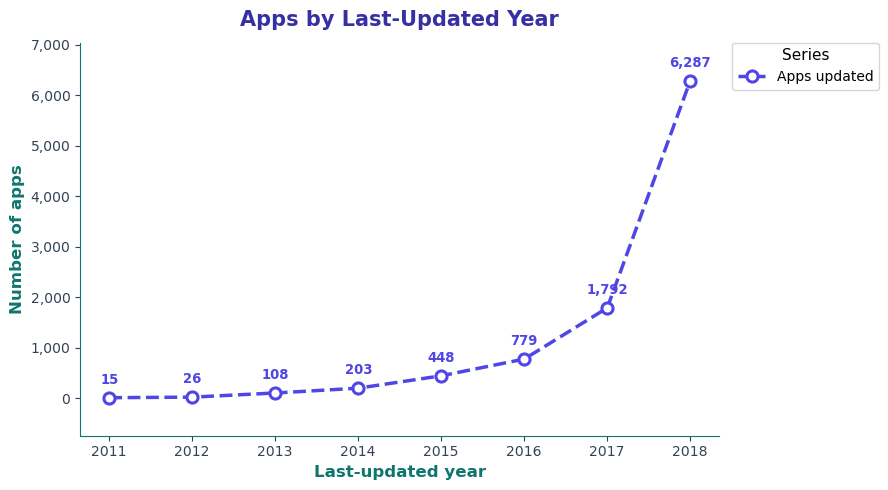

In [135]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(yearly.index, yearly.values, color="#4F46E5", marker="o", markersize=8, markerfacecolor="white",
        markeredgewidth=2.2, linestyle="--", linewidth=2.5, label="Apps updated")
for x, y in zip(yearly.index, yearly.values):
    ax.annotate(f"{y:,}", (x, y), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9.5,
                fontweight="bold", color="#4F46E5")
ax.set_xticks(yearly.index)
ax.margins(y=0.12)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Apps by Last-Updated Year", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Series",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M01_line_plot")

#### M02 · Vertical bar chart
`ax.bar()` — top 10 categories by number of apps.

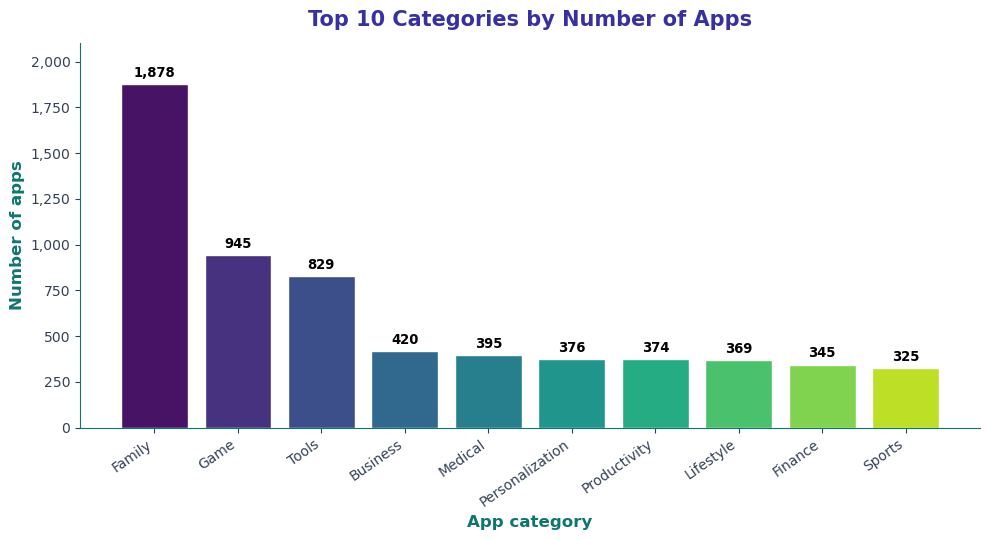

In [136]:
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = plt.cm.viridis(np.linspace(0.05, 0.9, len(top10)))      # multi-colour shades
ax.bar(top10_names, top10.values, color=colors, edgecolor="white", linewidth=1)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9.5, fontweight="bold")
ax.margins(y=0.12)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Top 10 Categories by Number of Apps", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M02_bar_chart")

#### M03 · Horizontal bar chart
`ax.barh()` is better for long labels. Total installs in billions.

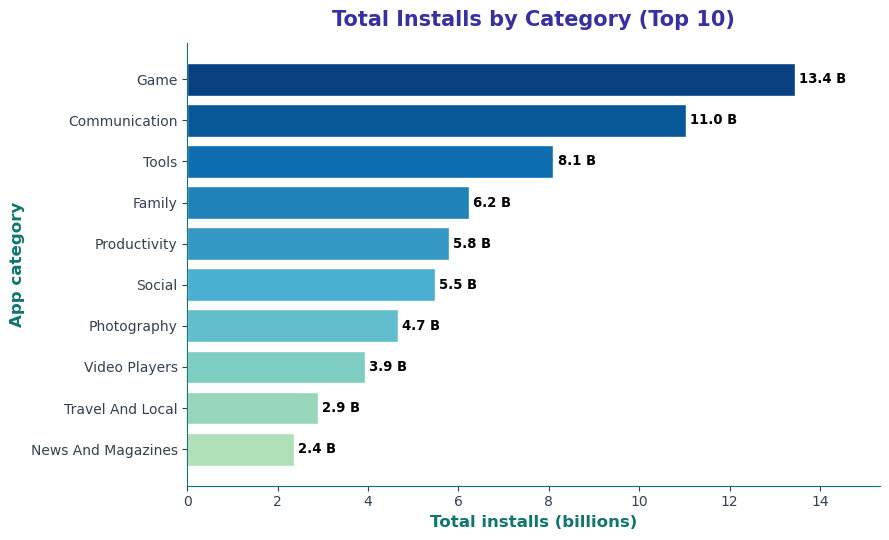

In [137]:
inst = df.groupby("Category", observed=True)["Installs"].sum().nlargest(10).sort_values() / 1e9
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh([str(i) for i in inst.index], inst.values, color=plt.cm.GnBu(np.linspace(0.35, 1, len(inst))),
        edgecolor="white", linewidth=1)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.1f} B", padding=3, fontsize=9.5, fontweight="bold")
ax.margins(x=0.14)
ax.set_title("Total Installs by Category (Top 10)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Total installs (billions)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M03_barh_chart")

#### M04 · Histogram
`ax.hist()` shows how ratings are distributed.

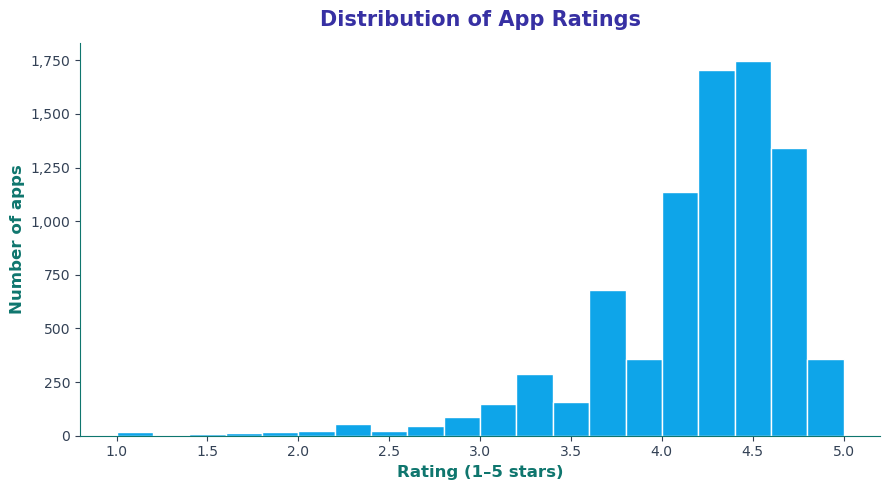

In [138]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(rated["Rating"], bins=20, color="#0EA5E9", edgecolor="white", linewidth=1)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Distribution of App Ratings", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M04_histogram")

#### M05 · Scatter plot
Every dot is an app. More reviews usually means more installs.

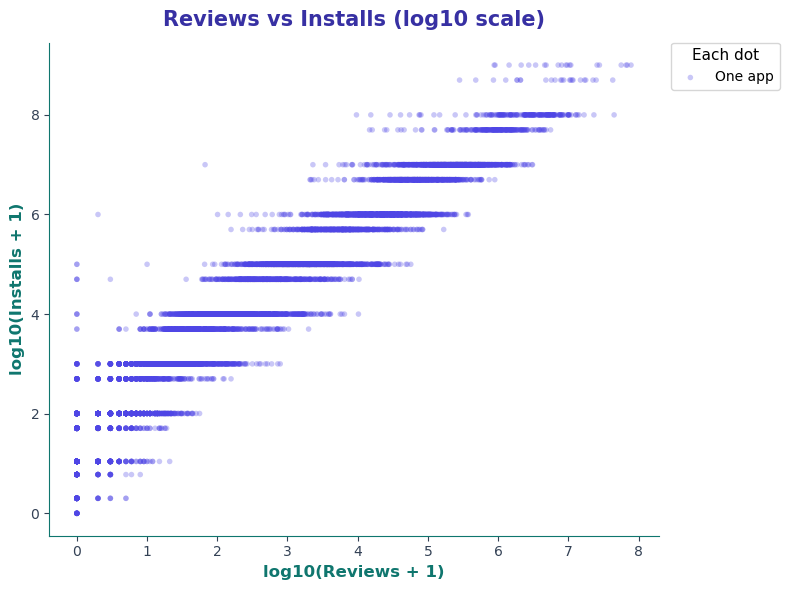

In [139]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["Log_Reviews"], df["Log_Installs"], alpha=0.3, s=16, color="#4F46E5", edgecolor="none",
           label="One app")
ax.set_title("Reviews vs Installs (log10 scale)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Each dot",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M05_scatter")

#### M06 · Pie chart
Free vs Paid apps with percentage labels, an exploded slice and a start angle.

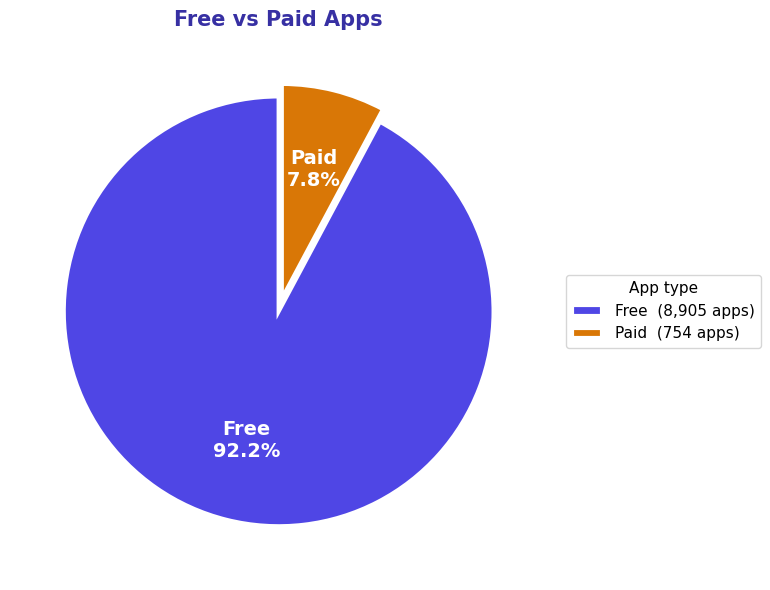

In [140]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

counts = df["Type"].value_counts()
pct = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(8, 6))
wedges, texts = ax.pie(
    counts.values, labels=[f"{i}\n{p:.1f}%" for i, p in zip(counts.index, pct)], labeldistance=0.62,
    textprops=dict(color="white", fontsize=14, fontweight="bold"), explode=(0, 0.06), startangle=90,
    colors=[type_colors[str(i)] for i in counts.index], wedgeprops=dict(edgecolor="white", linewidth=3))
for t in texts:
    t.set_ha("center"); t.set_va("center")
ax.legend(
    wedges,
    [f'{i}  ({v:,} apps)' for i, v in zip(counts.index, counts.values)],
    title="App type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=11,
    title_fontsize=11,
    fancybox=True,
)
ax.set_title("Free vs Paid Apps", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
plt.tight_layout()
save_fig("M06_pie_chart")

#### M07 · Donut chart
A pie chart with a hole: use `wedgeprops=dict(width=...)`.

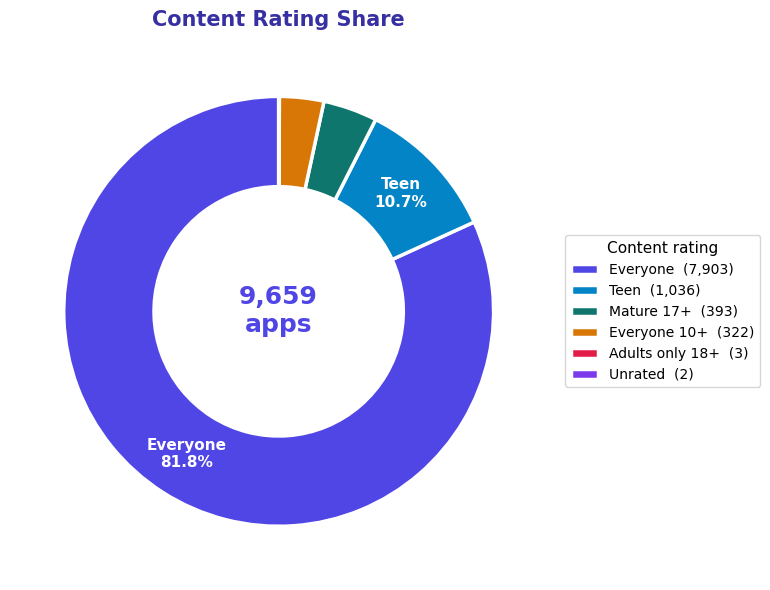

In [141]:
cr = df["Content_Rating"].value_counts()
cr = cr[cr > 0]
pct = cr / cr.sum() * 100
colors = ["#4F46E5", "#0284C7", "#0F766E", "#D97706", "#E11D48", "#7C3AED"][:len(cr)]
labels = [f"{n}\n{p:.1f}%" if p >= 8 else (f"{p:.1f}%" if p >= 4.5 else "") for n, p in zip(cr.index, pct)]
fig, ax = plt.subplots(figsize=(9, 6))
wedges, texts = ax.pie(cr.values, labels=labels, labeldistance=0.79, colors=colors, startangle=90,
                       textprops=dict(color="white", fontsize=11, fontweight="bold"),
                       wedgeprops=dict(width=0.42, edgecolor="white", linewidth=2.5))
for t in texts:
    t.set_ha("center"); t.set_va("center")
ax.legend(
    wedges,
    [f'{i}  ({v:,})' for i, v in zip(cr.index, cr.values)],
    title="Content rating",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
ax.text(0, 0, f"{len(df):,}\napps", ha="center", va="center", fontsize=18, fontweight="bold", color="#4F46E5")
ax.set_title("Content Rating Share", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
plt.tight_layout()
save_fig("M07_donut_chart")

#### M08 · Box plot
`ax.boxplot()` shows median, quartiles and outliers for each group.

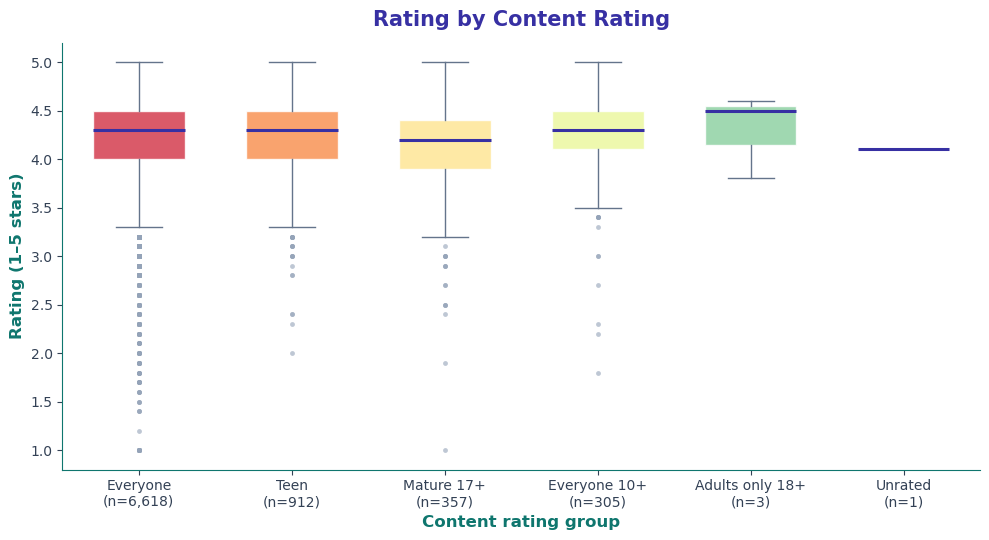

In [142]:
order = [str(c) for c in rated["Content_Rating"].value_counts().index]
data = [rated.loc[rated["Content_Rating"] == c, "Rating"] for c in order]
fig, ax = plt.subplots(figsize=(10, 5.5))
bp = ax.boxplot(data, patch_artist=True, widths=0.6,
                medianprops=dict(color="#3730A3", linewidth=2.2),
                whiskerprops=dict(color="#64748B"), capprops=dict(color="#64748B"),
                flierprops=dict(marker="o", markersize=3.5, markerfacecolor="#94A3B8", markeredgecolor="none", alpha=0.6))
for patch, col in zip(bp["boxes"], plt.cm.Spectral(np.linspace(0.1, 0.9, len(order)))):
    patch.set_facecolor(col); patch.set_alpha(0.85); patch.set_edgecolor("white")
ax.set_xticks(range(1, len(order) + 1))
ax.set_xticklabels([f"{o}\n(n={len(d):,})" for o, d in zip(order, data)])
ax.set_title("Rating by Content Rating", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M08_boxplot")

#### M09 · Violin plot
Like a box plot, but shows the full shape of the data.

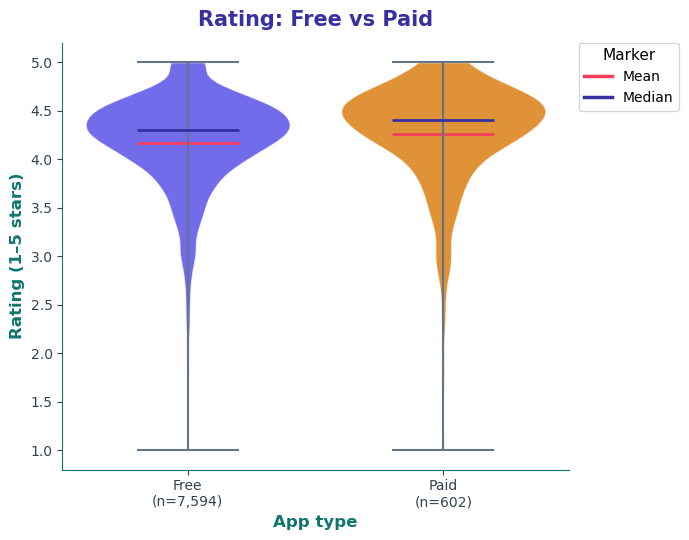

In [143]:
from matplotlib.lines import Line2D
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

free = rated.loc[rated["Type"] == "Free", "Rating"]
paid = rated.loc[rated["Type"] == "Paid", "Rating"]
fig, ax = plt.subplots(figsize=(7, 5.5))
parts = ax.violinplot([free, paid], showmeans=True, showmedians=True, widths=0.8)
for body, col in zip(parts["bodies"], [type_colors["Free"], type_colors["Paid"]]):
    body.set_facecolor(col); body.set_edgecolor("white"); body.set_alpha(0.8)
parts["cmeans"].set_color("#F43F5E");    parts["cmeans"].set_linewidth(2)
parts["cmedians"].set_color("#3730A3"); parts["cmedians"].set_linewidth(2)
for k in ("cbars", "cmins", "cmaxes"):
    parts[k].set_color("#64748B")
ax.set_xticks([1, 2])
ax.set_xticklabels([f"Free\n(n={len(free):,})", f"Paid\n(n={len(paid):,})"])
ax.set_title("Rating: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    [Line2D([0], [0], color="#F43F5E", lw=2.5), Line2D([0], [0], color="#3730A3", lw=2.5)],
    ["Mean", "Median"],
    title="Marker",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M09_violin")

#### M10 · 100% stacked bar chart
Use the `bottom=` argument to stack bars. We show percentages.

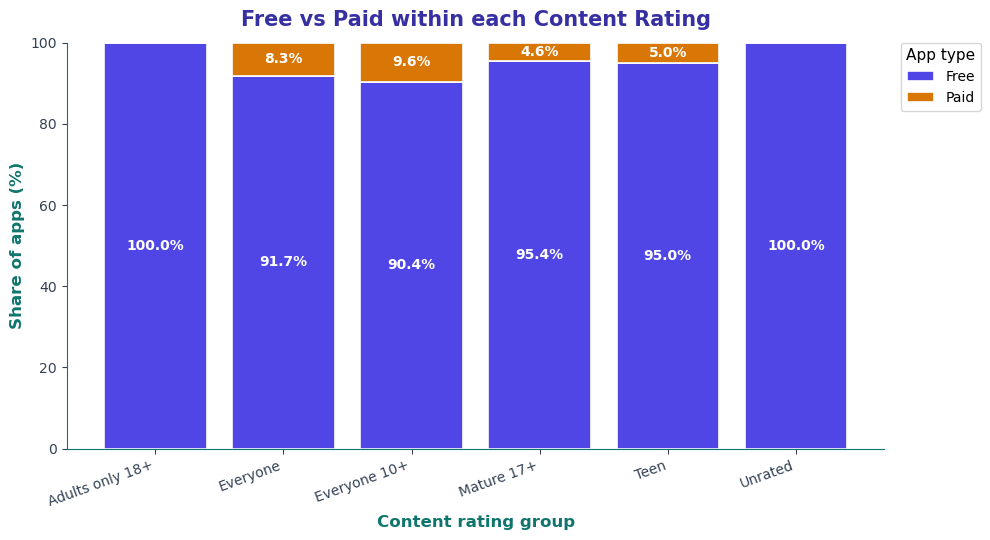

In [144]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

ct = pd.crosstab(df["Content_Rating"], df["Type"])
ct = ct[ct.sum(axis=1) > 0]
pct = ct.div(ct.sum(axis=1), axis=0) * 100
labels_x = [str(i) for i in pct.index]
fig, ax = plt.subplots(figsize=(10, 5.5))
bottom = np.zeros(len(pct))
for col in pct.columns:
    bars = ax.bar(labels_x, pct[col], bottom=bottom, label=col, color=type_colors[str(col)],
                  edgecolor="white", linewidth=1.2)
    ax.bar_label(bars, labels=[f"{v:.1f}%" if v >= 4 else "" for v in pct[col]], label_type="center",
                 color="white", fontweight="bold", fontsize=10)
    bottom += pct[col].to_numpy()
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_ylim(0, 100)
ax.set_title("Free vs Paid within each Content Rating", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Share of apps (%)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="App type",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M10_stacked_bar")

#### M11 · Grouped bar chart
Place two bars side by side by shifting the x positions.

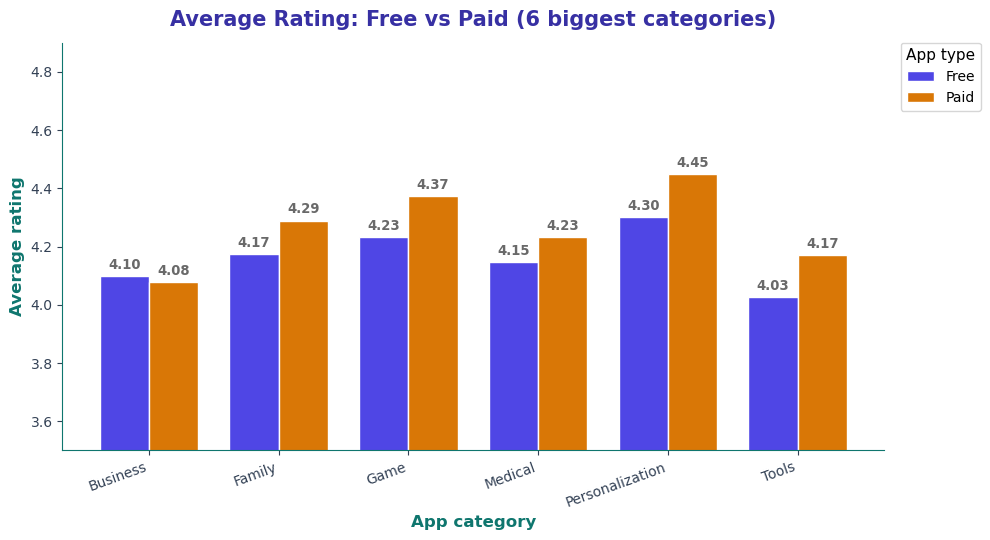

In [145]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

top6 = df["Category"].value_counts().head(6).index
m = df[df["Category"].isin(top6)].groupby(["Category", "Type"], observed=True)["Rating"].mean().unstack()
m.index = m.index.astype(str)
x = np.arange(len(m)); w = 0.38
fig, ax = plt.subplots(figsize=(10, 5.5))
b1 = ax.bar(x - w / 2, m["Free"], w, label="Free", color=type_colors["Free"], edgecolor="white")
b2 = ax.bar(x + w / 2, m["Paid"], w, label="Paid", color=type_colors["Paid"], edgecolor="white")
for bars, col in ((b1, "Free"), (b2, "Paid")):
    ax.bar_label(bars, labels=[f"{v:.2f}" if pd.notna(v) else "" for v in m[col]], padding=3, fontsize=9.5,
                 fontweight="bold", color="dimgray")
ax.set_xticks(x); ax.set_xticklabels(m.index)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_ylim(3.5, 4.9)
ax.set_title("Average Rating: Free vs Paid (6 biggest categories)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Average rating", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="App type",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M11_grouped_bar")

#### M12 · Area chart with fill_between()
Fills the space under a line.

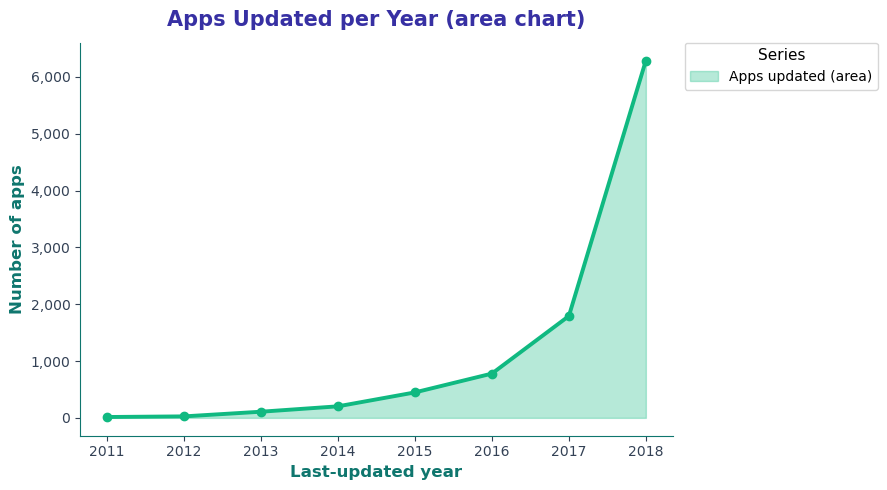

In [146]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(yearly.index, yearly.values, alpha=0.3, color="#10B981", label="Apps updated (area)")
ax.plot(yearly.index, yearly.values, color="#10B981", linewidth=2.8, marker="o", markersize=6)
ax.set_xticks(yearly.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Apps Updated per Year (area chart)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Series",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M12_area_chart")

#### M13 · Step plot
`ax.step()` draws a staircase — good for cumulative counts.

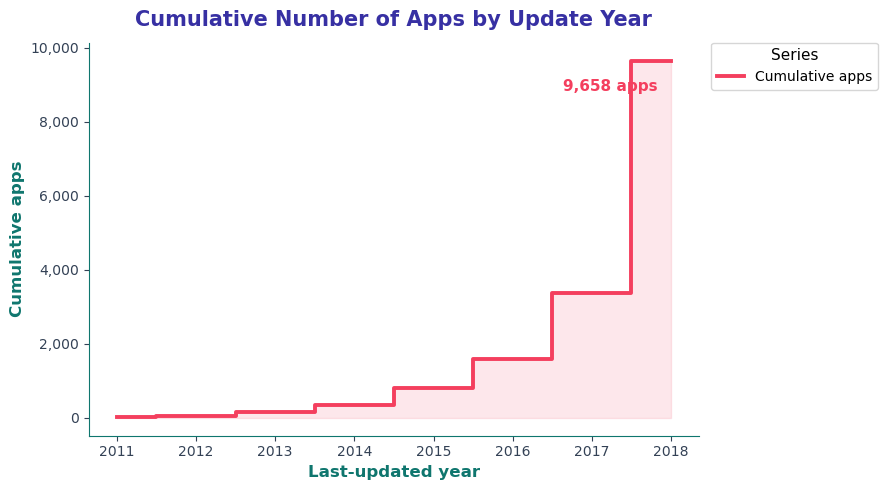

In [147]:
cum = yearly.cumsum()
fig, ax = plt.subplots(figsize=(9, 5))
ax.step(yearly.index, cum, where="mid", color="#F43F5E", linewidth=2.8, label="Cumulative apps")
ax.fill_between(yearly.index, cum, step="mid", alpha=0.12, color="#F43F5E")
ax.annotate(f"{cum.iloc[-1]:,} apps", (yearly.index[-1], cum.iloc[-1]), xytext=(-10, -22),
            textcoords="offset points", ha="right", fontsize=11, fontweight="bold", color="#F43F5E")
ax.set_xticks(yearly.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Cumulative Number of Apps by Update Year", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Cumulative apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Series",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M13_step_plot")

### 3.2 Layouts: subplots, twin axes, GridSpec, mosaic

#### M14 · Subplots grid (2 × 2)
`plt.subplots(2, 2)` gives a 2D array of axes.

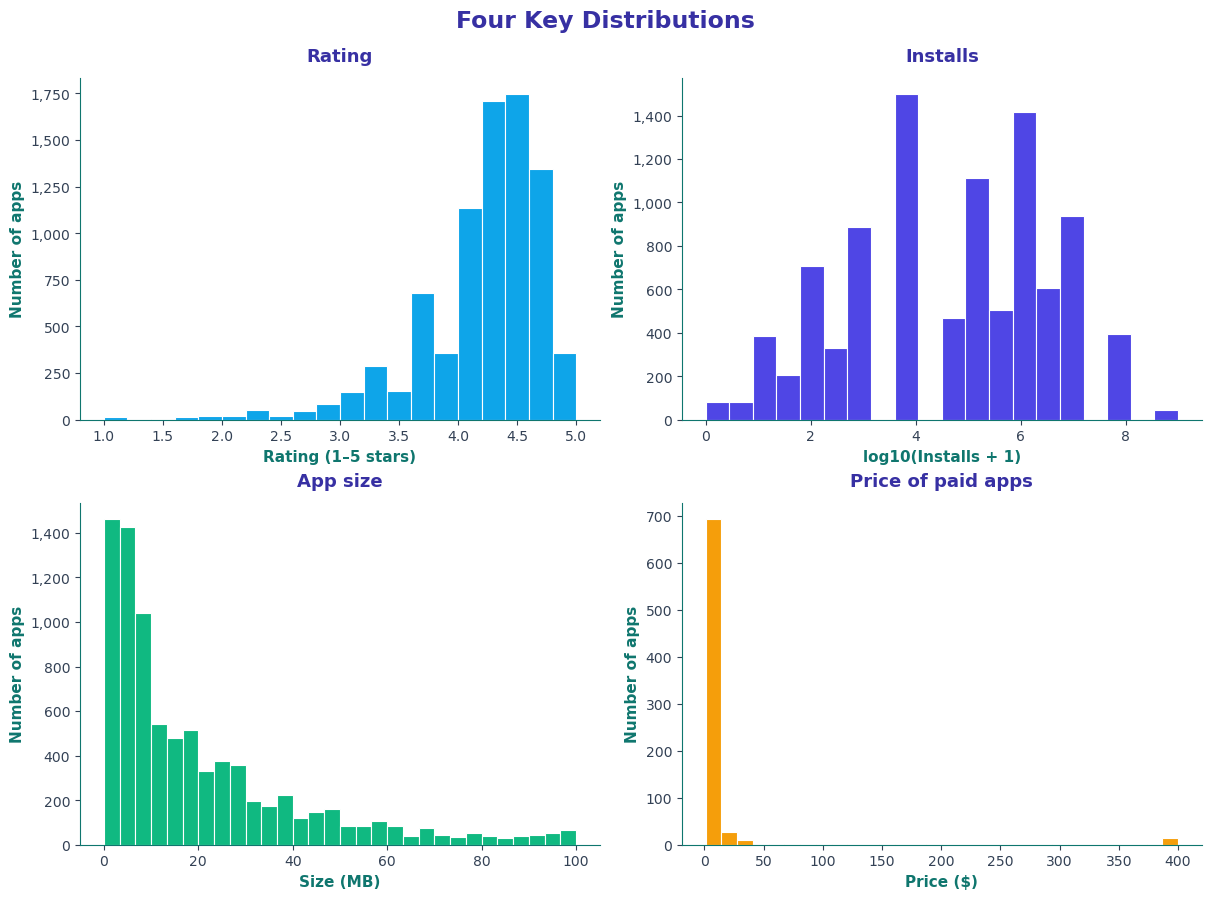

In [148]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.5), layout="constrained")
panels = [
    (axes[0, 0], rated["Rating"], 20, "#0EA5E9",     "Rating",            "Rating (1–5 stars)"),
    (axes[0, 1], df["Log_Installs"], 20, "#4F46E5", "Installs",          "log10(Installs + 1)"),
    (axes[1, 0], df["Size_MB"].dropna(), 30, "#10B981", "App size",     "Size (MB)"),
    (axes[1, 1], df.loc[df["Price"] > 0, "Price"], 30, "#F59E0B", "Price of paid apps", "Price ($)"),
]
for ax, data_, bins, col, ttl, xl in panels:
    ax.hist(data_, bins=bins, color=col, edgecolor="white", linewidth=0.8)
    ax.set_title(ttl, fontsize=13, fontweight="bold", color="#3730A3", pad=12)
    ax.set_xlabel(xl, fontsize=11, fontweight="bold", color="#0F766E")
    ax.set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
    ax.tick_params(axis="x", colors="#334155")
    ax.tick_params(axis="y", colors="#334155")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#0F766E")
    ax.yaxis.set_major_formatter("{x:,.0f}")
fig.suptitle("Four Key Distributions", fontsize=17, fontweight="bold", color="#3730A3", y=1.04)
save_fig("M14_subplots_2x2")

#### M15 · Twin axes (two y-axes)
`ax.twinx()` adds a second y-axis: bars for app count, line for average rating.

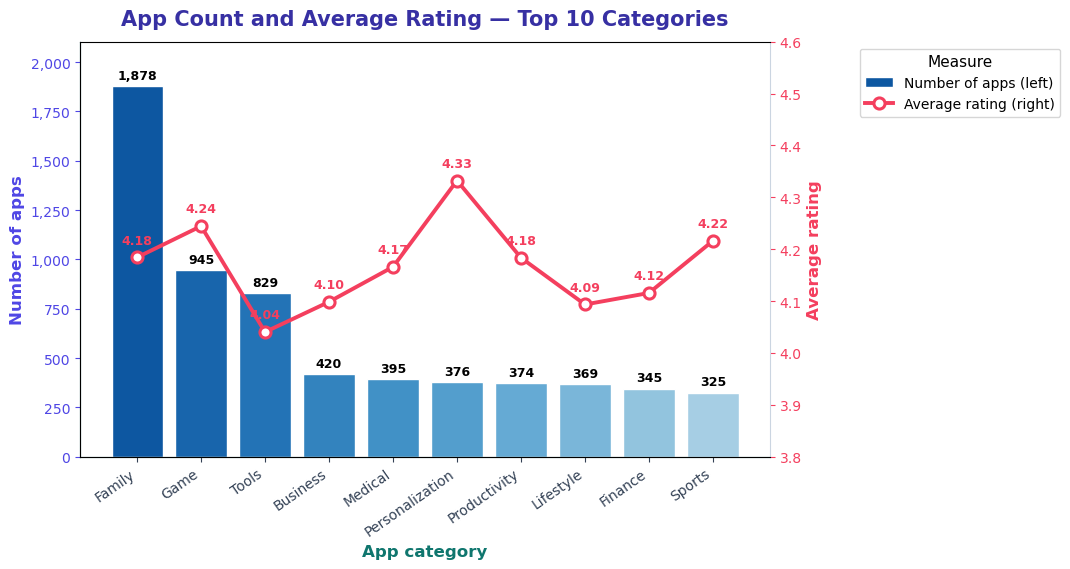

In [149]:
avg_rating = df.groupby("Category", observed=True)["Rating"].mean().loc[top10.index]
fig, ax1 = plt.subplots(figsize=(11, 5.8))
bars = ax1.bar(top10_names, top10.values, color=plt.cm.Blues(np.linspace(0.85, 0.35, len(top10))), edgecolor="white", label="Number of apps")
for c in ax1.containers:
    ax1.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9, fontweight="bold")
ax1.margins(y=0.12)
ax1.set_ylabel("Number of apps", color="#4F46E5", fontsize=12, fontweight="bold")
ax1.tick_params(axis="y", colors="#4F46E5")
plt.setp(ax1.get_xticklabels(), rotation=35, ha="right")
ax1.yaxis.set_major_formatter("{x:,.0f}")
ax2 = ax1.twinx()
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color("#CBD5E1")
line, = ax2.plot(top10_names, avg_rating.values, color="#F43F5E", marker="o", markersize=8, linewidth=2.8,
                 markerfacecolor="white", markeredgewidth=2.2, label="Average rating")
for xi, yi in zip(top10_names, avg_rating.values):
    ax2.annotate(f"{yi:.2f}", (xi, yi), xytext=(0, 10), textcoords="offset points", ha="center",
                 fontsize=9, fontweight="bold", color="#F43F5E")
ax2.set_ylim(3.8, 4.6)
ax2.set_ylabel("Average rating", color="#F43F5E", fontsize=12, fontweight="bold")
ax2.tick_params(axis="y", colors="#F43F5E")
ax1.set_title("App Count and Average Rating — Top 10 Categories", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax1.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax1.tick_params(axis="x", colors="#334155")
ax1.spines[["top", "right"]].set_visible(False)
ax1.spines[["left", "bottom"]].set_color("#0F766E")
ax1.legend(
    [bars, line],
    ["Number of apps (left)", "Average rating (right)"],
    title="Measure",
    loc="upper left",
    bbox_to_anchor=(1.12, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M15_twin_axes")

#### M16 · Error bars
`ax.errorbar()` shows mean ± standard deviation.

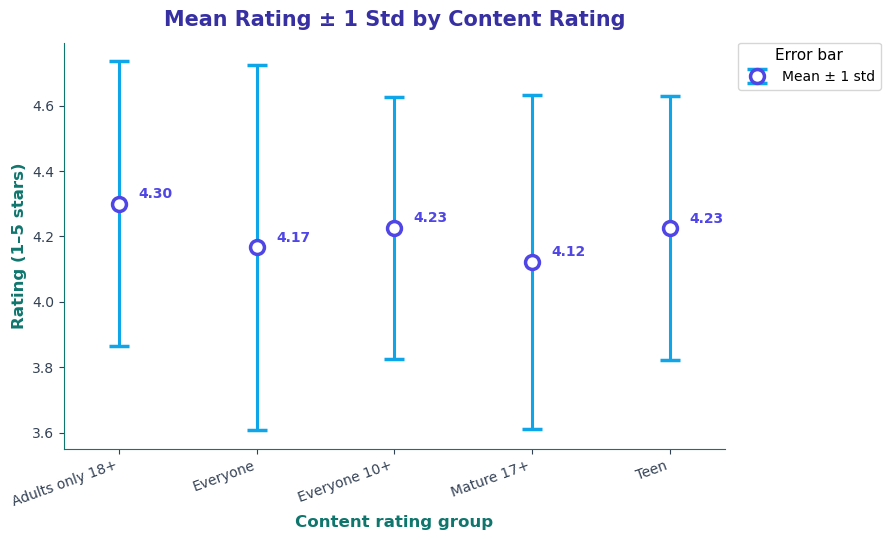

In [150]:
g = rated.groupby("Content_Rating", observed=True)["Rating"].agg(["mean", "std"]).dropna()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.errorbar(range(len(g)), g["mean"], yerr=g["std"], fmt="o", markersize=10, capsize=7, capthick=2,
            elinewidth=2.2, color="#4F46E5", ecolor="#0EA5E9", markerfacecolor="white", markeredgewidth=2.5,
            label="Mean ± 1 std")
for i, v in enumerate(g["mean"]):
    ax.annotate(f"{v:.2f}", (i, v), xytext=(14, 4), textcoords="offset points", fontsize=10,
                fontweight="bold", color="#4F46E5")
ax.set_xticks(range(len(g)))
ax.set_xticklabels([str(i) for i in g.index])
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.margins(x=0.1)
ax.set_title("Mean Rating ± 1 Std by Content Rating", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Error bar",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M16_errorbar")

#### M17 · Stem plot
`ax.stem()` — dots on sticks. Number of apps by minimum Android version.

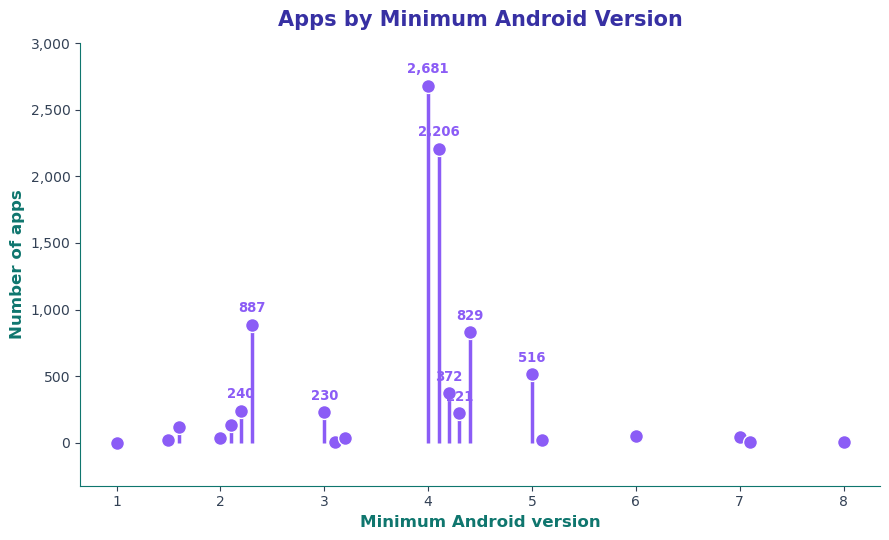

In [151]:
v = df["Min_Android"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 5.5))
markerline, stemlines, baseline = ax.stem(v.index, v.values, basefmt=" ")
plt.setp(stemlines, color="#8B5CF6", linewidth=2.5)
plt.setp(markerline, color="#8B5CF6", markersize=10, markeredgecolor="white")
for xi, yi in zip(v.index, v.values):
    if yi >= v.max() * 0.08:
        ax.annotate(f"{yi:,}", (xi, yi), xytext=(0, 9), textcoords="offset points", ha="center",
                    fontsize=9.5, fontweight="bold", color="#8B5CF6")
ax.margins(y=0.12)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Apps by Minimum Android Version", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Minimum Android version", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M17_stem_plot")

#### M18 · Hexbin plot
Counts points inside hexagons. Better than a scatter plot when there are many points.

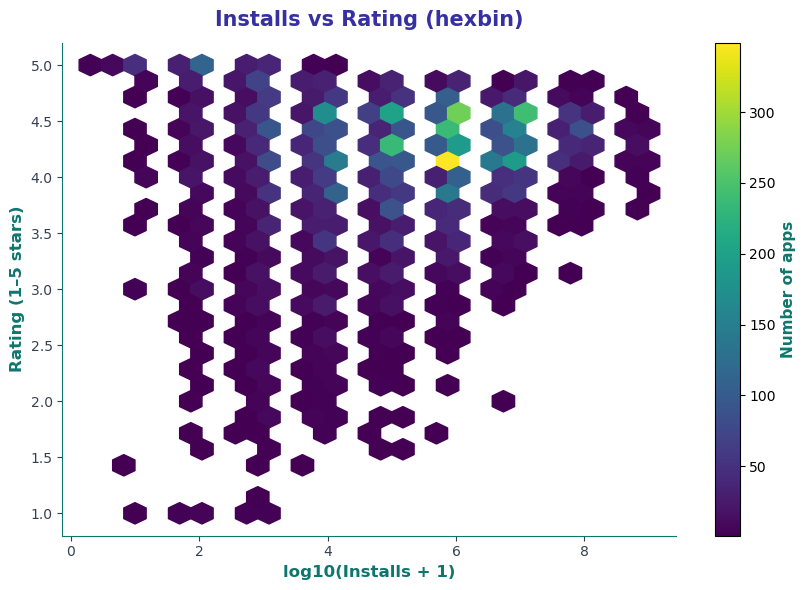

In [152]:
fig, ax = plt.subplots(figsize=(8.5, 6))
hb = ax.hexbin(rated["Log_Installs"], rated["Rating"], gridsize=25, cmap="viridis", mincnt=1)
cbar = fig.colorbar(hb, ax=ax)
cbar.set_label("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
ax.set_title("Installs vs Rating (hexbin)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M18_hexbin")

#### M19 · 2D histogram (hist2d)
Same idea with square bins.

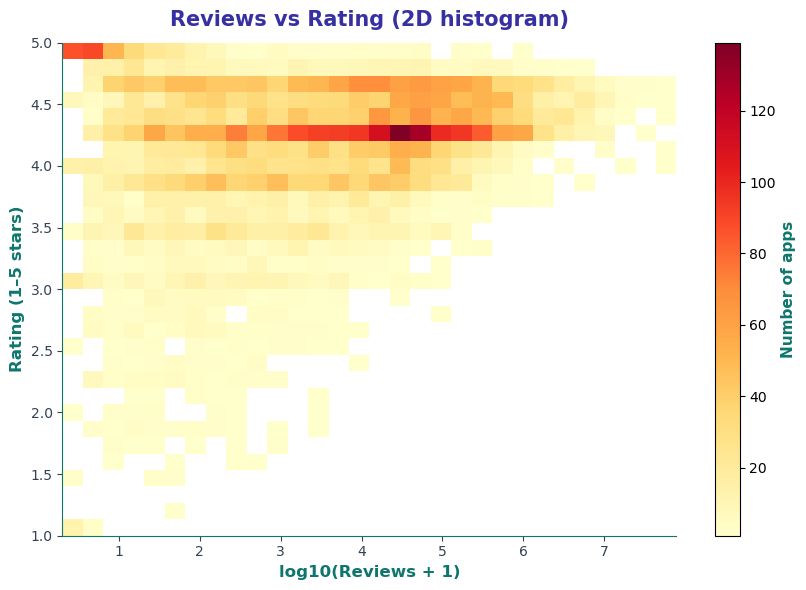

In [153]:
fig, ax = plt.subplots(figsize=(8.5, 6))
h = ax.hist2d(rated["Log_Reviews"], rated["Rating"], bins=30, cmap="YlOrRd", cmin=1)
ax.grid(False)
cbar = fig.colorbar(h[3], ax=ax)
cbar.set_label("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
ax.set_title("Reviews vs Rating (2D histogram)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M19_hist2d")

#### M20 · Heatmap with imshow() + colorbar
Correlation matrix drawn as an image, with the number written in each cell.

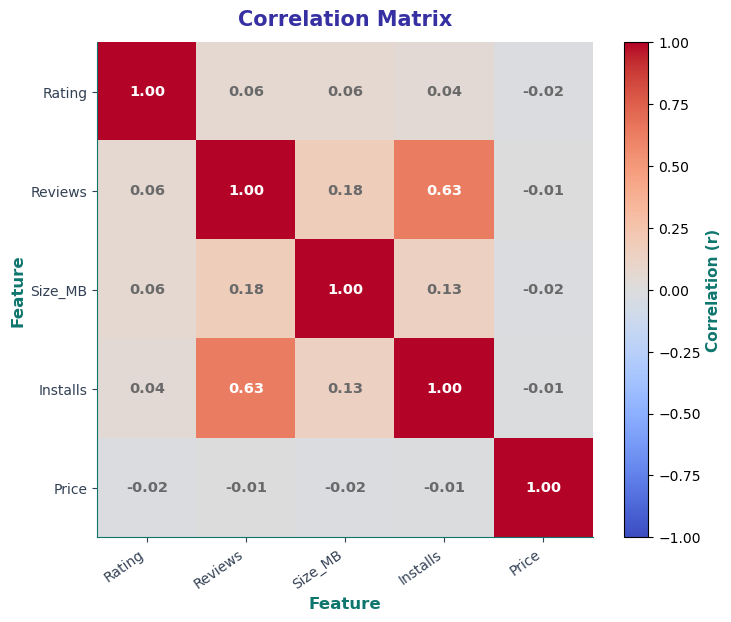

In [154]:
cols = ["Rating", "Reviews", "Size_MB", "Installs", "Price"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.grid(False)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=10.5, fontweight="bold",
                color="white" if abs(val) > 0.55 else "dimgray")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Correlation (r)", fontsize=11, fontweight="bold", color="#0F766E")
ax.set_title("Correlation Matrix", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M20_imshow_heatmap")

### 3.3 Customising charts

#### M21 · Annotate with an arrow
`ax.annotate()` points at something important.

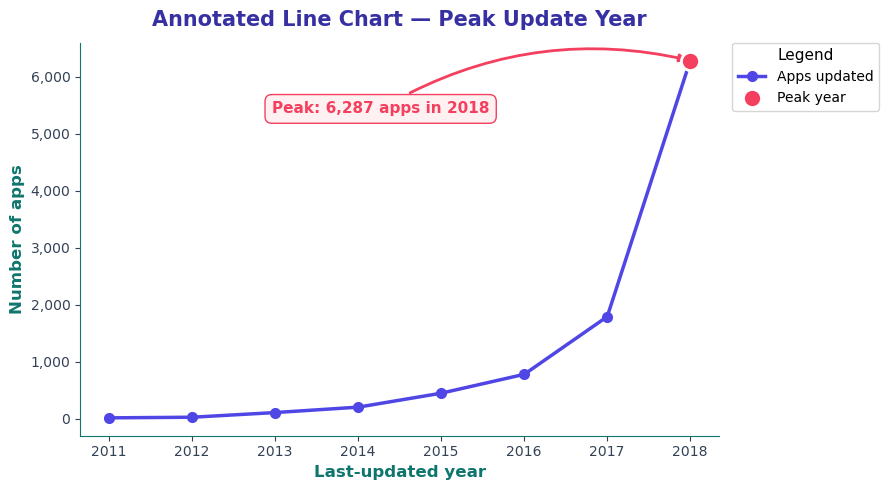

In [155]:
peak_year, peak_val = yearly.idxmax(), yearly.max()
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(yearly.index, yearly.values, marker="o", color="#4F46E5", linewidth=2.5, markersize=7, label="Apps updated")
ax.scatter([peak_year], [peak_val], s=170, color="#F43F5E", zorder=5, edgecolor="white", linewidth=2, label="Peak year")
ax.annotate(f"Peak: {peak_val:,} apps in {peak_year}", xy=(peak_year, peak_val),
            xytext=(0.30, 0.82), textcoords="axes fraction", fontsize=11, fontweight="bold", color="#F43F5E",
            bbox=dict(boxstyle="round,pad=0.45", fc="#FFF1F2", ec="#F43F5E"),
            arrowprops=dict(arrowstyle="-|>", color="#F43F5E", lw=2, connectionstyle="arc3,rad=-0.2"))
ax.set_xticks(yearly.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Annotated Line Chart — Peak Update Year", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Legend",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M21_annotate")

#### M22 · axvline() — vertical reference lines
Draw mean and median on a histogram. (`axhline` does the same horizontally.)

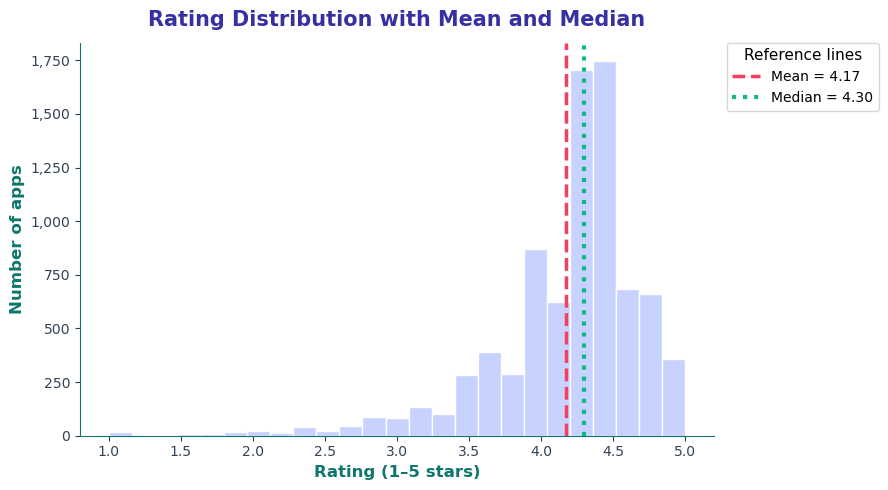

In [156]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(rated["Rating"], bins=25, color="#C7D2FE", edgecolor="white", linewidth=1)
ax.axvline(rated["Rating"].mean(), color="#F43F5E", linestyle="--", linewidth=2.5, label=f"Mean = {rated['Rating'].mean():.2f}")
ax.axvline(rated["Rating"].median(), color="#10B981", linestyle=":", linewidth=3, label=f"Median = {rated['Rating'].median():.2f}")
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Rating Distribution with Mean and Median", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Reference lines",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M22_axvline")

#### M23 · Log scale axis
`set_xscale('log')` with log-spaced bins for very skewed data.

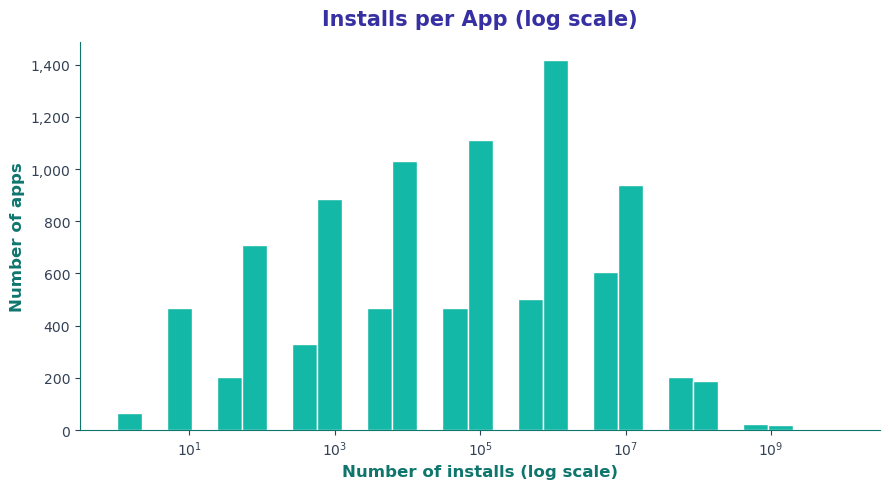

In [157]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df.loc[df["Installs"] > 0, "Installs"], bins=np.logspace(0, 10, 30), color="#14B8A6", edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Installs per App (log scale)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Number of installs (log scale)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M23_log_scale")

#### M24 · Customise the legend
Title, location, frame, shadow, font size and columns.

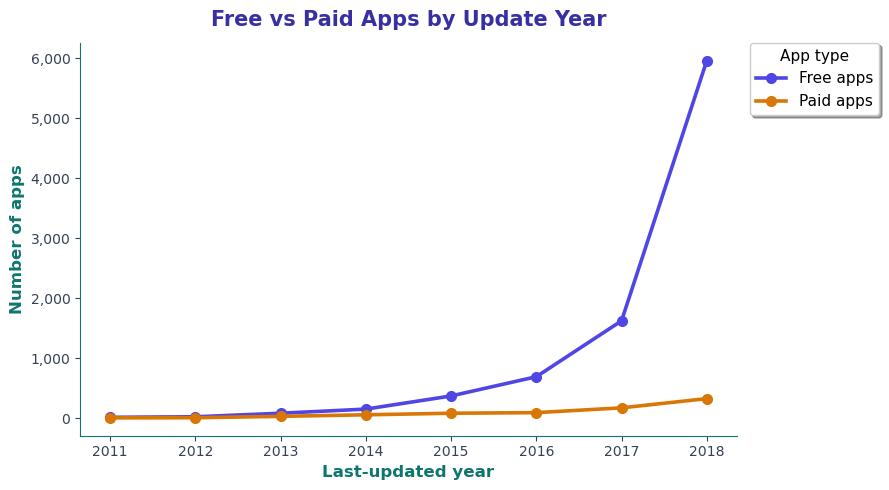

In [158]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
for col in yearly_type.columns:
    ax.plot(yearly_type.index, yearly_type[col], marker="o", markersize=7, linewidth=2.6,
            color=type_colors[str(col)], label=f"{col} apps")
ax.set_xticks(yearly_type.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Free vs Paid Apps by Update Year", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="App type",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=11,
    title_fontsize=11,
    fancybox=True,
    shadow=True,
)
plt.tight_layout()
save_fig("M24_legend")

#### M25 · Grid and minor ticks
`ax.grid()` and `ax.minorticks_on()` make values easier to read.

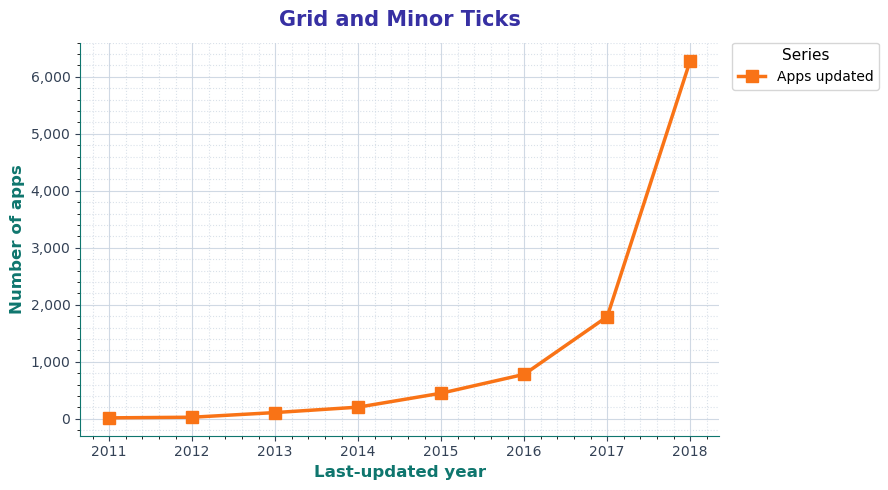

In [159]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(yearly.index, yearly.values, marker="s", markersize=8, color="#F97316", linewidth=2.5, label="Apps updated")
ax.minorticks_on()
ax.grid(True, which="major", linestyle="-", color="#CBD5E1", alpha=0.9)
ax.grid(True, which="minor", linestyle=":", color="#CBD5E1", alpha=0.7)
ax.set_xticks(yearly.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Grid and Minor Ticks", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Series",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M25_grid")

#### M26 · Add value labels with bar_label()
Write the number on top of each bar.

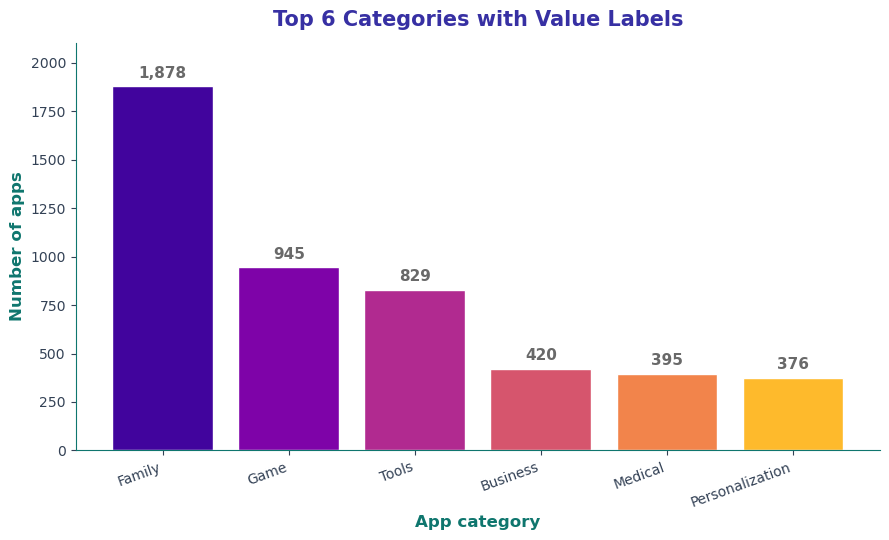

In [160]:
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(top10_names[:6], top10.values[:6], color=plt.cm.plasma(np.linspace(0.1, 0.85, 6)), edgecolor="white", linewidth=1)
ax.bar_label(bars, labels=[f"{v:,}" for v in top10.values[:6]], padding=4, fontsize=11, fontweight="bold", color="dimgray")
ax.margins(y=0.12)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_title("Top 6 Categories with Value Labels", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M26_bar_label")

#### M27 · Colours from a colormap
Pick evenly spaced colours from `viridis`.

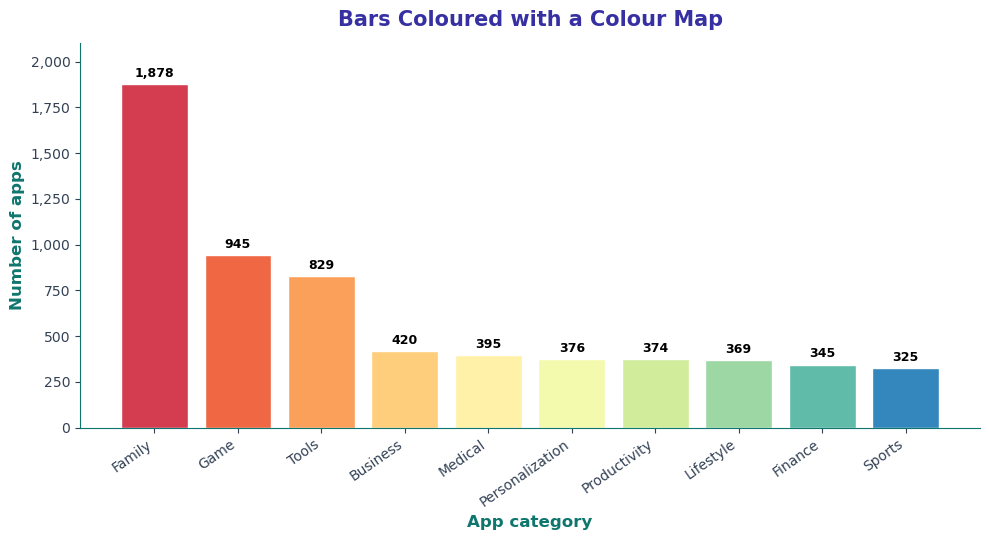

In [161]:
colors = plt.cm.Spectral(np.linspace(0.1, 0.9, 10))
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(top10_names, top10.values, color=colors, edgecolor="white", linewidth=1)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9, fontweight="bold")
ax.margins(y=0.12)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Bars Coloured with a Colour Map", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M27_colormap")

#### M28 · Number formatting with FuncFormatter
Show `15M` instead of `15000000` on the axis.

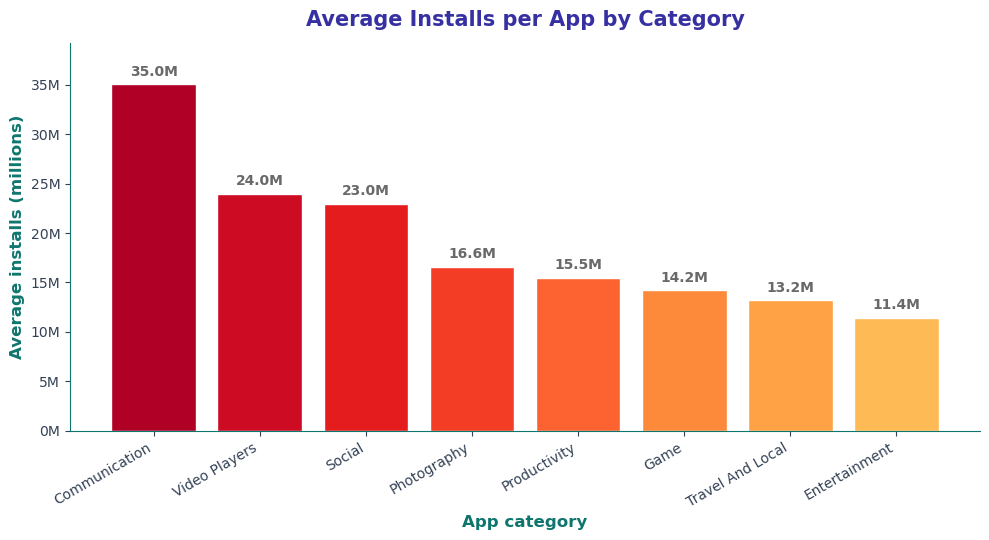

In [162]:
avg_inst = df.groupby("Category", observed=True)["Installs"].mean().nlargest(8)
fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar([str(i) for i in avg_inst.index], avg_inst.values, color=plt.cm.YlOrRd(np.linspace(0.9, 0.35, 8)), edgecolor="white", linewidth=1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e6:.0f}M"))
ax.bar_label(bars, labels=[f"{v / 1e6:.1f}M" for v in avg_inst.values], padding=4, fontsize=10, fontweight="bold", color="dimgray")
ax.margins(y=0.12)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.set_title("Average Installs per App by Category", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Average installs (millions)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M28_formatter")

#### M29 · Zoom with set_xlim() and set_ylim()
Limit the visible range of the axes.

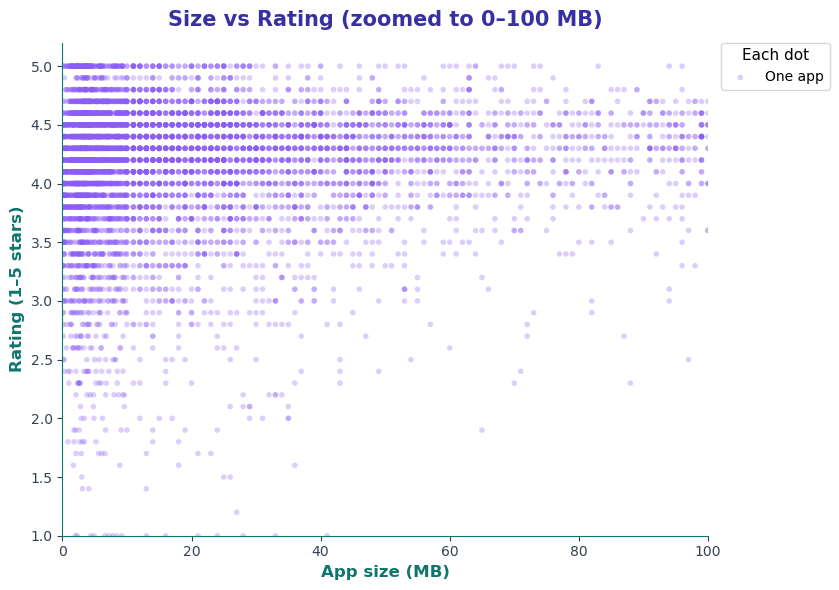

In [163]:
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.scatter(df["Size_MB"], df["Rating"], alpha=0.3, s=16, color="#8B5CF6", edgecolor="none", label="One app")
ax.set_xlim(0, 100)
ax.set_ylim(1, 5.2)
ax.set_title("Size vs Rating (zoomed to 0–100 MB)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App size (MB)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Each dot",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M29_xlim_ylim")

#### M30 · Chart style with plt.style.context()
Try a ready-made style for one chart only.

Some styles: ['Solarize_Light2', '_classic_test_patch', '_mpl-gallery', '_mpl-gallery-nogrid', 'bmh', 'classic', 'dark_background', 'fast']


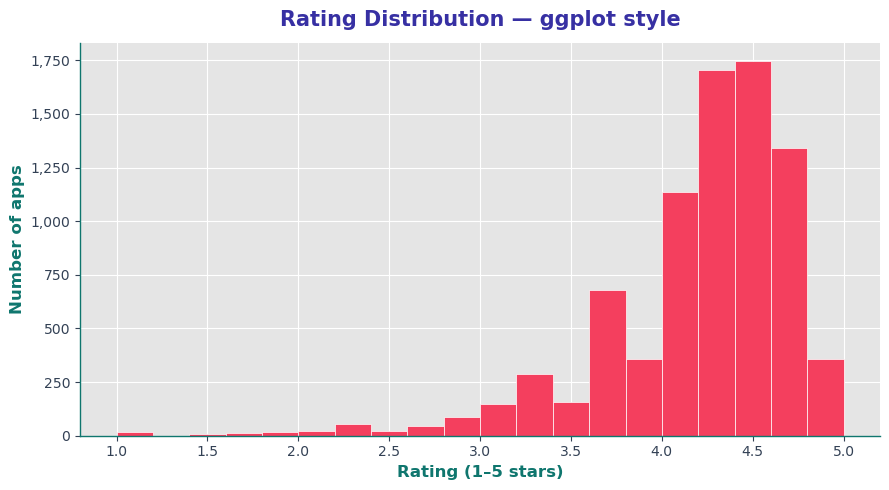

In [164]:
print("Some styles:", plt.style.available[:8])
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.hist(rated["Rating"], bins=20, color="#F43F5E", edgecolor="white")
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.set_title("Rating Distribution — ggplot style", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
    ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
    ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
    ax.tick_params(axis="x", colors="#334155")
    ax.tick_params(axis="y", colors="#334155")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#0F766E")
    plt.tight_layout()
    save_fig("M30_style")

#### M31 · Figure title with suptitle()
One big title above several charts.

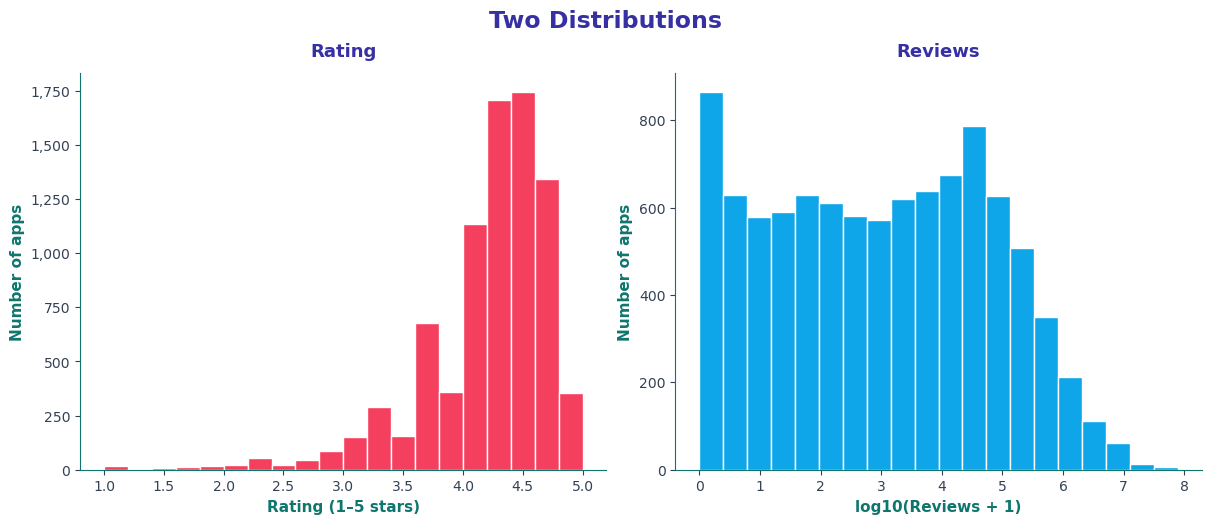

In [165]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axes[0].hist(rated["Rating"], bins=20, color="#F43F5E", edgecolor="white")
axes[0].set_title("Rating", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axes[0].set_xlabel("Rating (1–5 stars)", fontsize=11, fontweight="bold", color="#0F766E")
axes[0].set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
axes[0].tick_params(axis="x", colors="#334155")
axes[0].tick_params(axis="y", colors="#334155")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].spines[["left", "bottom"]].set_color("#0F766E")
axes[1].hist(df["Log_Reviews"], bins=20, color="#0EA5E9", edgecolor="white")
axes[1].set_title("Reviews", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axes[1].set_xlabel("log10(Reviews + 1)", fontsize=11, fontweight="bold", color="#0F766E")
axes[1].set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
axes[1].tick_params(axis="x", colors="#334155")
axes[1].tick_params(axis="y", colors="#334155")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].spines[["left", "bottom"]].set_color("#0F766E")
for a in axes:
    a.yaxis.set_major_formatter("{x:,.0f}")
fig.suptitle("Two Distributions", fontsize=17, fontweight="bold", color="#3730A3", y=1.06)
save_fig("M31_suptitle")

#### M32 · constrained layout (no overlapping labels)
`layout='constrained'` keeps titles and labels from overlapping.

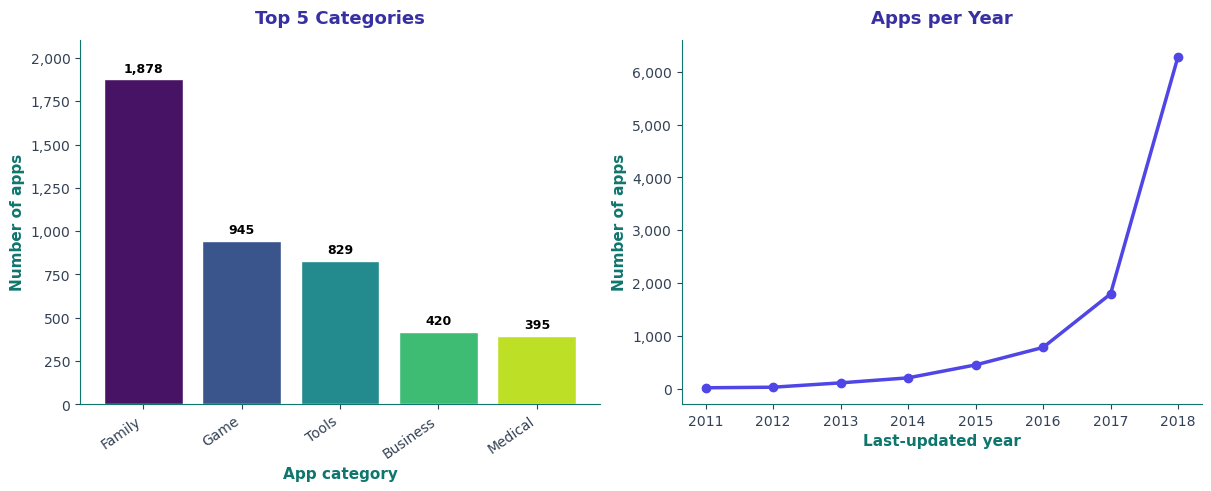

In [166]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
axes[0].bar(top10_names[:5], top10.values[:5], color=plt.cm.viridis(np.linspace(0.05, 0.9, 5)), edgecolor="white")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9, fontweight="bold")
axes[0].margins(y=0.12)
plt.setp(axes[0].get_xticklabels(), rotation=35, ha="right")
axes[0].set_title("Top 5 Categories", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axes[0].set_xlabel("App category", fontsize=11, fontweight="bold", color="#0F766E")
axes[0].set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
axes[0].tick_params(axis="x", colors="#334155")
axes[0].tick_params(axis="y", colors="#334155")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].spines[["left", "bottom"]].set_color("#0F766E")
axes[1].plot(yearly.index, yearly.values, color="#4F46E5", marker="o", linewidth=2.5)
axes[1].set_xticks(yearly.index)
axes[1].set_title("Apps per Year", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axes[1].set_xlabel("Last-updated year", fontsize=11, fontweight="bold", color="#0F766E")
axes[1].set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
axes[1].tick_params(axis="x", colors="#334155")
axes[1].tick_params(axis="y", colors="#334155")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].spines[["left", "bottom"]].set_color("#0F766E")
for a in axes:
    a.yaxis.set_major_formatter("{x:,.0f}")
save_fig("M32_constrained")

#### M33 · GridSpec — uneven layouts
Make some charts bigger than others.

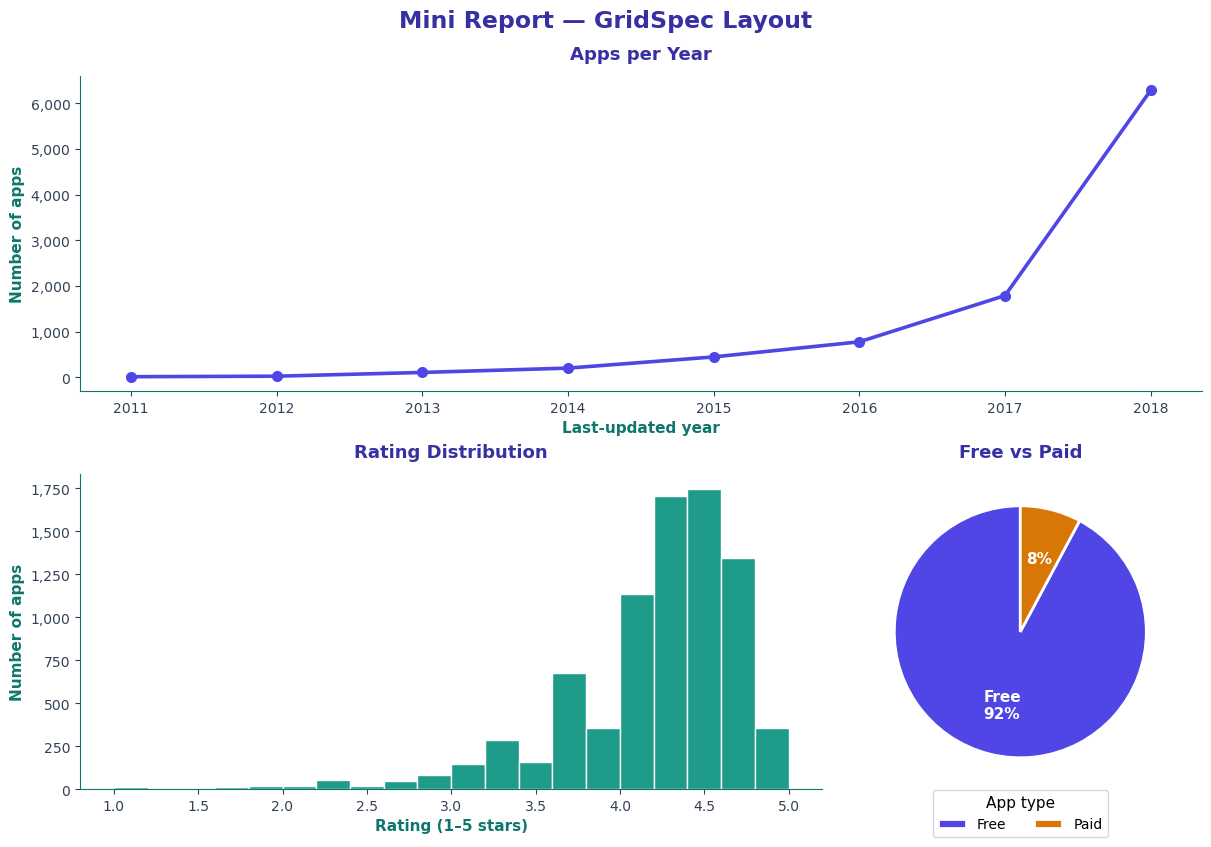

In [167]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig = plt.figure(figsize=(12, 8), layout="constrained")
gs = GridSpec(2, 3, figure=fig)
ax1 = fig.add_subplot(gs[0, :])      # whole top row
ax2 = fig.add_subplot(gs[1, :2])     # bottom left (2 columns wide)
ax3 = fig.add_subplot(gs[1, 2])      # bottom right
ax1.plot(yearly.index, yearly.values, marker="o", color="#4F46E5", linewidth=2.6, markersize=7)
ax1.set_xticks(yearly.index)
ax1.yaxis.set_major_formatter("{x:,.0f}")
ax1.set_title("Apps per Year", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
ax1.set_xlabel("Last-updated year", fontsize=11, fontweight="bold", color="#0F766E")
ax1.set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
ax1.tick_params(axis="x", colors="#334155")
ax1.tick_params(axis="y", colors="#334155")
ax1.spines[["top", "right"]].set_visible(False)
ax1.spines[["left", "bottom"]].set_color("#0F766E")
ax2.hist(rated["Rating"], bins=20, color=plt.cm.viridis(0.55), edgecolor="white")
ax2.yaxis.set_major_formatter("{x:,.0f}")
ax2.set_title("Rating Distribution", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
ax2.set_xlabel("Rating (1–5 stars)", fontsize=11, fontweight="bold", color="#0F766E")
ax2.set_ylabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
ax2.tick_params(axis="x", colors="#334155")
ax2.tick_params(axis="y", colors="#334155")
ax2.spines[["top", "right"]].set_visible(False)
ax2.spines[["left", "bottom"]].set_color("#0F766E")
tc = df["Type"].value_counts()
pct = tc / tc.sum() * 100
w_, t_ = ax3.pie(tc.values, labels=[f"{i}\n{p:.0f}%" if p >= 15 else f"{p:.0f}%" for i, p in zip(tc.index, pct)],
                 labeldistance=0.6, startangle=90, colors=[type_colors[str(i)] for i in tc.index],
                 wedgeprops=dict(edgecolor="white", linewidth=2), textprops=dict(color="white", fontsize=11, fontweight="bold"))
for t in t_:
    t.set_ha("center"); t.set_va("center")
ax3.legend(w_, [str(i) for i in tc.index], title="App type", loc="upper center", bbox_to_anchor=(0.5, 0.02), ncol=2,
           fontsize=10, title_fontsize=11, fancybox=True)
ax3.set_title("Free vs Paid", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
fig.suptitle("Mini Report — GridSpec Layout", fontsize=17, fontweight="bold", color="#3730A3", y=1.04)
save_fig("M33_gridspec")

#### M34 · Inset axes (a chart inside a chart)
`ax.inset_axes()` zooms into one area.

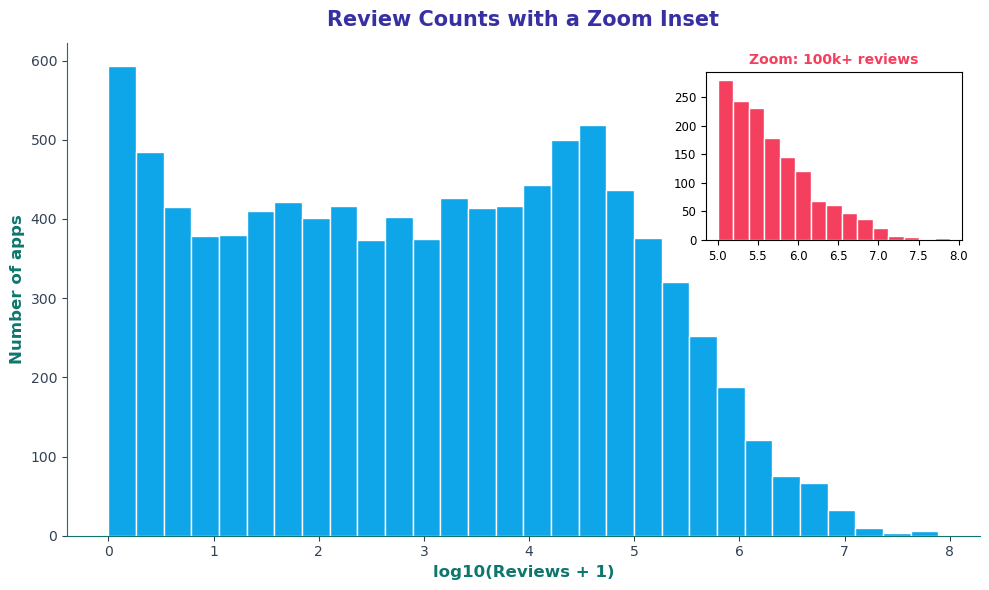

In [168]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(df["Log_Reviews"], bins=30, color="#0EA5E9", edgecolor="white")
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Review Counts with a Zoom Inset", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
axins = ax.inset_axes([0.70, 0.60, 0.28, 0.34])          # empty upper-right corner of the chart
axins.hist(df.loc[df["Log_Reviews"] > 5, "Log_Reviews"], bins=15, color="#F43F5E", edgecolor="white")
axins.set_facecolor("white")
axins.spines[["top", "right"]].set_visible(True)
axins.set_title("Zoom: 100k+ reviews", fontsize=10, fontweight="bold", color="#F43F5E")
axins.tick_params(labelsize=8.5)
plt.tight_layout()
save_fig("M34_inset")

#### M35 · Save in several formats
`savefig()` can write PNG, PDF or SVG. SVG and PDF stay sharp at any size.

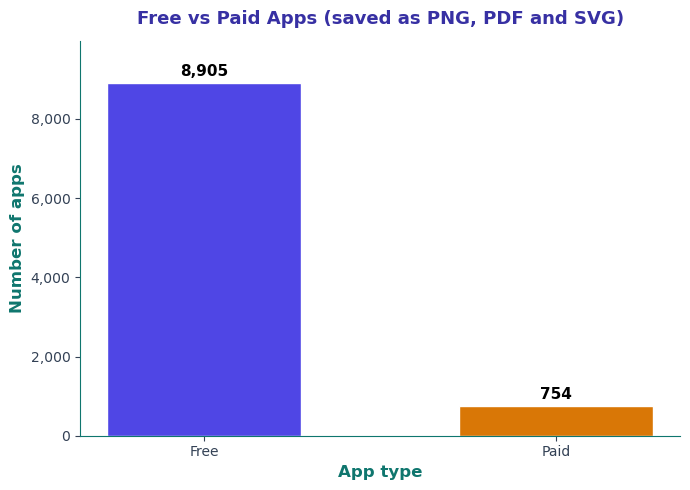

['M35_export.pdf', 'M35_export.png', 'M35_export.svg']


In [169]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(7, 5))
tc = df["Type"].value_counts()
ax.bar([str(i) for i in tc.index], tc.values, color=[type_colors[str(i)] for i in tc.index], edgecolor="white", width=0.55)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=11, fontweight="bold")
ax.margins(y=0.12)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Free vs Paid Apps (saved as PNG, PDF and SVG)", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
fig.savefig("images/M35_export.pdf", bbox_inches="tight")
fig.savefig("images/M35_export.svg", bbox_inches="tight")
plt.tight_layout()
save_fig("M35_export")
print(sorted(f for f in os.listdir("images") if "export" in f))

#### M36 · Polar bar chart
Apps updated in each month, drawn on a circle.

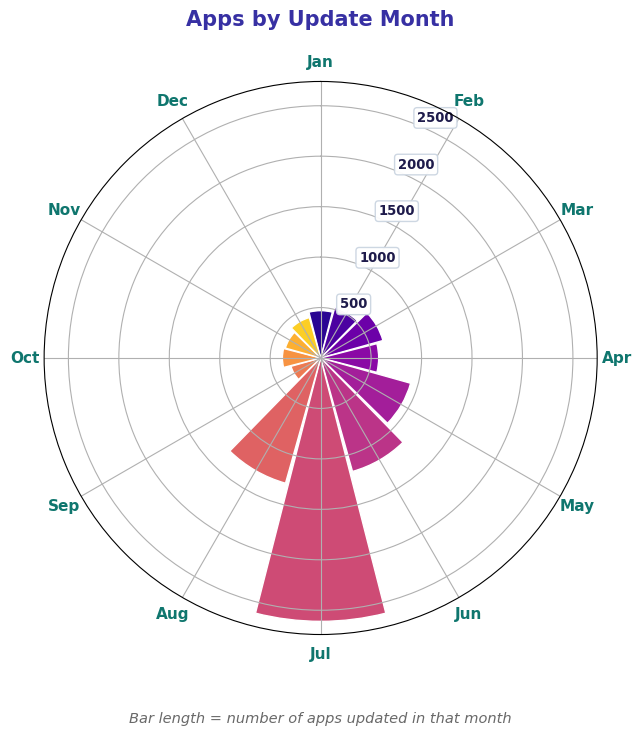

In [170]:
monthly_counts = df["Month"].value_counts().sort_index()
theta = np.linspace(0, 2 * np.pi, 12, endpoint=False)
fig = plt.figure(figsize=(7.5, 7.5))
ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N")   # January at the top
ax.set_theta_direction(-1)        # go clockwise
ax.bar(theta, monthly_counts.values, width=0.5, color=plt.cm.plasma(np.linspace(0.05, 0.9, 12)), edgecolor="white")
ax.set_xticks(theta)
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
                   fontsize=11, fontweight="bold", color="#0F766E")
ticks = [t for t in ax.get_yticks() if 0 < t < ax.get_ylim()[1]]     # skip the tick on the outer edge
ax.set_yticks(ticks)                                   # fix the ticks so the label style is kept
for t in ax.get_yticklabels():                         # white box behind the numbers so they are readable
    t.set_fontsize(9.5); t.set_fontweight("bold"); t.set_color("#1E1B4B")
    t.set_bbox(dict(boxstyle="round,pad=0.25", fc="white", ec="#CBD5E1", alpha=0.95))
ax.set_title("Apps by Update Month", fontsize=15, fontweight="bold", color="#3730A3", pad=40)
ax.text(0.5, -0.16, "Bar length = number of apps updated in that month", transform=ax.transAxes, ha="center",
        fontsize=10.5, style="italic", color="dimgray")
plt.tight_layout()
save_fig("M36_polar")

#### M37 · Stack plot
Several areas stacked on top of each other.

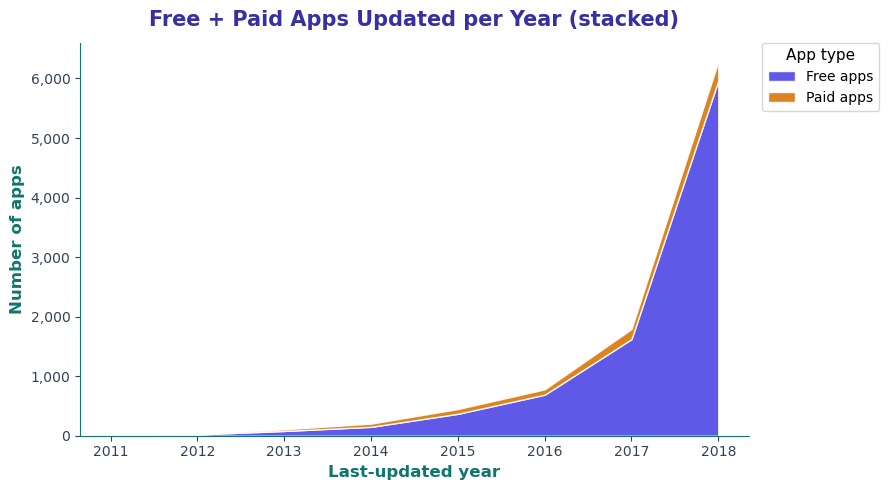

In [171]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
ax.stackplot(yearly_type.index, yearly_type["Free"], yearly_type["Paid"], labels=["Free apps", "Paid apps"],
             colors=[type_colors["Free"], type_colors["Paid"]], alpha=0.9, edgecolor="white", linewidth=1)
ax.set_xticks(yearly_type.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Free + Paid Apps Updated per Year (stacked)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="App type",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M37_stackplot")

#### M38 · Cumulative histogram (ECDF-style)
`cumulative=True` shows what share of apps are below each rating.

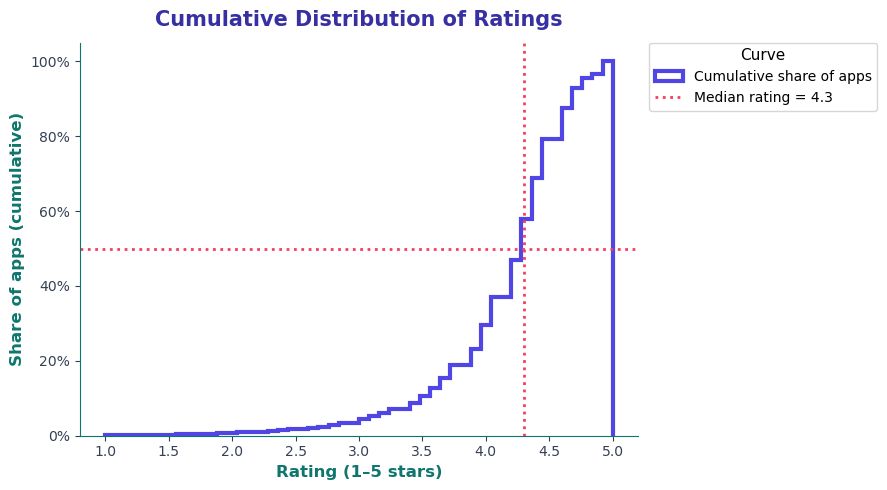

In [172]:
med = rated["Rating"].median()
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(rated["Rating"], bins=50, cumulative=True, density=True, histtype="step", linewidth=3,
        color="#4F46E5", label="Cumulative share of apps")
ax.axhline(0.5, color="#F43F5E", linestyle=":", linewidth=2)
ax.axvline(med, color="#F43F5E", linestyle=":", linewidth=2, label=f"Median rating = {med:.1f}")
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_title("Cumulative Distribution of Ratings", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Share of apps (cumulative)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Curve",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M38_cumulative")

#### M39 · Hide spines and add text
Cleaner look: hide the top and right borders and write a note on the chart.

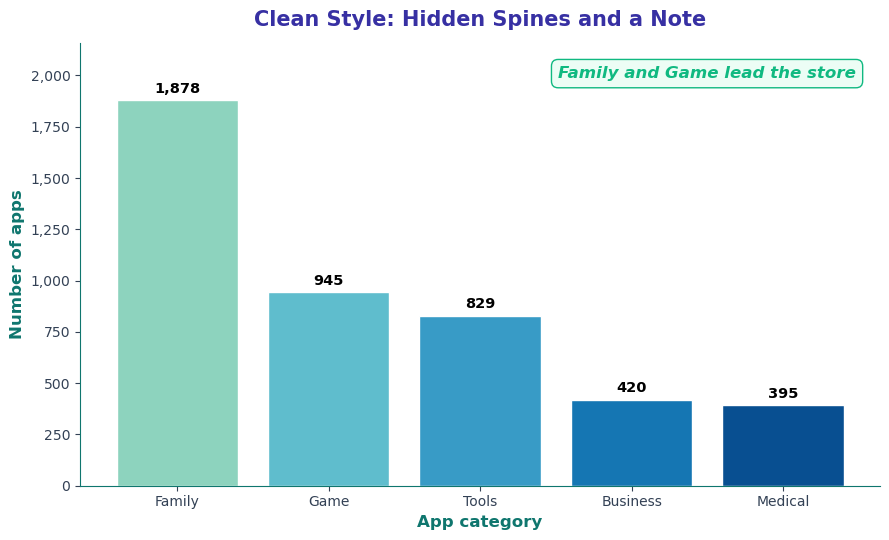

In [173]:
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.bar(top10_names[:5], top10.values[:5], color=plt.cm.GnBu(np.linspace(0.45, 0.95, 5)), edgecolor="white", linewidth=1)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=10.5, fontweight="bold")
ax.margins(y=0.15)
ax.spines[["top", "right"]].set_visible(False)
ax.text(0.97, 0.92, "Family and Game lead the store", transform=ax.transAxes, ha="right", fontsize=12,
        style="italic", fontweight="bold", color="#10B981",
        bbox=dict(boxstyle="round,pad=0.4", fc="#ECFDF5", ec="#10B981"))
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Clean Style: Hidden Spines and a Note", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M39_spines_text")

#### M40 · Table inside a figure
`ax.table()` shows data as a table.

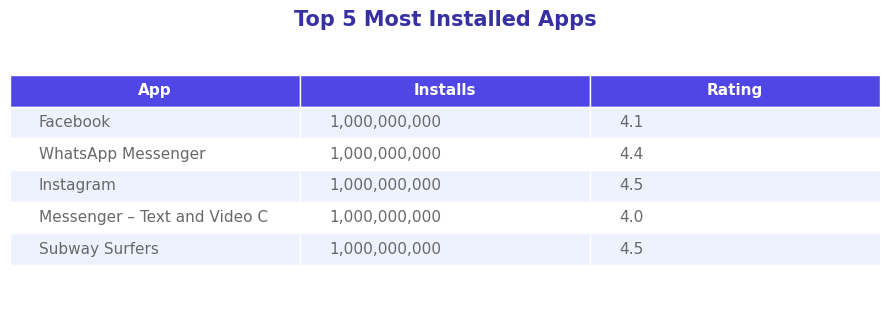

In [174]:
t5 = df.nlargest(5, "Installs")[["App", "Installs", "Rating"]].copy()
t5["Installs"] = t5["Installs"].map("{:,}".format)
t5["App"] = t5["App"].str.slice(0, 28)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.axis("off")
tbl = ax.table(cellText=t5.values, colLabels=["App", "Installs", "Rating"], loc="center", cellLoc="left")
tbl.auto_set_font_size(False); tbl.set_fontsize(11); tbl.scale(1, 1.8)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor("white")
    if r == 0:
        cell.set_facecolor("#4F46E5"); cell.set_text_props(color="white", fontweight="bold")
    else:
        cell.set_facecolor("#EEF2FF" if r % 2 else "white"); cell.set_text_props(color="dimgray")
ax.set_title("Top 5 Most Installed Apps", fontsize=15, fontweight="bold", color="#3730A3", pad=10)
plt.tight_layout()
save_fig("M40_table")

#### M41 · Bubble chart (size and colour as data)
Each bubble is a category: size = number of apps, colour = total installs.

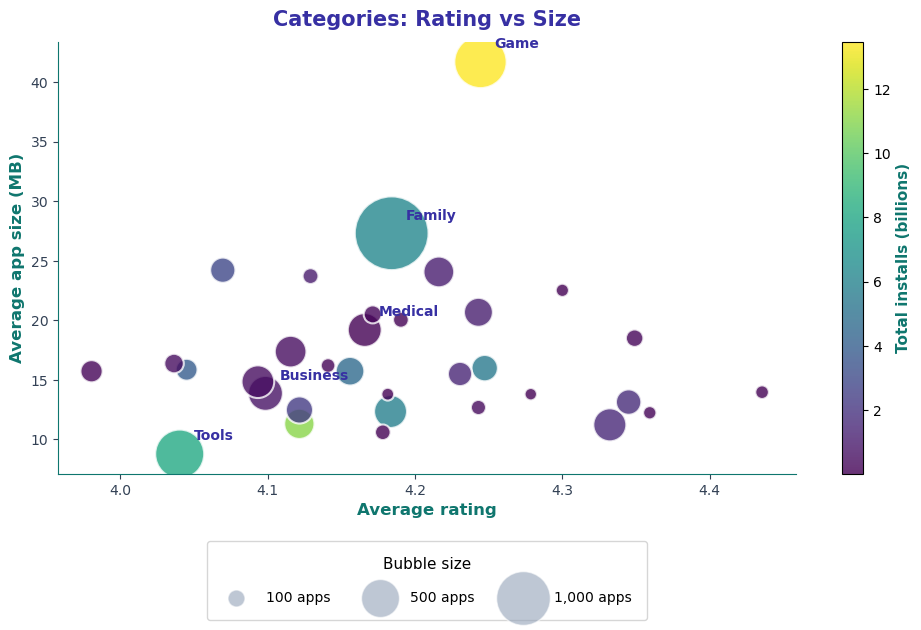

In [175]:
fig, ax = plt.subplots(figsize=(10, 6.5))
sc = ax.scatter(cat_stats["Avg_Rating"], cat_stats["Avg_Size_MB"], s=cat_stats["Apps"] * 1.5,
                c=cat_stats["Total_Installs"] / 1e9, cmap="viridis", alpha=0.8, edgecolor="white", linewidth=1.5)
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Total installs (billions)", fontsize=11, fontweight="bold", color="#0F766E")
for name, row in cat_stats.head(5).iterrows():
    ax.annotate(str(name), (row["Avg_Rating"], row["Avg_Size_MB"]), xytext=(10, 10), textcoords="offset points",
                fontsize=10, fontweight="bold", color="#3730A3")
sizes = [100, 500, 1000]
handles = [ax.scatter([], [], s=n * 1.5, color="#94A3B8", alpha=0.6, edgecolor="white") for n in sizes]
ax.legend(
    handles,
    [f'{n:,} apps' for n in sizes],
    title="Bubble size",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.14),
    ncol=3,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
    labelspacing=1.4,
    borderpad=1.1,
    handletextpad=1.2,
    columnspacing=2.5,
)
ax.set_title("Categories: Rating vs Size", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Average rating", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Average app size (MB)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("M41_bubble")

#### M42 · Highlight a region with axvspan()
Shade part of the x-axis.

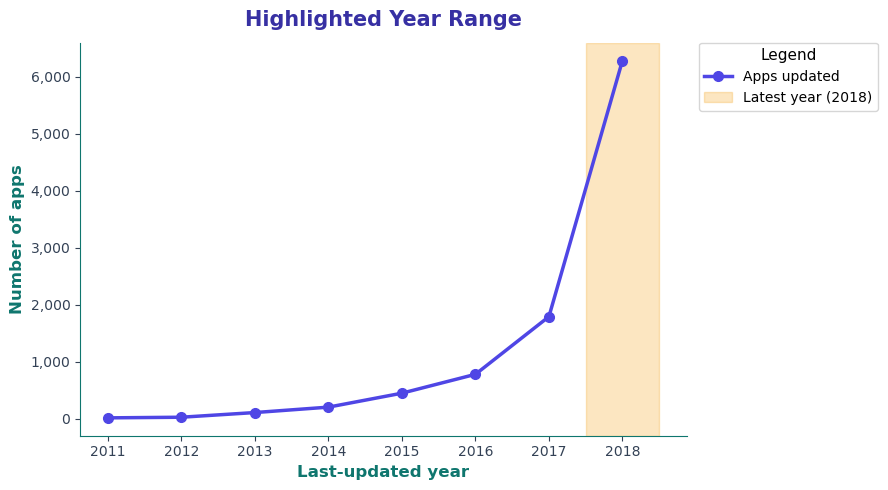

In [176]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(yearly.index, yearly.values, marker="o", color="#4F46E5", linewidth=2.5, markersize=7, label="Apps updated")
ax.axvspan(2017.5, 2018.5, color="#F59E0B", alpha=0.25, label="Latest year (2018)")
ax.set_xticks(yearly.index)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Highlighted Year Range", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Legend",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("M42_axvspan")

#### M43 · Global style with rc_context()
Change fonts and colours (rcParams) for one block of code only.

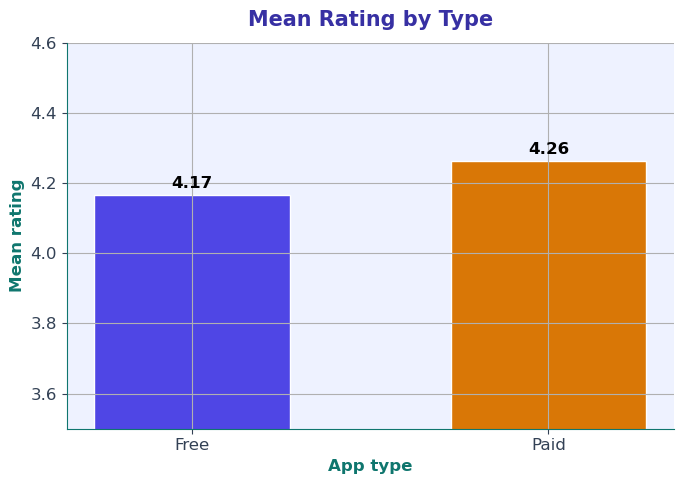

In [177]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

with mpl.rc_context({"font.size": 12, "axes.facecolor": "#EEF2FF", "axes.grid": True}):
    fig, ax = plt.subplots(figsize=(7, 5))
    means = rated.groupby("Type", observed=True)["Rating"].mean()
    ax.bar([str(i) for i in means.index], means.values, color=[type_colors[str(i)] for i in means.index],
           edgecolor="white", width=0.55)
    for c in ax.containers:
        ax.bar_label(c, fmt="{:.2f}", padding=3, fontsize=12, fontweight="bold")
    ax.set_ylim(3.5, 4.6)
    ax.set_title("Mean Rating by Type", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
    ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
    ax.set_ylabel("Mean rating", fontsize=12, fontweight="bold", color="#0F766E")
    ax.tick_params(axis="x", colors="#334155")
    ax.tick_params(axis="y", colors="#334155")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#0F766E")
    plt.tight_layout()
    save_fig("M43_rc_context")

#### M44 · Mosaic layout with subplot_mosaic()
Describe the layout with letters. Same letter = same chart area.

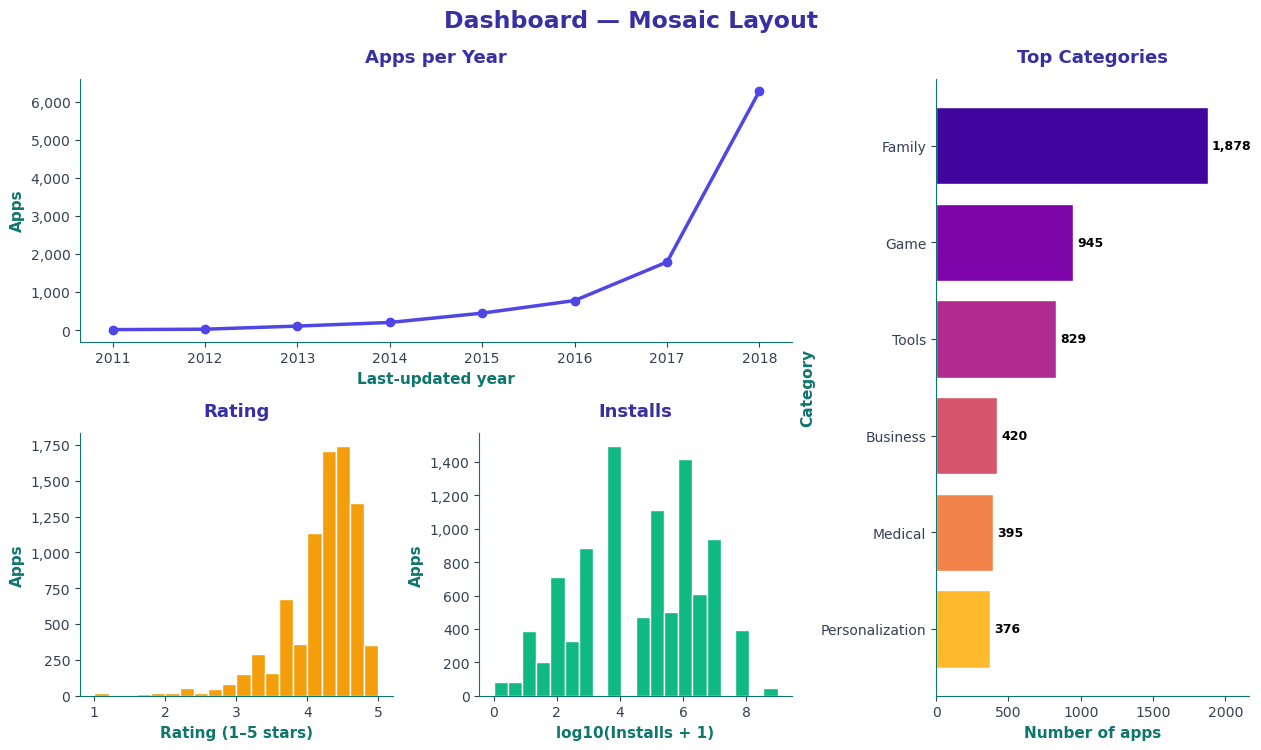

In [178]:
fig, axd = plt.subplot_mosaic("AAB;CDB", figsize=(12.5, 7), layout="constrained")
axd["A"].plot(yearly.index, yearly.values, marker="o", color="#4F46E5", linewidth=2.5)
axd["A"].set_xticks(yearly.index)
axd["A"].set_title("Apps per Year", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axd["A"].set_xlabel("Last-updated year", fontsize=11, fontweight="bold", color="#0F766E")
axd["A"].set_ylabel("Apps", fontsize=11, fontweight="bold", color="#0F766E")
axd["A"].tick_params(axis="x", colors="#334155")
axd["A"].tick_params(axis="y", colors="#334155")
axd["A"].spines[["top", "right"]].set_visible(False)
axd["A"].spines[["left", "bottom"]].set_color("#0F766E")
axd["B"].barh(top10_names[:6][::-1], top10.values[:6][::-1], color=plt.cm.plasma(np.linspace(0.85, 0.1, 6)), edgecolor="white")
for c in axd["B"].containers:
    axd["B"].bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9, fontweight="bold")
axd["B"].margins(x=0.15)
axd["B"].set_title("Top Categories", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axd["B"].set_xlabel("Number of apps", fontsize=11, fontweight="bold", color="#0F766E")
axd["B"].set_ylabel("Category", fontsize=11, fontweight="bold", color="#0F766E")
axd["B"].tick_params(axis="x", colors="#334155")
axd["B"].tick_params(axis="y", colors="#334155")
axd["B"].spines[["top", "right"]].set_visible(False)
axd["B"].spines[["left", "bottom"]].set_color("#0F766E")
axd["C"].hist(rated["Rating"], bins=20, color="#F59E0B", edgecolor="white")
axd["C"].set_title("Rating", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axd["C"].set_xlabel("Rating (1–5 stars)", fontsize=11, fontweight="bold", color="#0F766E")
axd["C"].set_ylabel("Apps", fontsize=11, fontweight="bold", color="#0F766E")
axd["C"].tick_params(axis="x", colors="#334155")
axd["C"].tick_params(axis="y", colors="#334155")
axd["C"].spines[["top", "right"]].set_visible(False)
axd["C"].spines[["left", "bottom"]].set_color("#0F766E")
axd["D"].hist(df["Log_Installs"], bins=20, color="#10B981", edgecolor="white")
axd["D"].set_title("Installs", fontsize=13, fontweight="bold", color="#3730A3", pad=12)
axd["D"].set_xlabel("log10(Installs + 1)", fontsize=11, fontweight="bold", color="#0F766E")
axd["D"].set_ylabel("Apps", fontsize=11, fontweight="bold", color="#0F766E")
axd["D"].tick_params(axis="x", colors="#334155")
axd["D"].tick_params(axis="y", colors="#334155")
axd["D"].spines[["top", "right"]].set_visible(False)
axd["D"].spines[["left", "bottom"]].set_color("#0F766E")
for k in "ACD":
    axd[k].yaxis.set_major_formatter("{x:,.0f}")
fig.suptitle("Dashboard — Mosaic Layout", fontsize=17, fontweight="bold", color="#3730A3", y=1.05)
save_fig("M44_mosaic")

✅ **Matplotlib section finished.**

---

<img src="icons/section_seaborn.png" alt="Seaborn section banner" width="700">

# 4. 🎨 SEABORN — statistical charts
Seaborn is built on top of matplotlib. It works directly with DataFrames and gives nicer defaults.

### 4.0 Data prepared for seaborn

In [179]:
top6_names = [str(c) for c in df["Category"].value_counts().head(6).index]
top10_list = [str(c) for c in df["Category"].value_counts().head(10).index]

# seaborn is happier with plain text columns for subsets (no unused categories)
dfs = df.copy()
for col in ["Category", "Type", "Content_Rating"]:
    dfs[col] = dfs[col].astype(str)

rated_s = dfs.dropna(subset=["Rating"])
sample = rated_s.sample(1500, random_state=1)     # small sample for slow plots
num_cols = ["Rating", "Log_Reviews", "Log_Installs", "Size_MB"]
print(dfs.shape, rated_s.shape, sample.shape)

(9659, 32) (8196, 32) (1500, 32)


### 4.1 Theme and counting plots

#### S01 · Set a global theme with set_theme()
Style, palette and font scale for all following charts.

In [180]:
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.0)
print("Seaborn theme set")

Seaborn theme set


#### S02 · countplot()
Counts rows per category — no need for `value_counts()` first.

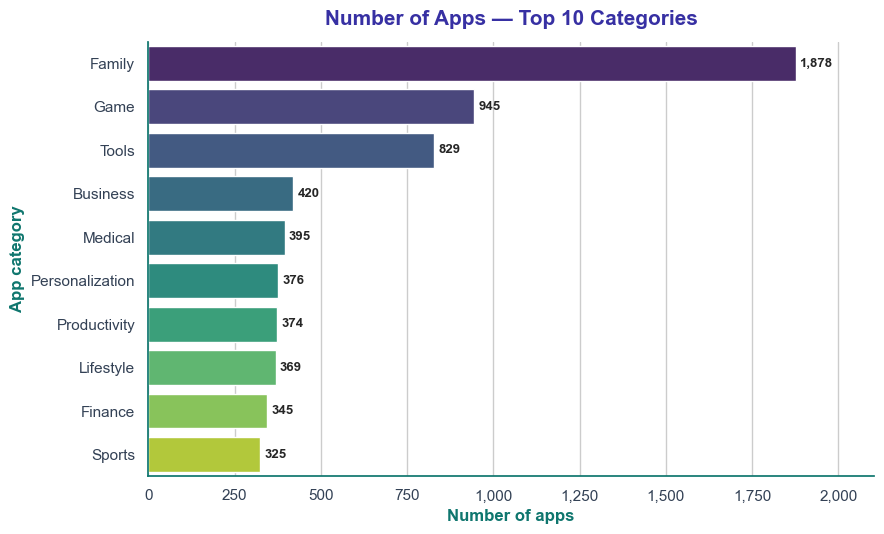

In [181]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.countplot(data=dfs, y="Category", order=top10_list, hue="Category", hue_order=top10_list, palette=sns.color_palette("viridis", 10), legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9.5, fontweight="bold")
ax.margins(x=0.12)
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Number of Apps — Top 10 Categories", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S02_countplot")

#### S03 · countplot() with hue
`hue` splits each bar by another column.

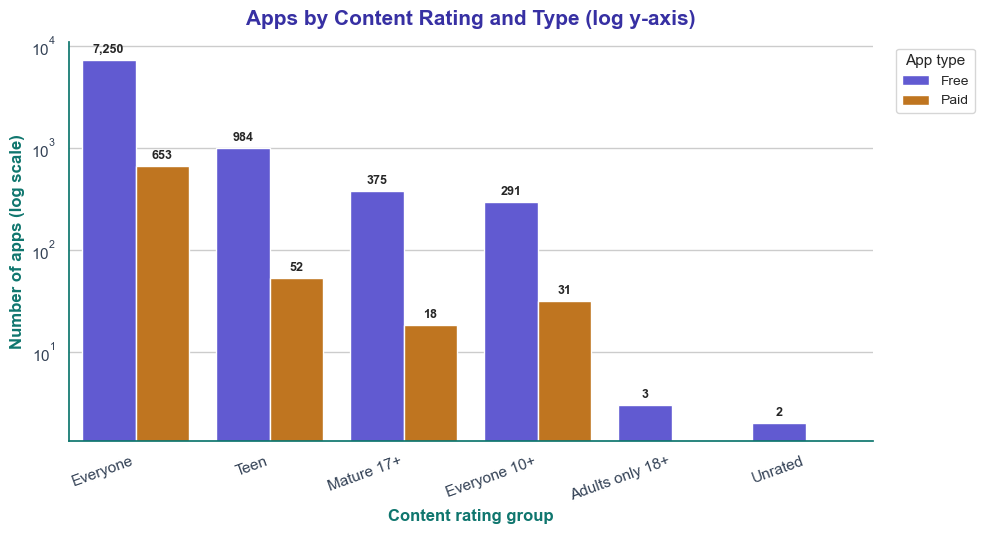

In [182]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.countplot(data=dfs, x="Content_Rating", hue="Type", palette=type_colors, ax=ax,
              order=dfs["Content_Rating"].value_counts().index, edgecolor="white")
ax.set_yscale("log")
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=9, fontweight="bold")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_title("Apps by Content Rating and Type (log y-axis)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps (log scale)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S03_countplot_hue")

#### S04 · barplot() — mean with confidence interval
Bar height = mean. The line on top = 95% confidence interval.

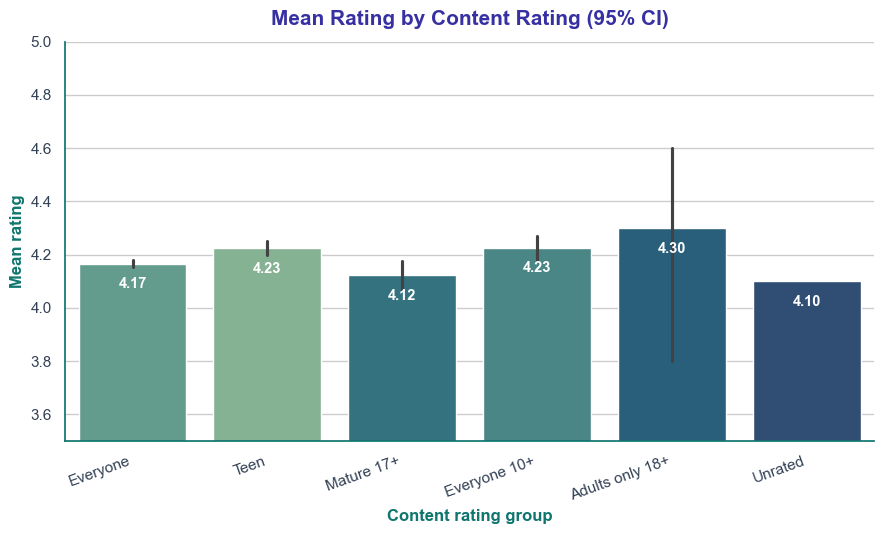

In [183]:
order_cr = rated_s["Content_Rating"].value_counts().index
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=rated_s, x="Content_Rating", y="Rating", order=order_cr, hue="Content_Rating",
            legend=False, palette=sns.color_palette("crest", 6), edgecolor="white", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", label_type="edge", padding=-20, color="white", fontweight="bold", fontsize=10.5)
ax.set_ylim(3.5, 5)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_title("Mean Rating by Content Rating (95% CI)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Mean rating", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S04_barplot")

#### S05 · barplot() with standard deviation bars
`errorbar='sd'` and `capsize` change what the error bar means.

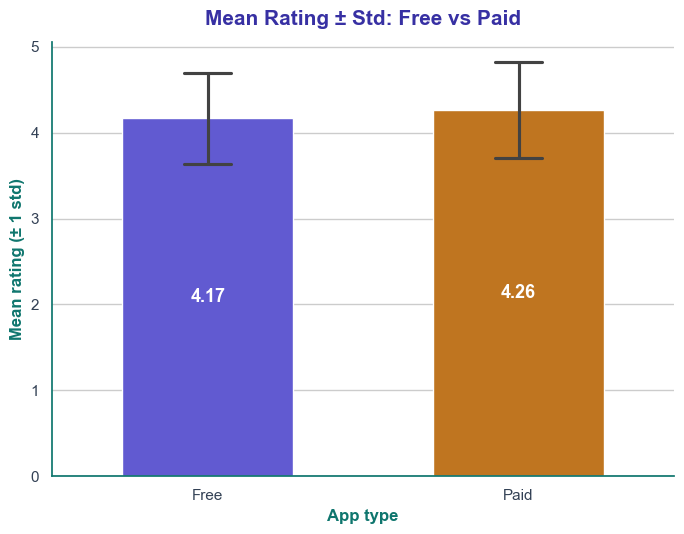

In [184]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.barplot(data=rated_s, x="Type", y="Rating", errorbar="sd", capsize=0.15, hue="Type", palette=type_colors,
            legend=False, edgecolor="white", width=0.55, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", label_type="center", color="white", fontweight="bold", fontsize=13)
ax.set_title("Mean Rating ± Std: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Mean rating (± 1 std)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S05_barplot_sd")

### 4.2 Distributions

#### S06 · histplot()
Histogram with simple settings.

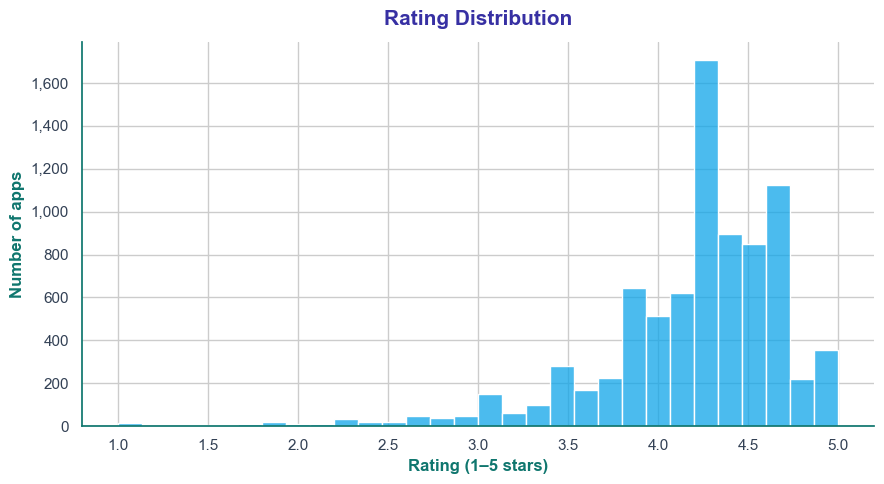

In [185]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=rated_s, x="Rating", bins=30, color="#0EA5E9", edgecolor="white", ax=ax)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Rating Distribution", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S06_histplot")

#### S07 · histplot() with kde and hue
Add a smooth curve with `kde=True`. `common_norm=False` scales each group on its own.

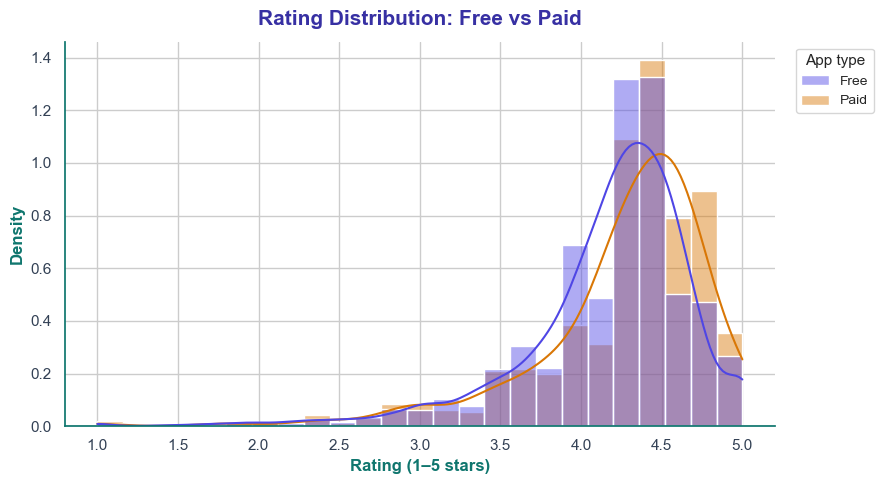

In [186]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=rated_s, x="Rating", hue="Type", kde=True, stat="density", common_norm=False, bins=25,
             palette=type_colors, edgecolor="white", alpha=0.45, ax=ax)
ax.set_title("Rating Distribution: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Density", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S07_histplot_kde_hue")

#### S08 · kdeplot()
A smooth density curve.

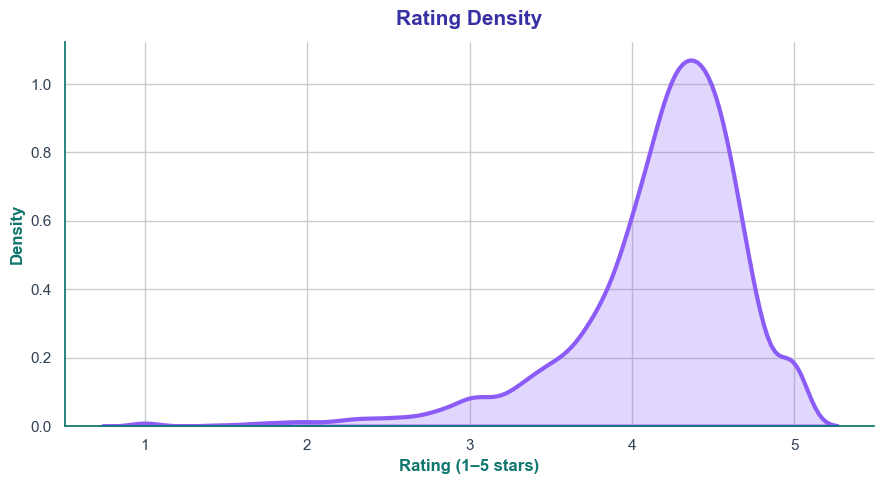

In [187]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=rated_s, x="Rating", color="#8B5CF6", linewidth=3, fill=True, alpha=0.25, ax=ax)
ax.set_title("Rating Density", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Density", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S08_kdeplot")

#### S09 · kdeplot() filled, one curve per group
`fill=True` and `hue` compare several groups.

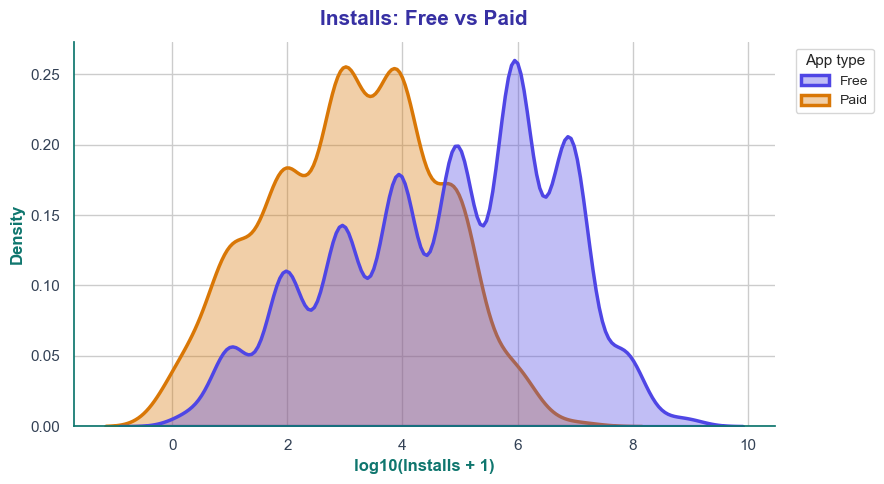

In [188]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(data=dfs, x="Log_Installs", hue="Type", fill=True, common_norm=False, alpha=0.35, linewidth=2.5,
            palette=type_colors, ax=ax)
ax.set_title("Installs: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Density", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S09_kdeplot_fill")

#### S10 · 2D kdeplot()
Density contours with two variables.

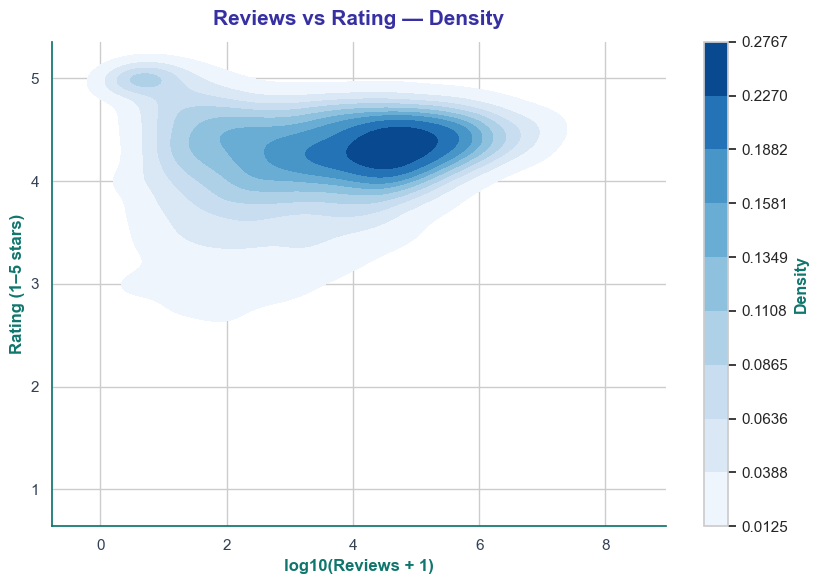

In [189]:
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.kdeplot(data=rated_s, x="Log_Reviews", y="Rating", fill=True, cmap="Blues", thresh=0.05, cbar=True,
            cbar_kws={"label": "Density"}, ax=ax)
fig.axes[-1].set_ylabel("Density", fontsize=11.5, fontweight="bold", color="#0F766E")
ax.set_title("Reviews vs Rating — Density", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S10_kdeplot_2d")

#### S11 · ecdfplot()
Empirical CDF: what share of apps have a value up to X.

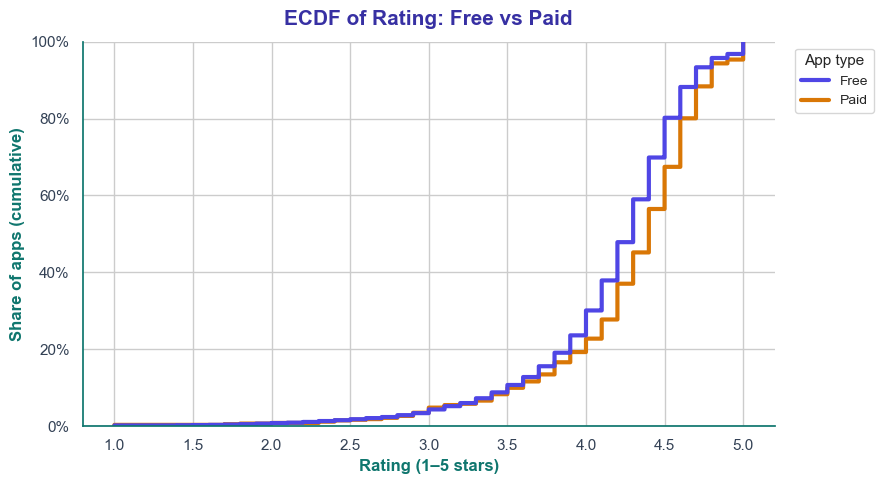

In [190]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
sns.ecdfplot(data=rated_s, x="Rating", hue="Type", palette=type_colors, linewidth=3, ax=ax)
ax.yaxis.set_major_formatter("{x:.0%}")
ax.set_title("ECDF of Rating: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Share of apps (cumulative)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S11_ecdfplot")

#### S12 · rugplot()
Small ticks on the axis for every data point. Combined here with a KDE.

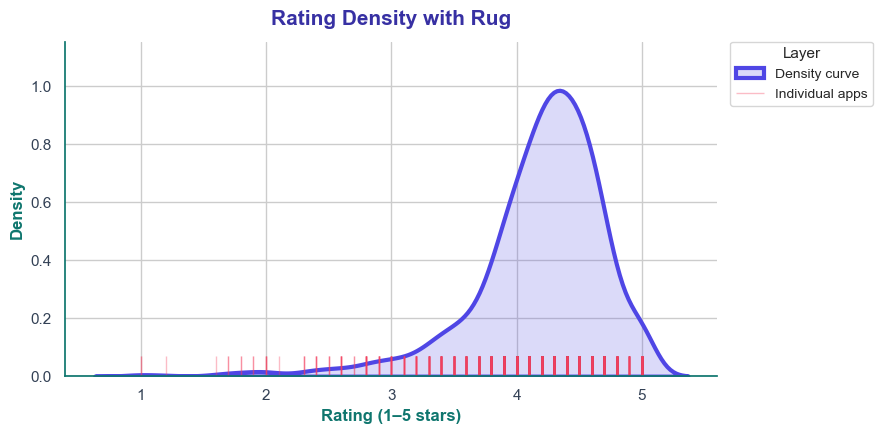

In [191]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.kdeplot(data=sample, x="Rating", color="#4F46E5", linewidth=3, fill=True, alpha=0.2, label="Density curve", ax=ax)
sns.rugplot(data=sample, x="Rating", height=0.06, alpha=0.35, color="#F43F5E", label="Individual apps", ax=ax)
ax.set_title("Rating Density with Rug", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Density", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Layer",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S12_rugplot")

#### S13 · histplot() stacked
`multiple='stack'` stacks groups on top of each other.

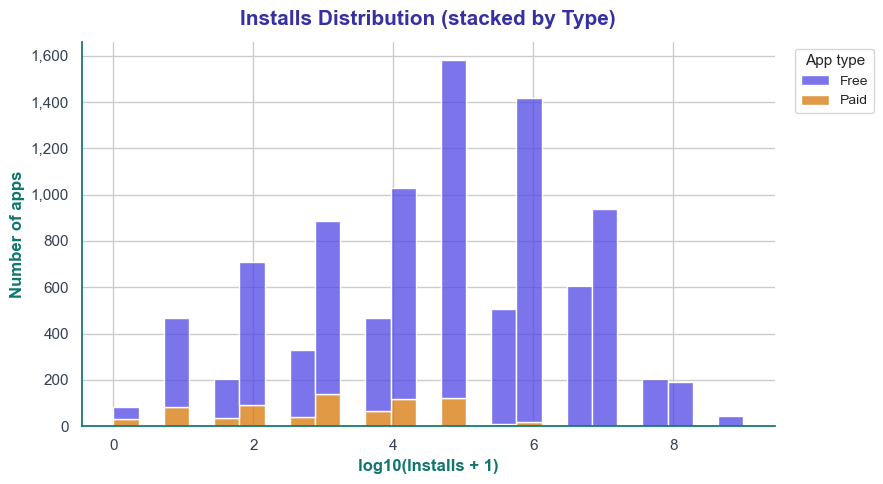

In [192]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=dfs, x="Log_Installs", hue="Type", multiple="stack", bins=25, palette=type_colors,
             edgecolor="white", ax=ax)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Installs Distribution (stacked by Type)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S13_histplot_stack")

#### S14 · displot()
Figure-level function. `col=` makes one chart per group.

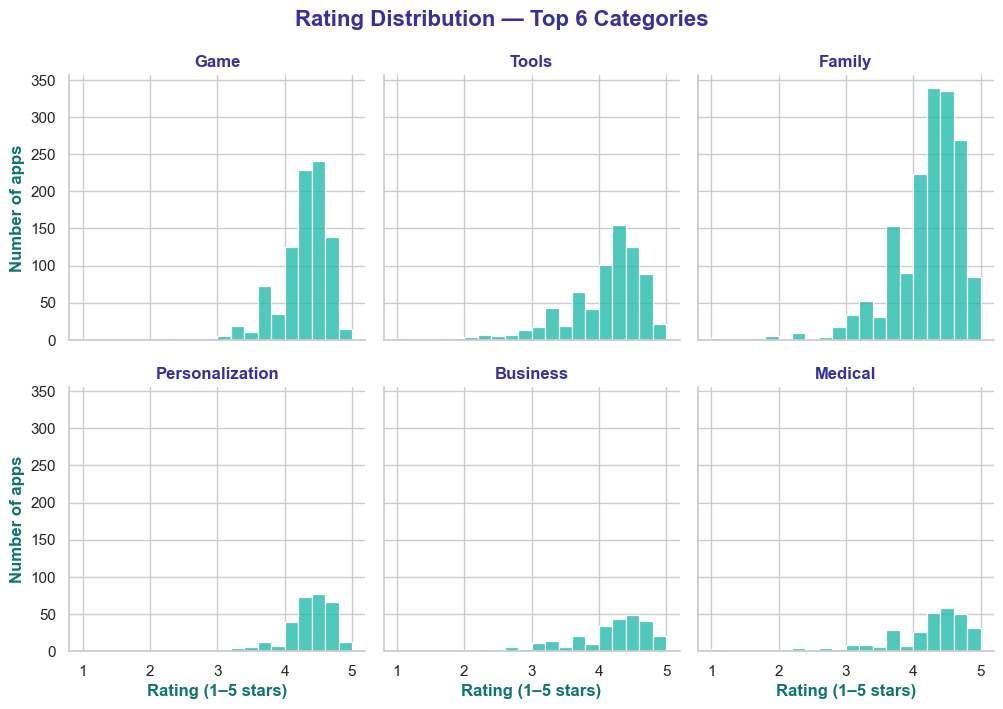

In [193]:
g = sns.displot(data=rated_s[rated_s["Category"].isin(top6_names)], x="Rating", col="Category", col_wrap=3,
                bins=20, height=3.4, color="#14B8A6", edgecolor="white")
g.set_titles("{col_name}", size=12, fontweight="bold", color="#3730A3")
g.set_axis_labels("Rating (1–5 stars)", "Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Rating Distribution — Top 6 Categories", fontsize=16, fontweight="bold", color="#3730A3", y=1.04)
save_fig("S14_displot")

### 4.3 Comparing groups (categorical plots)

#### S15 · boxplot()
Median, quartiles and outliers for each group.

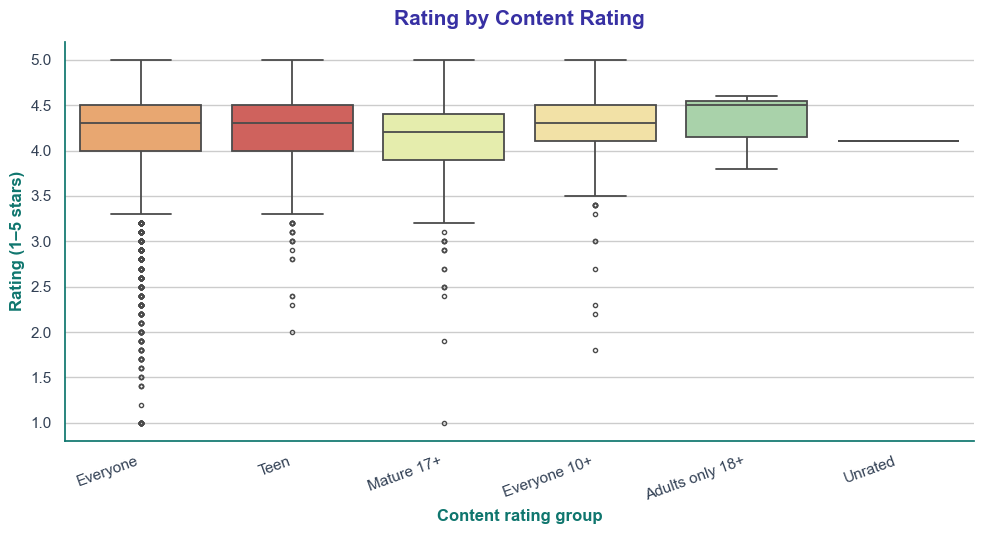

In [194]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=rated_s, x="Content_Rating", y="Rating", order=rated_s["Content_Rating"].value_counts().index,
            hue="Content_Rating", legend=False, palette=sns.color_palette("Spectral", 6), linewidth=1.3, fliersize=3, ax=ax)
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.set_title("Rating by Content Rating", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S15_boxplot")

#### S16 · violinplot()
Box plot + density shape. `inner='quartile'` marks the quartiles.

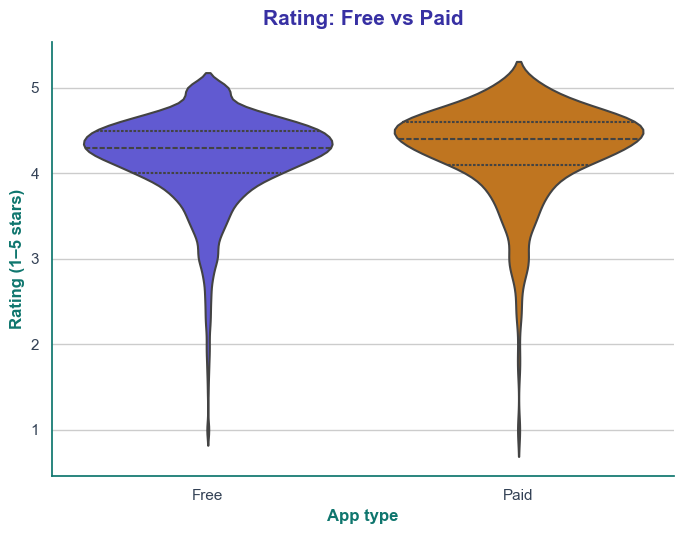

In [195]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.violinplot(data=rated_s, x="Type", y="Rating", inner="quartile", hue="Type", palette=type_colors,
               legend=False, linewidth=1.5, ax=ax)
ax.set_title("Rating: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S16_violinplot")

#### S17 · Split violinplot()
With a 2-value `hue` and `split=True` the two halves of the violin are compared.

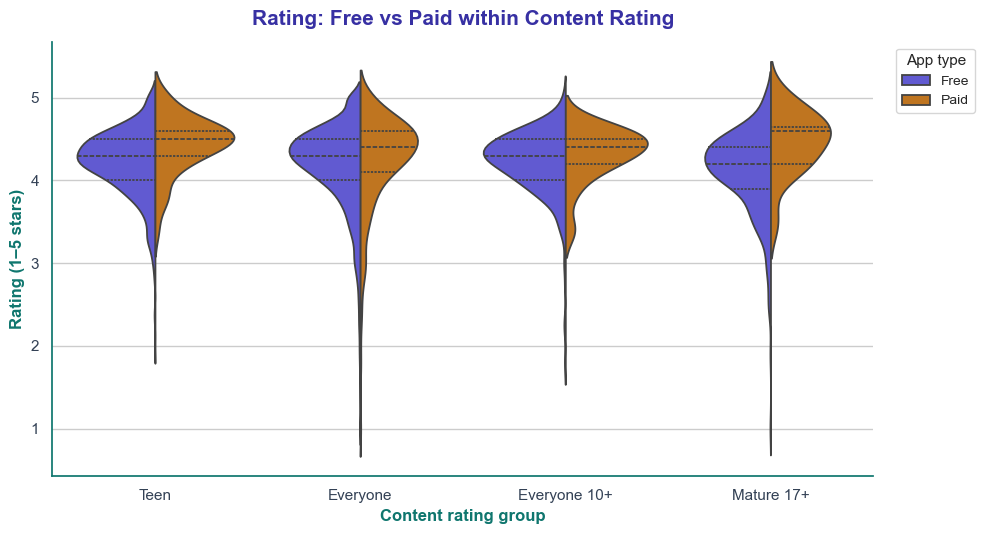

In [196]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

sub = rated_s[rated_s["Content_Rating"].isin(["Everyone", "Teen", "Mature 17+", "Everyone 10+"])]
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=sub, x="Content_Rating", y="Rating", hue="Type", split=True, palette=type_colors,
               inner="quartile", linewidth=1.3, ax=ax)
ax.set_title("Rating: Free vs Paid within Content Rating", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S17_violin_split")

#### S18 · boxenplot()
A box plot with more detail in the tails — good for big data.

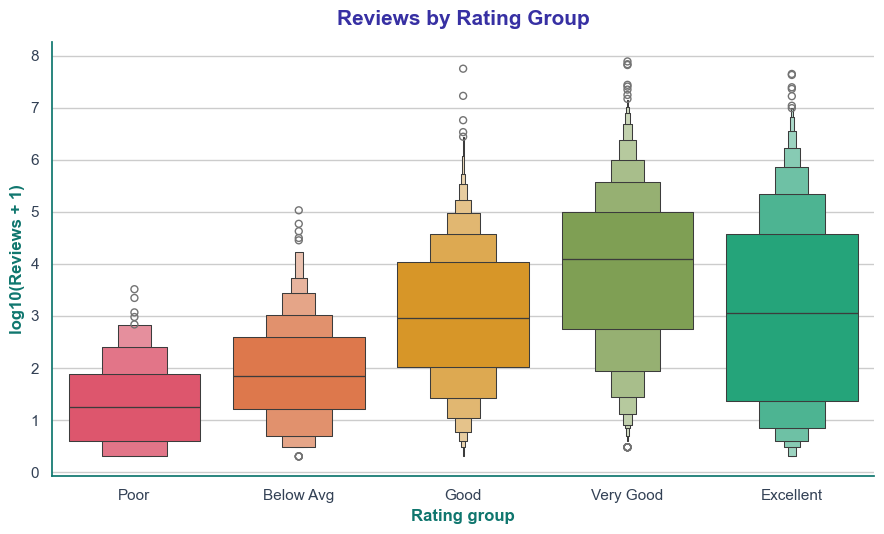

In [197]:
rating_order = ["Poor", "Below Avg", "Good", "Very Good", "Excellent"]
rating_colors = {"Poor": "#F43F5E", "Below Avg": "#F56F34", "Good": "#F49E0B", "Very Good": "#81AC47", "Excellent": "#10B981"}

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxenplot(data=dfs, x="Rating_Group", y="Log_Reviews", order=rating_order, hue="Rating_Group",
              hue_order=rating_order, palette=rating_colors, legend=False, ax=ax)
ax.set_title("Reviews by Rating Group", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S18_boxenplot")

#### S19 · stripplot()
Every dot is an app, with a little random jitter.

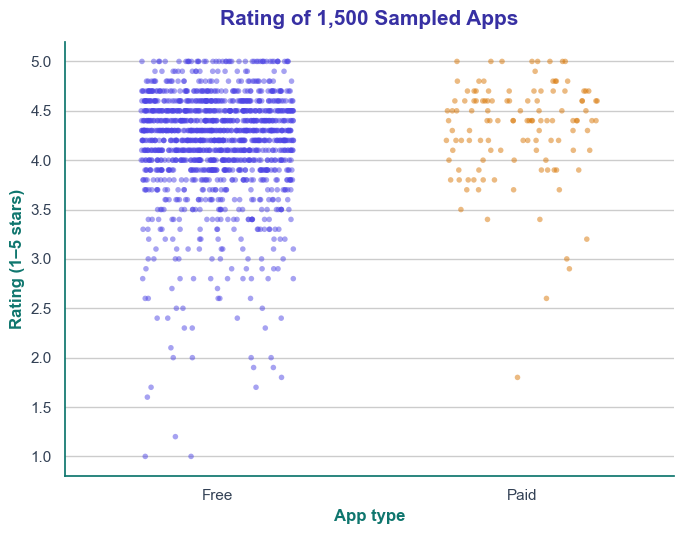

In [198]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.stripplot(data=sample, x="Type", y="Rating", hue="Type", palette=type_colors, legend=False,
              alpha=0.5, jitter=0.25, size=4, ax=ax)
ax.set_title("Rating of 1,500 Sampled Apps", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S19_stripplot")

#### S20 · swarmplot()
Like a strip plot but dots never overlap. It is slow, so we use a small sample.

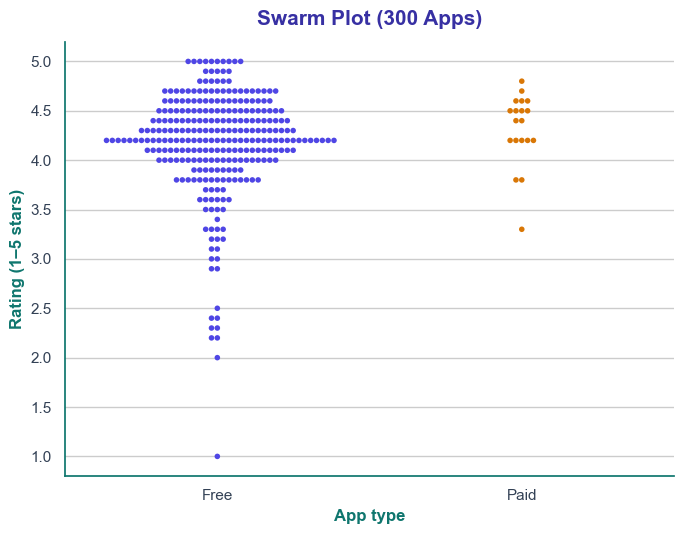

In [199]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

small = rated_s.sample(300, random_state=3)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.swarmplot(data=small, x="Type", y="Rating", hue="Type", palette=type_colors, legend=False, size=4, ax=ax)
ax.set_title("Swarm Plot (300 Apps)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S20_swarmplot")

#### S21 · Box plot + strip plot together
Layer two plots on the same axes.

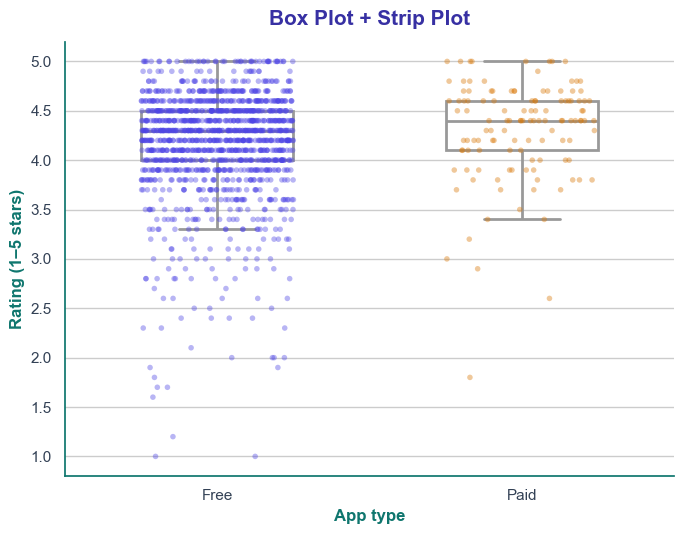

In [200]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.boxplot(data=sample, x="Type", y="Rating", color="white", showfliers=False, width=0.5, linewidth=2, ax=ax)
sns.stripplot(data=sample, x="Type", y="Rating", hue="Type", palette=type_colors, legend=False,
              alpha=0.4, jitter=0.25, size=4, ax=ax)
ax.set_title("Box Plot + Strip Plot", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S21_box_strip")

#### S22 · pointplot()
Shows how the mean changes across ordered groups.

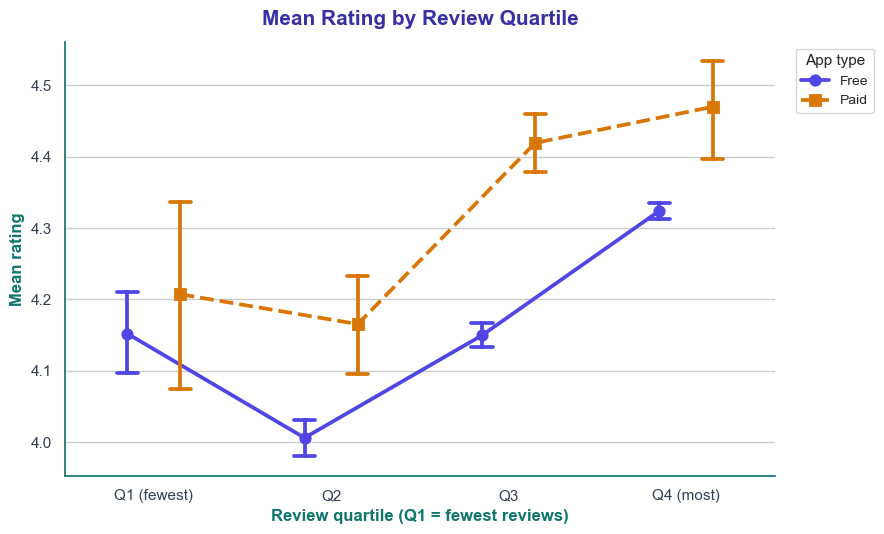

In [201]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.pointplot(data=dfs, x="Review_Quartile", y="Rating", hue="Type", palette=type_colors, dodge=0.3,
              markers=["o", "s"], linestyles=["-", "--"], capsize=0.12, ax=ax)
ax.set_title("Mean Rating by Review Quartile", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Review quartile (Q1 = fewest reviews)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Mean rating", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S22_pointplot")

#### S23 · catplot()
Figure-level categorical plot. `kind` can be bar, box, violin, strip, swarm, point ...

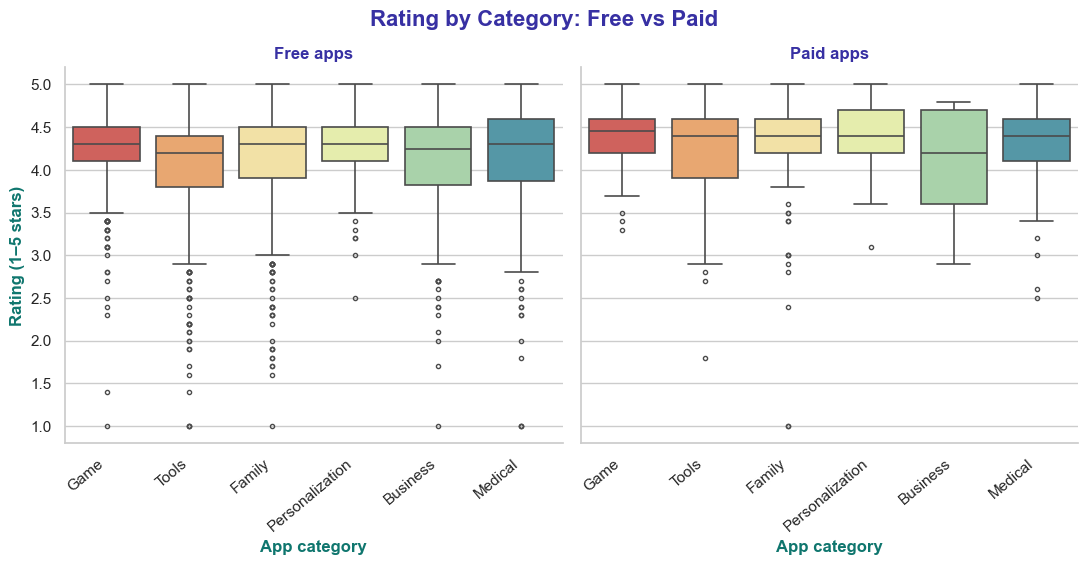

In [202]:
g = sns.catplot(data=rated_s[rated_s["Category"].isin(top6_names)], x="Category", y="Rating", kind="box",
                col="Type", height=4.8, aspect=1.15, hue="Category", palette=sns.color_palette("Spectral", 6), legend=False,
                linewidth=1.2, fliersize=3)
g.set_titles("{col_name} apps", size=12, fontweight="bold", color="#3730A3")
for ax in g.axes.flat:
    plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
g.set_axis_labels("App category", "Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Rating by Category: Free vs Paid", fontsize=16, fontweight="bold", color="#3730A3", y=1.04)
save_fig("S23_catplot")

### 4.4 Relationships between two numbers

#### S24 · lineplot()
Mean rating per year. The shaded area is the confidence interval.

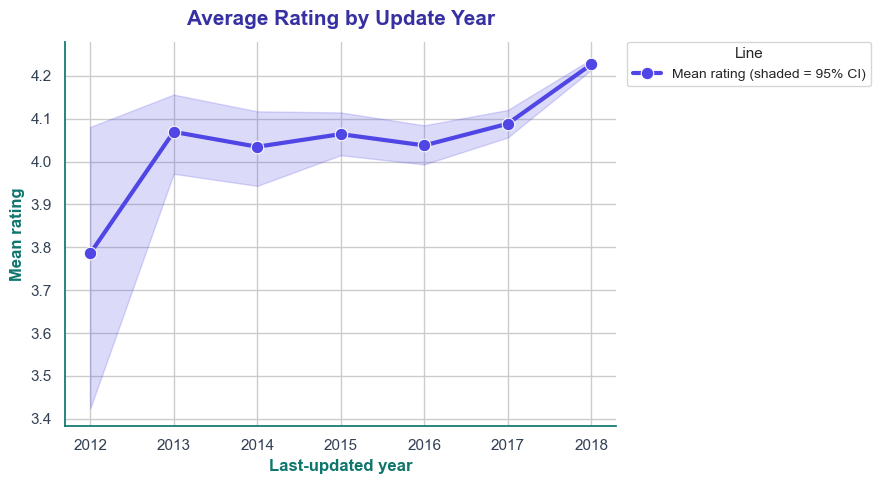

In [203]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=rated_s[rated_s["Year"] >= 2012], x="Year", y="Rating", marker="o", markersize=9, linewidth=3,
             color="#4F46E5", label="Mean rating (shaded = 95% CI)", ax=ax)
ax.set_xticks(sorted(rated_s.loc[rated_s["Year"] >= 2012, "Year"].unique()))
ax.set_title("Average Rating by Update Year", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Mean rating", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    title="Line",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S24_lineplot")

#### S25 · lineplot() with hue
One line per group.

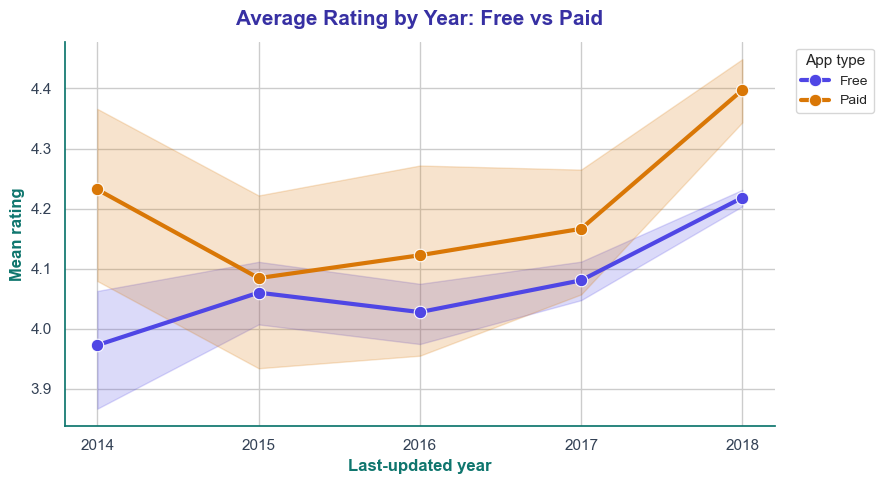

In [204]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=rated_s[rated_s["Year"] >= 2014], x="Year", y="Rating", hue="Type", palette=type_colors,
             marker="o", markersize=9, linewidth=3, ax=ax)
ax.set_xticks(sorted(rated_s.loc[rated_s["Year"] >= 2014, "Year"].unique()))
ax.set_title("Average Rating by Year: Free vs Paid", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Last-updated year", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Mean rating", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S25_lineplot_hue")

#### S26 · scatterplot()
Reviews vs installs.

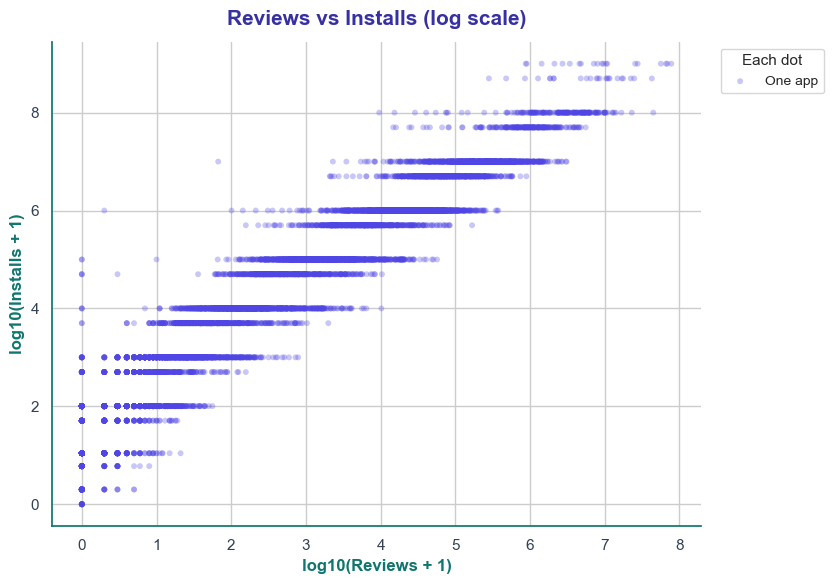

In [205]:
fig, ax = plt.subplots(figsize=(8.5, 6))
sns.scatterplot(data=dfs, x="Log_Reviews", y="Log_Installs", alpha=0.3, s=18, color="#4F46E5", edgecolor="none",
                label="One app", ax=ax)
ax.set_title("Reviews vs Installs (log scale)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="Each dot",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S26_scatterplot")

#### S27 · scatterplot() with hue and size
Colour and size show two more variables.

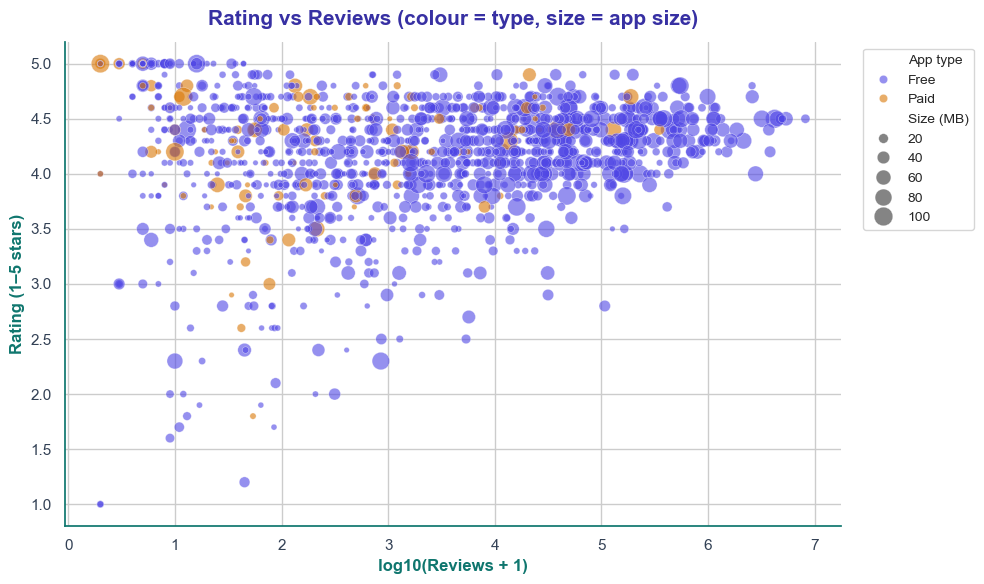

In [206]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

plot_df = sample.rename(columns={"Size_MB": "Size (MB)", "Type": "App type"})
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=plot_df, x="Log_Reviews", y="Rating", hue="App type", size="Size (MB)", palette=type_colors,
                alpha=0.6, sizes=(15, 180), ax=ax)
ax.set_title("Rating vs Reviews (colour = type, size = app size)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S27_scatter_hue_size")

#### S28 · regplot()
Scatter plot + regression line.

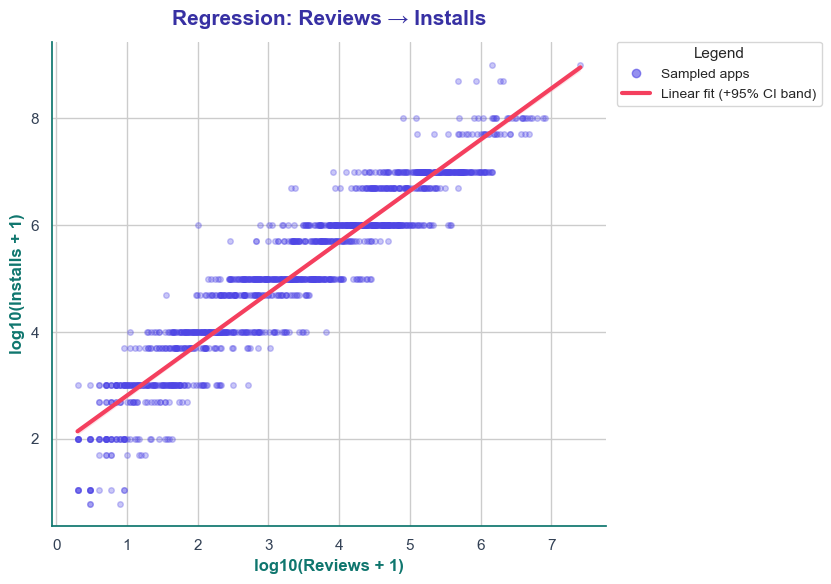

In [207]:
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(8.5, 6))
sns.regplot(data=sample, x="Log_Reviews", y="Log_Installs", ax=ax,
            scatter_kws={"alpha": 0.3, "s": 16, "color": "#4F46E5"}, line_kws={"color": "#F43F5E", "linewidth": 3})
ax.set_title("Regression: Reviews → Installs", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
ax.legend(
    [Line2D([0], [0], marker="o", ls="", color="#4F46E5", alpha=0.6), Line2D([0], [0], color="#F43F5E", lw=3)],
    ["Sampled apps", "Linear fit (+95% CI band)"],
    title="Legend",
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    borderaxespad=0,
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S28_regplot")

#### S29 · lmplot()
Figure-level `regplot` — one regression per group.

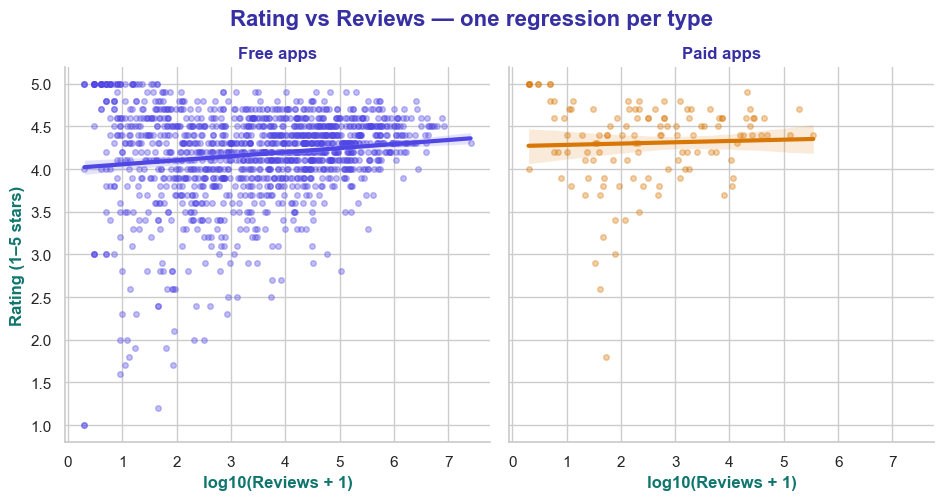

In [208]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

g = sns.lmplot(data=sample, x="Log_Reviews", y="Rating", col="Type", hue="Type", palette=type_colors, height=4.8,
               legend=False, scatter_kws={"alpha": 0.35, "s": 16}, line_kws={"linewidth": 3})
g.set_titles("{col_name} apps", size=12, fontweight="bold", color="#3730A3")
g.set_axis_labels("log10(Reviews + 1)", "Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Rating vs Reviews — one regression per type", fontsize=16, fontweight="bold", color="#3730A3", y=1.04)
save_fig("S29_lmplot")

#### S30 · residplot()
Residuals show how far points are from the regression line. A good fit looks like random noise around 0.

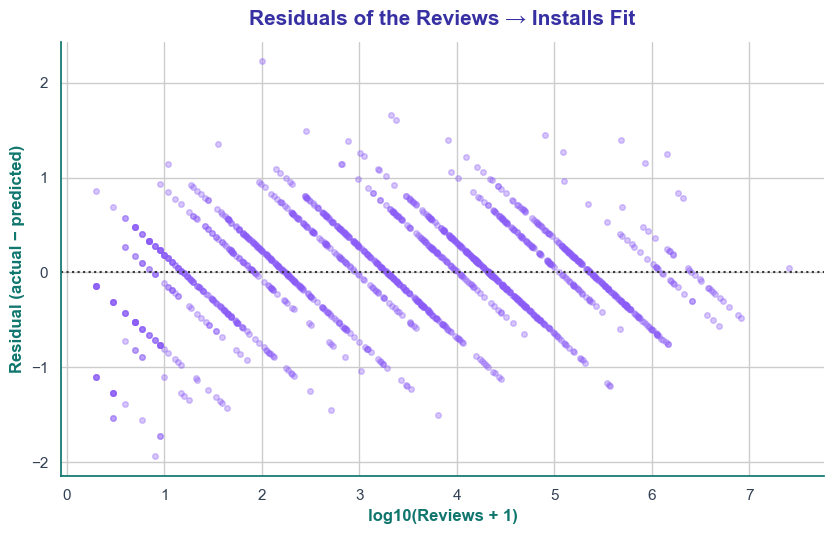

In [209]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.residplot(data=sample, x="Log_Reviews", y="Log_Installs", color="#8B5CF6",
              scatter_kws={"alpha": 0.35, "s": 16}, line_kws={"color": "#F43F5E", "linewidth": 2.5}, ax=ax)
ax.set_title("Residuals of the Reviews → Installs Fit", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Residual (actual − predicted)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S30_residplot")

#### S31 · relplot()
Figure-level scatter / line chart with facets.

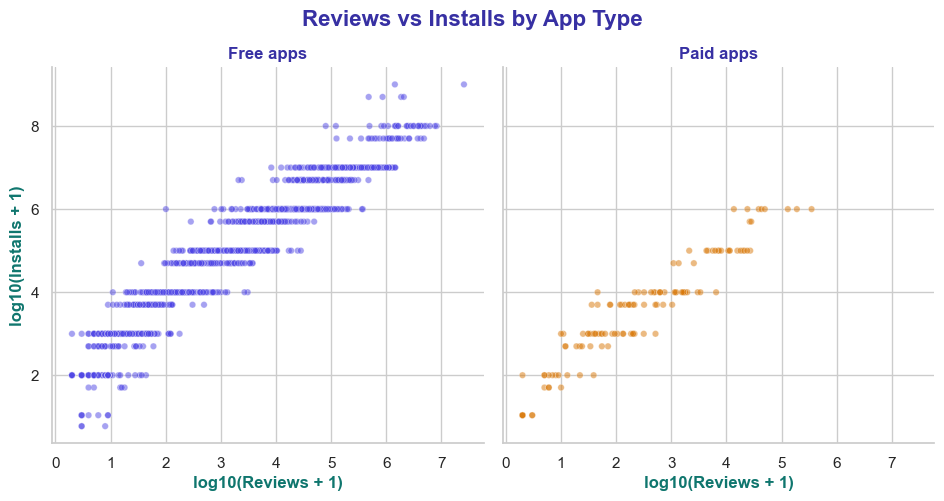

In [210]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

g = sns.relplot(data=sample, x="Log_Reviews", y="Log_Installs", col="Type", hue="Type", palette=type_colors,
                height=4.8, alpha=0.5, s=22, legend=False)
g.set_titles("{col_name} apps", size=12, fontweight="bold", color="#3730A3")
g.set_axis_labels("log10(Reviews + 1)", "log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Reviews vs Installs by App Type", fontsize=16, fontweight="bold", color="#3730A3", y=1.04)
save_fig("S31_relplot")

#### S32 · jointplot() — scatter + histograms
Two variables plus their own distributions.

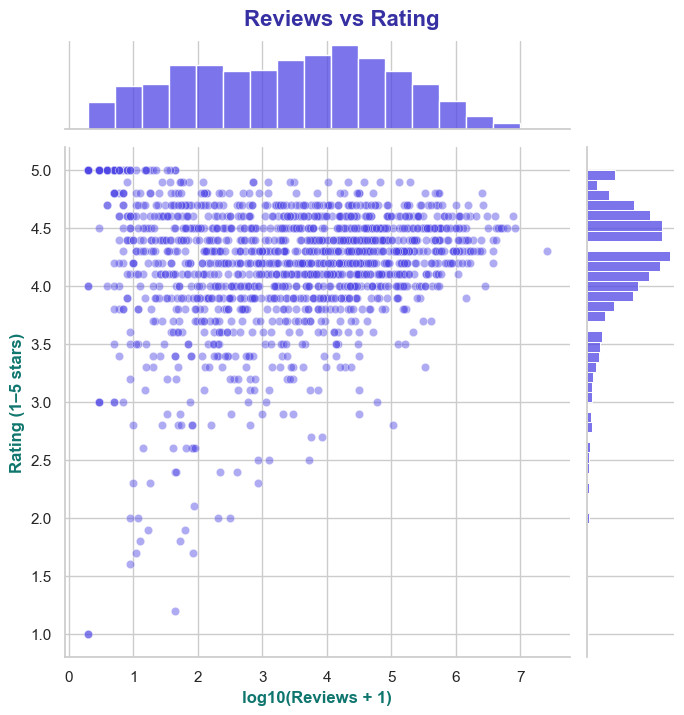

In [211]:
g = sns.jointplot(data=sample, x="Log_Reviews", y="Rating", alpha=0.45, height=7, color="#4F46E5")
g.set_axis_labels("log10(Reviews + 1)", "Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Reviews vs Rating", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S32_jointplot")

#### S33 · jointplot(kind='hex')
Hexagon bins — good for many points.

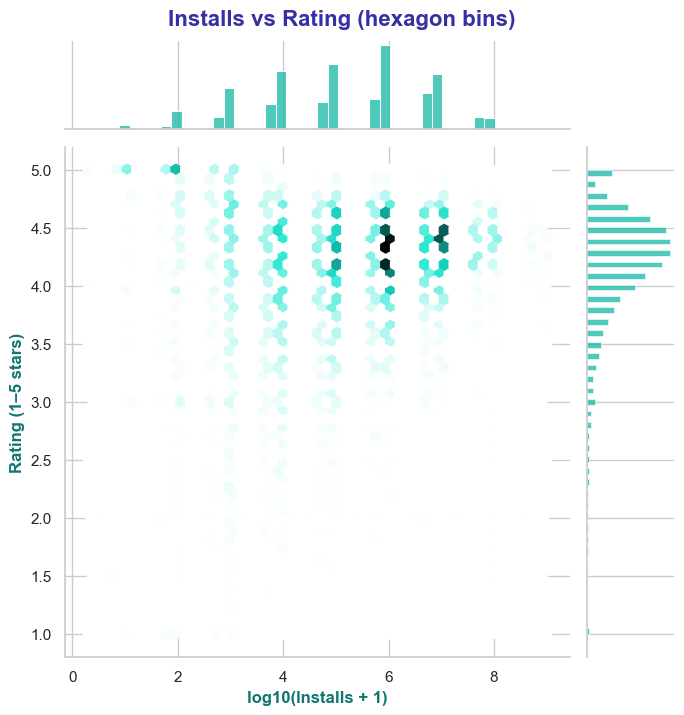

In [212]:
g = sns.jointplot(data=rated_s, x="Log_Installs", y="Rating", kind="hex", height=7, color="#14B8A6")
g.set_axis_labels("log10(Installs + 1)", "Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Installs vs Rating (hexagon bins)", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S33_jointplot_hex")

#### S34 · jointplot(kind='reg')
Regression line plus marginal distributions.

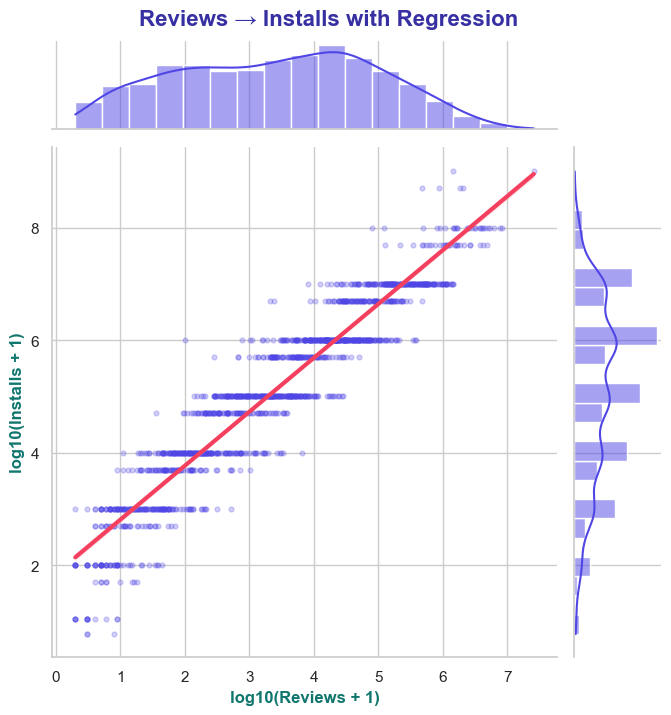

In [213]:
g = sns.jointplot(data=sample, x="Log_Reviews", y="Log_Installs", kind="reg", height=7, color="#4F46E5",
                  scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "#F43F5E", "linewidth": 3})
g.set_axis_labels("log10(Reviews + 1)", "log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Reviews → Installs with Regression", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S34_jointplot_reg")

#### S35 · JointGrid — build a joint plot yourself
More control: choose the centre and the margin plots separately.

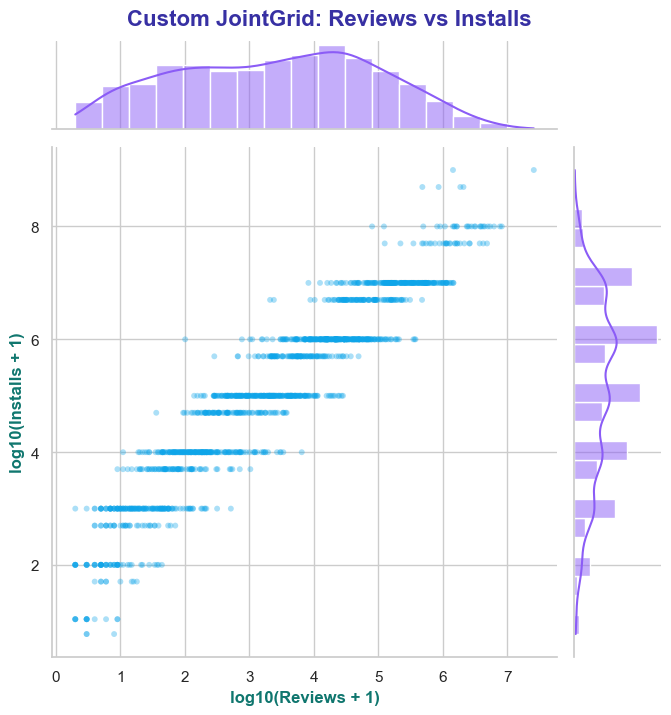

In [214]:
g = sns.JointGrid(data=sample, x="Log_Reviews", y="Log_Installs", height=7)
g.plot_joint(sns.scatterplot, alpha=0.35, color="#0EA5E9", s=18, edgecolor="none")
g.plot_marginals(sns.histplot, kde=True, color="#8B5CF6", edgecolor="white")
g.set_axis_labels("log10(Reviews + 1)", "log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Custom JointGrid: Reviews vs Installs", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S35_jointgrid")

### 4.5 Many variables at once

#### S36 · pairplot()
Every number column against every other.

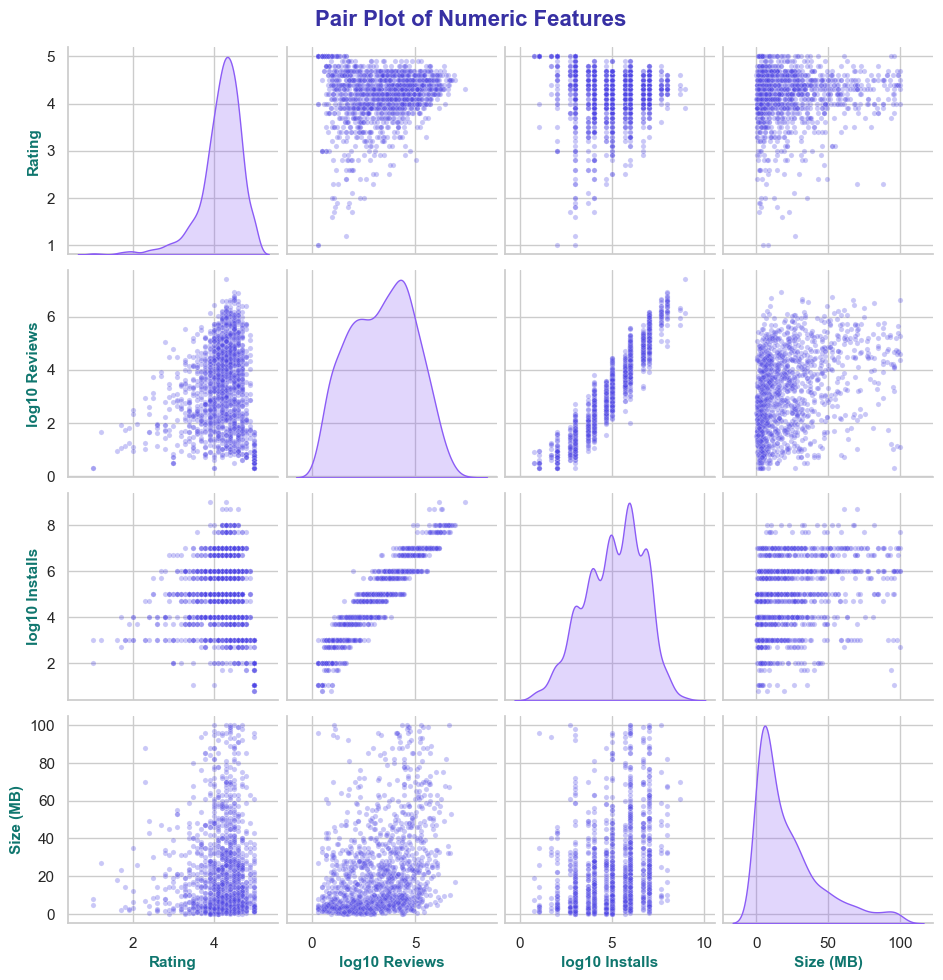

In [215]:
NICE = {"Rating": "Rating", "Log_Reviews": "log10 Reviews", "Log_Installs": "log10 Installs", "Size_MB": "Size (MB)"}
pp = sample[num_cols].rename(columns=NICE)
g = sns.pairplot(pp, diag_kind="kde", plot_kws={"alpha": 0.3, "s": 14, "color": "#4F46E5"},
                 diag_kws={"color": "#8B5CF6", "fill": True}, height=2.4)
for ax in g.axes.flat:
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), fontsize=11, fontweight="bold", color="#0F766E")
        ax.set_ylabel(ax.get_ylabel(), fontsize=11, fontweight="bold", color="#0F766E")
g.figure.suptitle("Pair Plot of Numeric Features", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S36_pairplot")

#### S37 · pairplot() with hue and corner=True
Colour by group and show only the lower triangle.

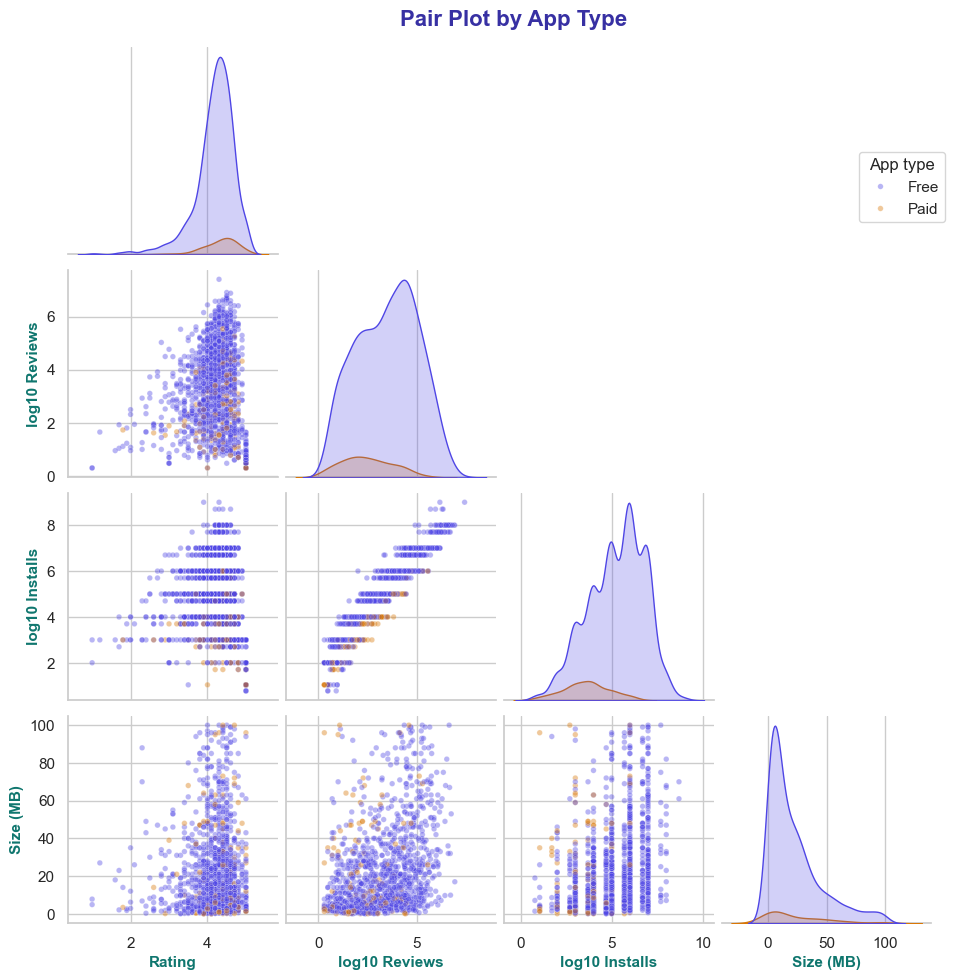

In [216]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

pp = sample[num_cols + ["Type"]].rename(columns=NICE).rename(columns={"Type": "App type"})
g = sns.pairplot(pp, hue="App type", palette=type_colors, corner=True, plot_kws={"alpha": 0.4, "s": 16}, height=2.4)
for ax in g.axes.flat:
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), fontsize=11, fontweight="bold", color="#0F766E")
        ax.set_ylabel(ax.get_ylabel(), fontsize=11, fontweight="bold", color="#0F766E")
g.figure.suptitle("Pair Plot by App Type", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
sns.move_legend(g, "upper right", bbox_to_anchor=(0.92, 0.88), title="App type", frameon=True)
save_fig("S37_pairplot_hue")

#### S38 · PairGrid — choose plots for each part
Scatter above the diagonal, density below, histogram on the diagonal.

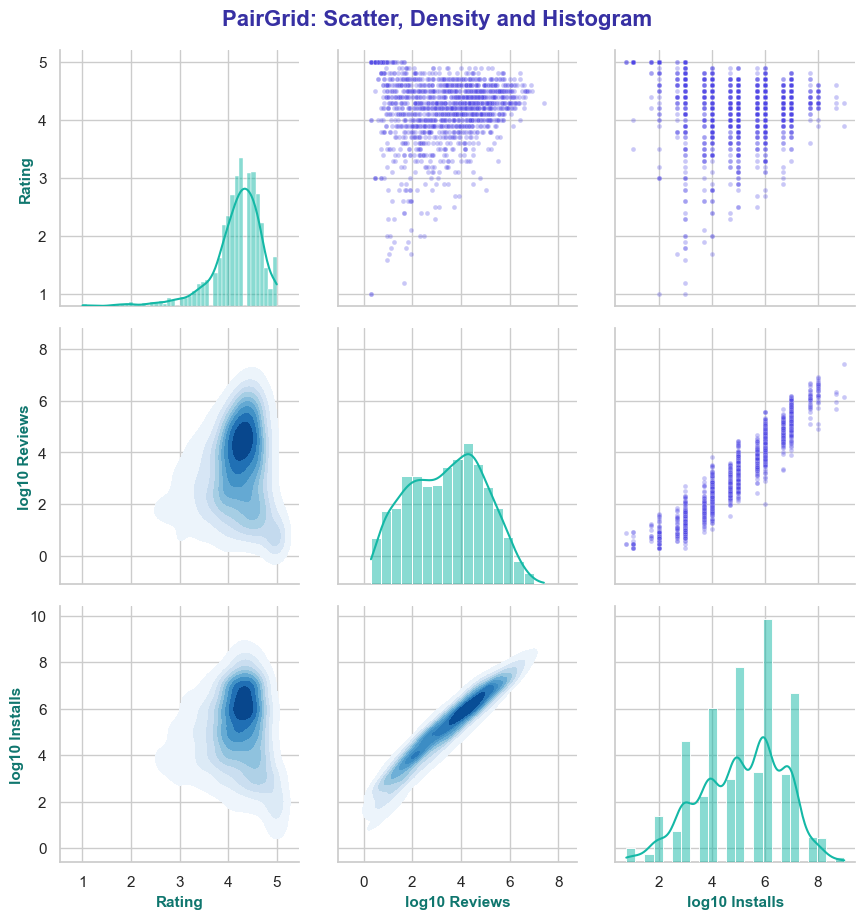

In [217]:
pg = sample[["Rating", "Log_Reviews", "Log_Installs"]].rename(columns=NICE)
g = sns.PairGrid(pg, height=3)
g.map_upper(sns.scatterplot, alpha=0.3, s=12, color="#4F46E5")
g.map_lower(sns.kdeplot, fill=True, cmap="Blues")
g.map_diag(sns.histplot, kde=True, color="#14B8A6", edgecolor="white")
for ax in g.axes.flat:
    if ax is not None:
        ax.set_xlabel(ax.get_xlabel(), fontsize=11, fontweight="bold", color="#0F766E")
        ax.set_ylabel(ax.get_ylabel(), fontsize=11, fontweight="bold", color="#0F766E")
g.figure.suptitle("PairGrid: Scatter, Density and Histogram", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S38_pairgrid")

#### S39 · heatmap() — correlations
Colours show how strongly columns are related.

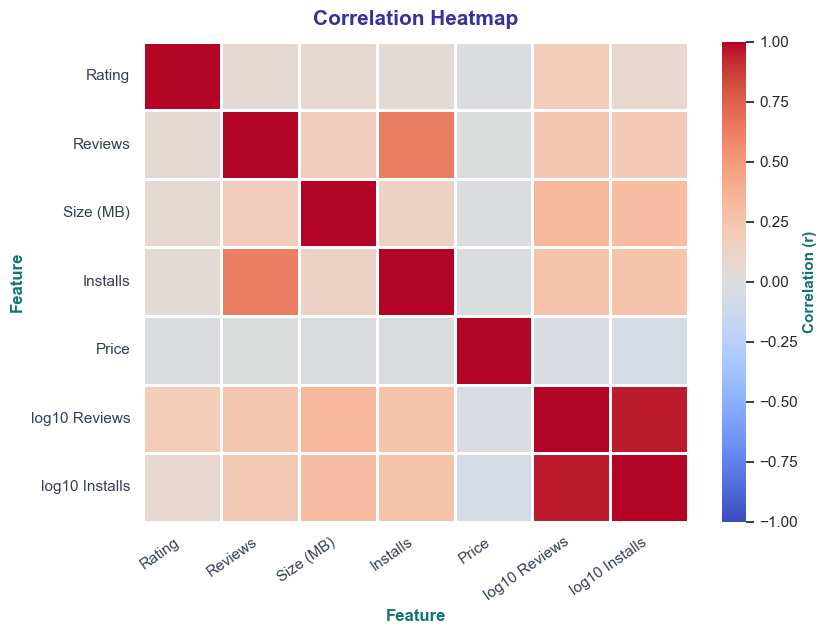

In [218]:
NICE_ALL = {"Rating": "Rating", "Reviews": "Reviews", "Size_MB": "Size (MB)", "Installs": "Installs", "Price": "Price",
            "Log_Reviews": "log10 Reviews", "Log_Installs": "log10 Installs"}
corr = dfs[list(NICE_ALL)].corr().rename(index=NICE_ALL, columns=NICE_ALL)
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=1, linecolor="white",
            cbar_kws={"label": "Correlation (r)"}, ax=ax)
cbar = ax.collections[0].colorbar
cbar.set_label("Correlation (r)", fontsize=11, fontweight="bold", color="#0F766E")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_title("Correlation Heatmap", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S39_heatmap")

#### S40 · heatmap() with numbers and a mask
`annot=True` writes numbers. A mask hides the repeated upper triangle.

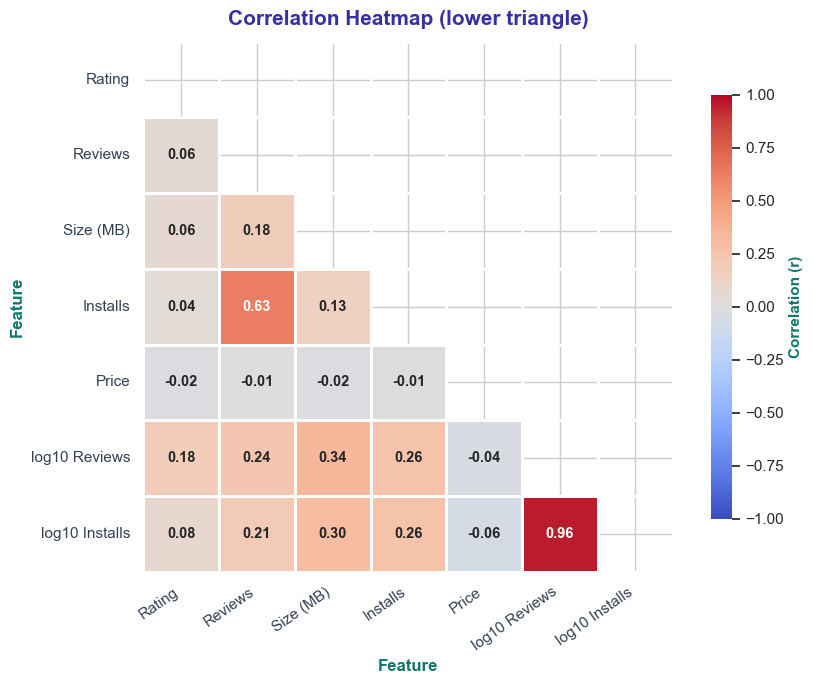

In [219]:
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, linewidths=1,
            linecolor="white", square=True, annot_kws={"fontsize": 10.5, "fontweight": "bold"},
            cbar_kws={"shrink": 0.8}, ax=ax)
cbar = ax.collections[0].colorbar
cbar.set_label("Correlation (r)", fontsize=11, fontweight="bold", color="#0F766E")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
ax.set_title("Correlation Heatmap (lower triangle)", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S40_heatmap_masked")

#### S41 · heatmap() of a pivot table
Average rating for every Category × Content Rating pair.

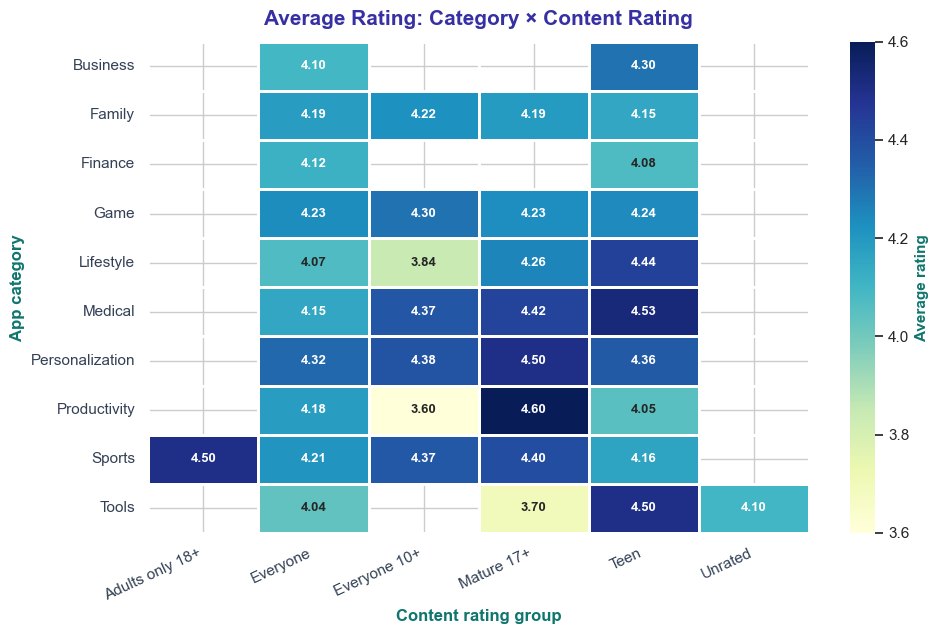

In [220]:
pv = rated_s[rated_s["Category"].isin(top10_list)].pivot_table(index="Category", columns="Content_Rating",
                                                               values="Rating", aggfunc="mean")
fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(pv, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=1, linecolor="white",
            annot_kws={"fontsize": 9.5, "fontweight": "bold"}, ax=ax)
cbar = ax.collections[0].colorbar
cbar.set_label("Average rating", fontsize=11, fontweight="bold", color="#0F766E")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
ax.set_title("Average Rating: Category × Content Rating", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Content rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S41_heatmap_pivot")

#### S42 · clustermap()
A heatmap whose rows and columns are grouped by similarity.

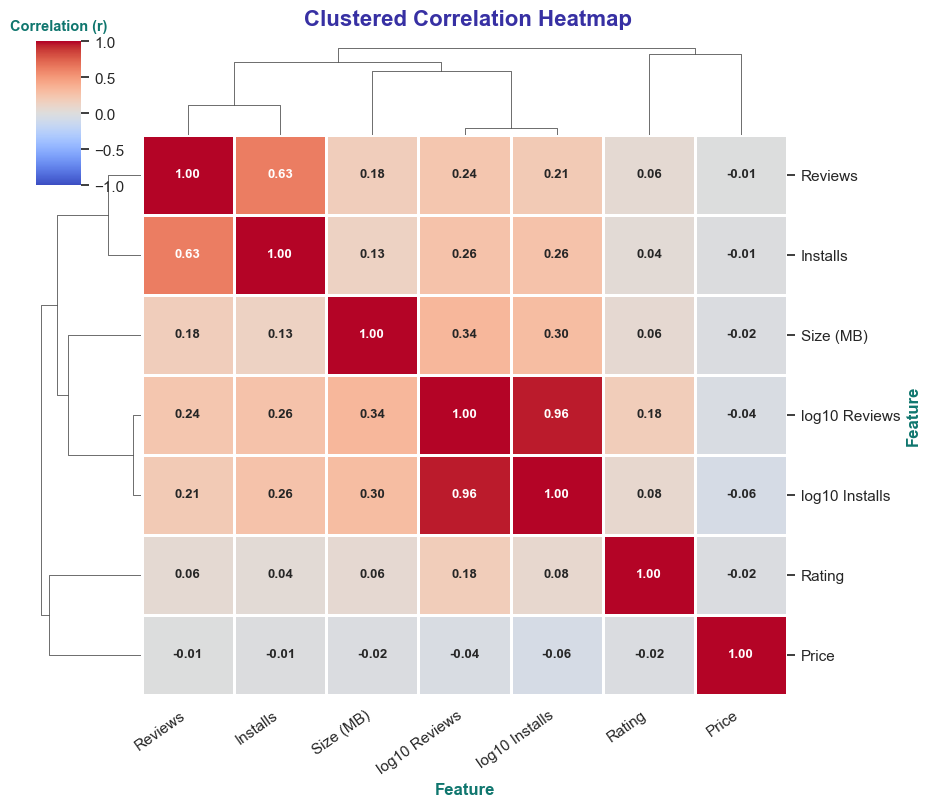

In [221]:
g = sns.clustermap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, figsize=(9, 8),
                   linewidths=1, linecolor="white", annot_kws={"fontsize": 9.5, "fontweight": "bold"},
                   dendrogram_ratio=0.14)
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=35, ha="right")
g.ax_heatmap.set_xlabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
g.ax_heatmap.set_ylabel("Feature", fontsize=12, fontweight="bold", color="#0F766E")
g.cax.set_ylabel("")
g.cax.set_title("Correlation (r)", fontsize=10.5, fontweight="bold", color="#0F766E", pad=8)
g.figure.suptitle("Clustered Correlation Heatmap", fontsize=16, fontweight="bold", color="#3730A3", y=1.02)
save_fig("S42_clustermap")

#### S43 · FacetGrid
Small multiples: one chart per category. `map_dataframe()` passes the sub-table to a plot function.

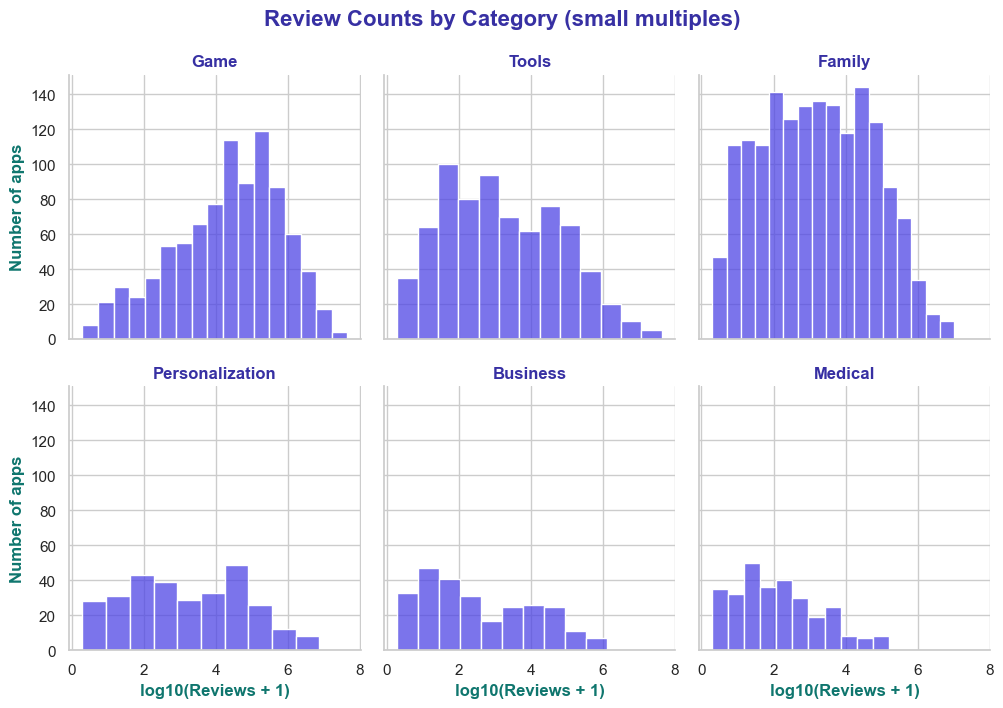

In [222]:
g = sns.FacetGrid(rated_s[rated_s["Category"].isin(top6_names)], col="Category", col_wrap=3, height=3.4)
g.map_dataframe(sns.histplot, x="Log_Reviews", color="#4F46E5", edgecolor="white")
g.set_titles("{col_name}", size=12, fontweight="bold", color="#3730A3")
g.set_axis_labels("log10(Reviews + 1)", "Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
g.figure.suptitle("Review Counts by Category (small multiples)", fontsize=16, fontweight="bold", color="#3730A3", y=1.04)
save_fig("S43_facetgrid")

### 4.6 Style and colour tools

#### S44 · Colour palettes
`sns.color_palette()` makes lists of colours. `palplot()` shows them.

deep


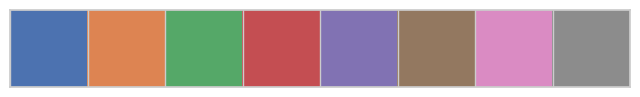

viridis


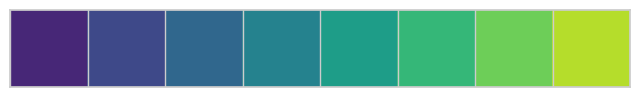

coolwarm


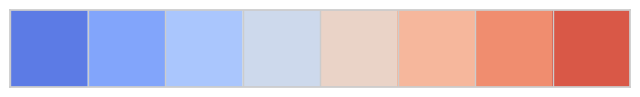

Set2


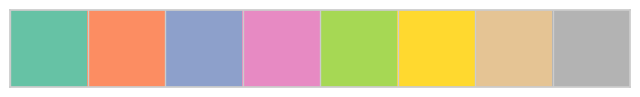

In [223]:
for name in ["deep", "viridis", "coolwarm", "Set2"]:
    print(name)
    sns.palplot(sns.color_palette(name, 8))
    plt.show()

#### S45 · set_context()
Make text bigger for slides (`talk`, `poster`) or smaller for papers (`paper`).

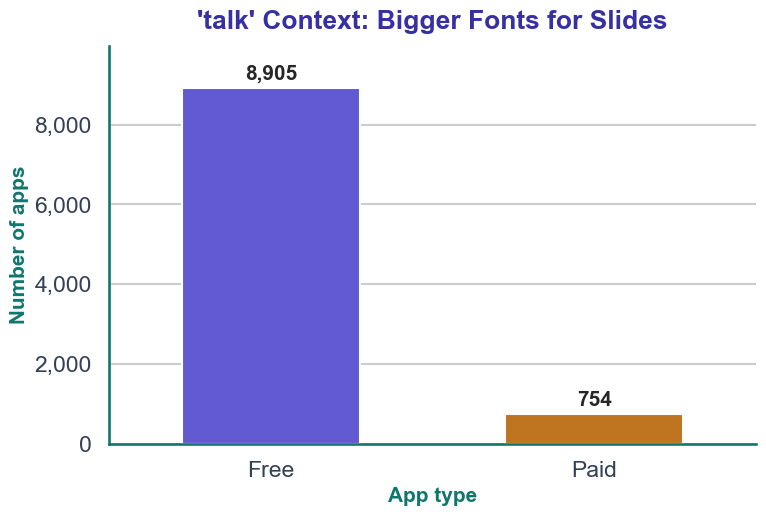

In [224]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

sns.set_context("talk")
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.countplot(data=dfs, x="Type", hue="Type", palette=type_colors, legend=False, width=0.55, edgecolor="white", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="{:,.0f}", padding=3, fontsize=15, fontweight="bold")
ax.margins(y=0.12)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("'talk' Context: Bigger Fonts for Slides", fontsize=19, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("App type", fontsize=15, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=15, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S45_context")
sns.set_context("notebook")          # back to normal


#### S46 · despine()
Remove top / right borders. `trim=True` shortens the axis lines to the data.

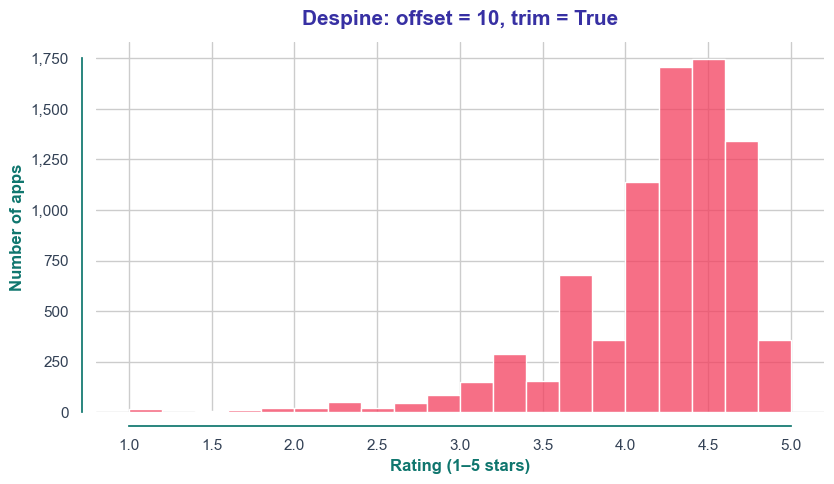

In [225]:
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.histplot(data=rated_s, x="Rating", bins=20, color="#F43F5E", edgecolor="white", ax=ax)
sns.despine(offset=10, trim=True)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Despine: offset = 10, trim = True", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating (1–5 stars)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S46_despine")

#### S47 · move_legend()
Put the legend outside the chart.

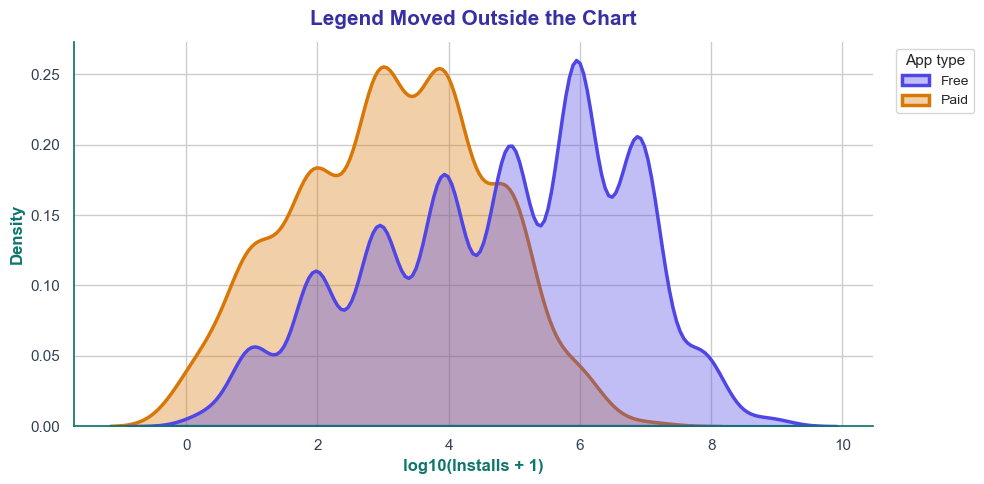

In [226]:
type_colors = {"Free": "#4F46E5", "Paid": "#D97706"}

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=dfs, x="Log_Installs", hue="Type", fill=True, common_norm=False, palette=type_colors,
            alpha=0.35, linewidth=2.5, ax=ax)
ax.set_title("Legend Moved Outside the Chart", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("log10(Installs + 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Density", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="App type",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S47_move_legend")

#### S48 · axes_style() — temporary style
Use a style only inside a `with` block.

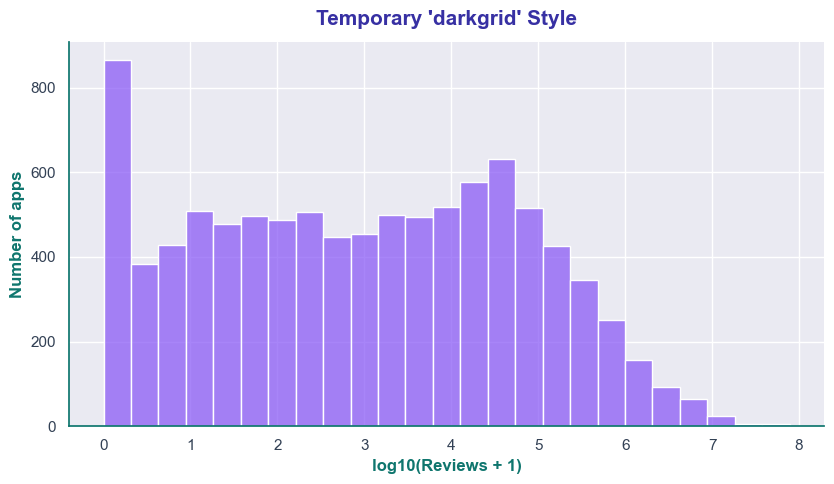

In [227]:
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(8.5, 5))
    sns.histplot(data=dfs, x="Log_Reviews", bins=25, color="#8B5CF6", edgecolor="white", ax=ax)
    ax.yaxis.set_major_formatter("{x:,.0f}")
    ax.set_title("Temporary 'darkgrid' Style", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
    ax.set_xlabel("log10(Reviews + 1)", fontsize=12, fontweight="bold", color="#0F766E")
    ax.set_ylabel("Number of apps", fontsize=12, fontweight="bold", color="#0F766E")
    ax.tick_params(axis="x", colors="#334155")
    ax.tick_params(axis="y", colors="#334155")
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#0F766E")
    plt.tight_layout()
    save_fig("S48_axes_style")

### 4.7 User reviews (second dataset)

#### S49 · countplot() — sentiment of reviews
How many reviews are positive, neutral or negative?

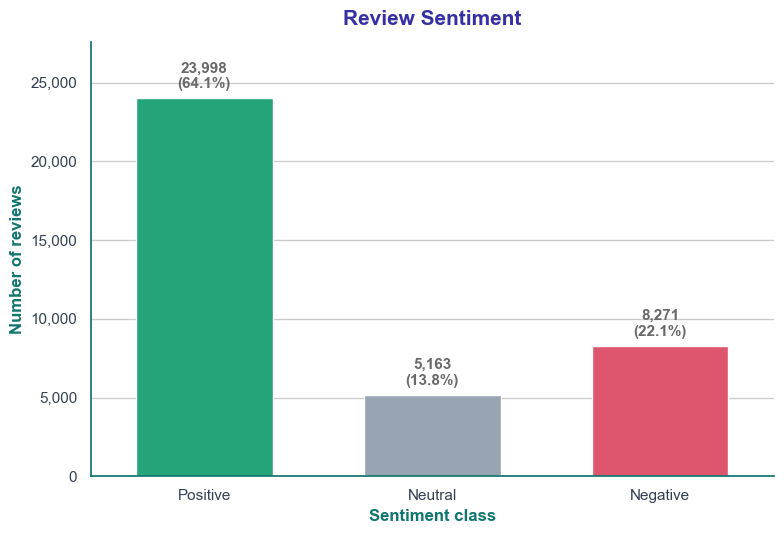

In [228]:
sent_colors = {"Positive": "#10B981", "Neutral": "#94A3B8", "Negative": "#F43F5E"}

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.countplot(data=reviews, x="Sentiment", order=["Positive", "Neutral", "Negative"], hue="Sentiment",
              legend=False, palette=sent_colors, width=0.6, edgecolor="white", ax=ax)
total = len(reviews)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{h:,.0f}\n({h / total:.1%})", (p.get_x() + p.get_width() / 2, h), xytext=(0, 5),
                    textcoords="offset points", ha="center", va="bottom", fontsize=11, fontweight="bold", color="dimgray")
ax.margins(y=0.15)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Review Sentiment", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Sentiment class", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of reviews", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S49_sentiment_count")

#### S50 · histplot() — polarity by sentiment
Polarity goes from −1 (very negative) to +1 (very positive).

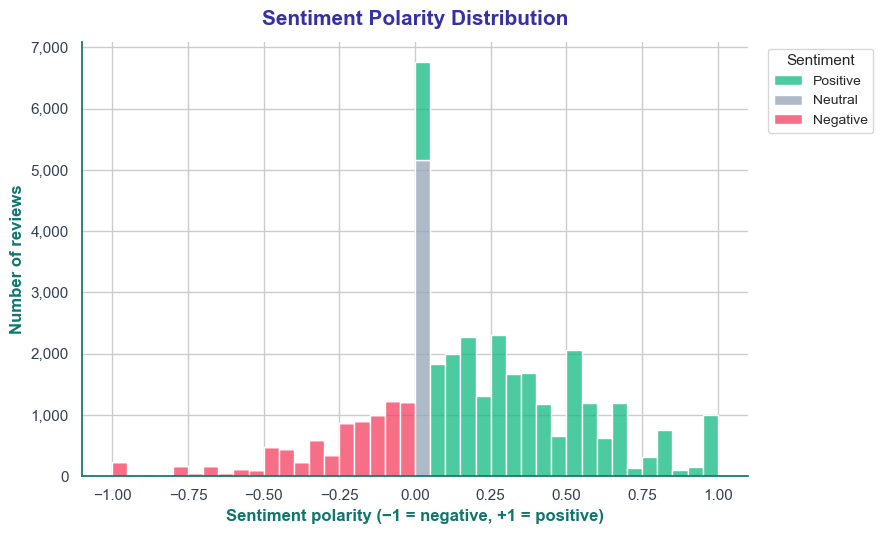

In [229]:
sent_colors = {"Positive": "#10B981", "Neutral": "#94A3B8", "Negative": "#F43F5E"}

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.histplot(data=reviews, x="Sentiment_Polarity", hue="Sentiment", bins=40, multiple="stack",
             hue_order=["Positive", "Neutral", "Negative"], palette=sent_colors, edgecolor="white", ax=ax)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set_title("Sentiment Polarity Distribution", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Sentiment polarity (−1 = negative, +1 = positive)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Number of reviews", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S50_polarity_hist")

#### S51 · scatterplot() — polarity vs subjectivity
Subjective reviews (opinions) tend to be more extreme.

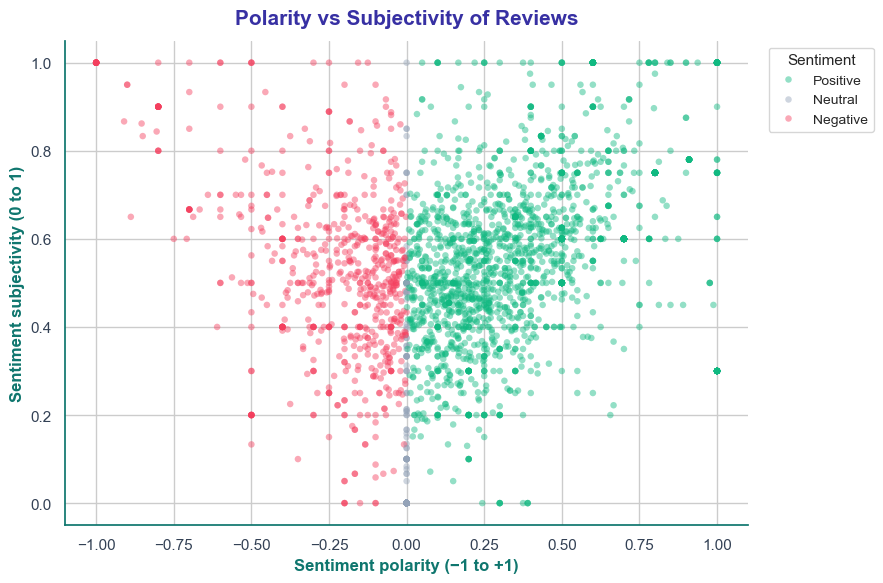

In [230]:
sent_colors = {"Positive": "#10B981", "Neutral": "#94A3B8", "Negative": "#F43F5E"}

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=reviews.sample(3000, random_state=5), x="Sentiment_Polarity", y="Sentiment_Subjectivity",
                hue="Sentiment", hue_order=["Positive", "Neutral", "Negative"], palette=sent_colors,
                alpha=0.45, s=22, edgecolor="none", ax=ax)
ax.set_title("Polarity vs Subjectivity of Reviews", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Sentiment polarity (−1 to +1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Sentiment subjectivity (0 to 1)", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
sns.move_legend(
    ax,
    "upper left",
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    fontsize=10,
    title_fontsize=11,
    fancybox=True,
)
plt.tight_layout()
save_fig("S51_polarity_subjectivity")

#### S52 · boxplot() — does sentiment match the star rating?
Using the merged table: apps with higher ratings should get happier reviews.

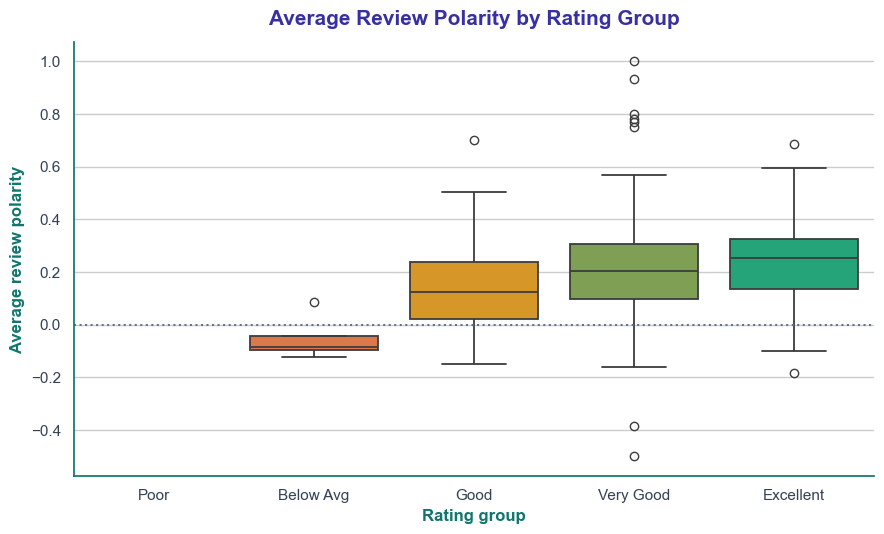

In [231]:
rating_order = ["Poor", "Below Avg", "Good", "Very Good", "Excellent"]
rating_colors = {"Poor": "#F43F5E", "Below Avg": "#F56F34", "Good": "#F49E0B", "Very Good": "#81AC47", "Excellent": "#10B981"}

m2 = merged.copy()
m2["Rating_Group"] = m2["Rating_Group"].astype(str)
m2 = m2[m2["Rating_Group"].isin(rating_order)]
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=m2, x="Rating_Group", y="Avg_Polarity", order=rating_order, hue="Rating_Group",
            hue_order=rating_order, legend=False, palette=rating_colors, linewidth=1.3, ax=ax)
ax.axhline(0, color="#64748B", linestyle=":", linewidth=1.5)
ax.set_title("Average Review Polarity by Rating Group", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Rating group", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("Average review polarity", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S52_polarity_by_rating")

#### S53 · barplot() — happiest categories
Mean review polarity per category for the biggest categories.

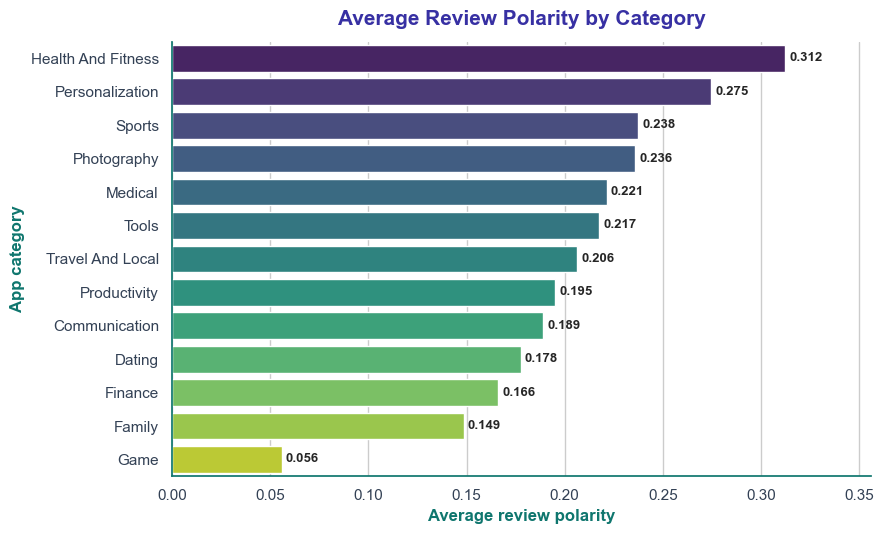

In [232]:
m3 = merged.copy()
m3["Category"] = m3["Category"].astype(str)
big = m3["Category"].value_counts()
big = big[big >= 30].index
sub3 = m3[m3["Category"].isin(big)]
order3 = sub3.groupby("Category")["Avg_Polarity"].mean().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(data=sub3, x="Avg_Polarity", y="Category", errorbar=None, order=order3, hue="Category", hue_order=order3,
            palette=sns.color_palette("viridis", len(order3)), legend=False, edgecolor="white", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="{:.3f}", padding=3, fontsize=9.5, fontweight="bold")
ax.margins(x=0.14)
ax.set_title("Average Review Polarity by Category", fontsize=15, fontweight="bold", color="#3730A3", pad=12)
ax.set_xlabel("Average review polarity", fontsize=12, fontweight="bold", color="#0F766E")
ax.set_ylabel("App category", fontsize=12, fontweight="bold", color="#0F766E")
ax.tick_params(axis="x", colors="#334155")
ax.tick_params(axis="y", colors="#334155")
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#0F766E")
plt.tight_layout()
save_fig("S53_polarity_category")

✅ **Seaborn section finished.**

---
# 5. 🧾 Key findings
The numbers below are calculated from the data, so they always match the analysis above.

In [233]:
free_share = (df["Type"] == "Free").mean() * 100
cat_top = df["Category"].value_counts().head(3)
best_cat = (df.groupby("Category", observed=True)
              .filter(lambda g: len(g) >= 50)
              .groupby("Category", observed=True)["Rating"].mean().sort_values(ascending=False).head(3))
corr_ri = np.corrcoef(df["Log_Reviews"], df["Log_Installs"])[0, 1]
paid_rev = df.nlargest(3, "Est_Revenue")[["App", "Est_Revenue"]]

print(f"1. After cleaning we have {len(df):,} unique apps in {df['Category'].nunique()} categories.")
print(f"2. {free_share:.1f}% of apps are free.")
print("3. Biggest categories:", ", ".join(f"{c} ({n})" for c, n in cat_top.items()))
print("4. Average rating of all apps:", round(df["Rating"].mean(), 2), "| median:", df["Rating"].median())
print("5. Highest average rating (categories with 50+ apps):", ", ".join(f"{c} ({r:.2f})" for c, r in best_cat.items()))
print(f"6. Reviews and installs are strongly related (log-log correlation = {corr_ri:.2f}).")
print(f"7. Median size of an app: {df['Size_MB'].median():.1f} MB.")
print(f"8. Paid apps average rating {df.loc[df['Type']=='Paid','Rating'].mean():.2f} vs free apps {df.loc[df['Type']=='Free','Rating'].mean():.2f}.")
print("9. Top estimated revenue (price × installs):", "; ".join(f"{a} (${r:,.0f})" for a, r in paid_rev.values))
print(f"10. {(reviews['Sentiment']=='Positive').mean()*100:.1f}% of user reviews are positive.")

1. After cleaning we have 9,659 unique apps in 33 categories.
2. 92.2% of apps are free.
3. Biggest categories: Family (1878), Game (945), Tools (829)
4. Average rating of all apps: 4.17 | median: 4.3
5. Highest average rating (categories with 50+ apps): Events (4.44), Art And Design (4.36), Education (4.35)
6. Reviews and installs are strongly related (log-log correlation = 0.96).
7. Median size of an app: 12.0 MB.
8. Paid apps average rating 4.26 vs free apps 4.17.
9. Top estimated revenue (price × installs): Minecraft ($69,900,000); I am rich ($39,999,000); I Am Rich Premium ($19,999,500)
10. 64.1% of user reviews are positive.


###### What we practised
| Library | Operations in this notebook |
|---|---|
| pandas | **80** |
| numpy | **52** |
| matplotlib | **44** |
| seaborn | **53** |
